# Trajectory Sampling Stability Validation

This notebook evaluates how trajectory subsampling affects regional cortical depth-resolved ADC profiles.

For each cortical region, the profile calculated using all available trajectories is used as the full-sampling reference. Reduced trajectory sets are randomly sampled and used to reconstruct the regional ADC profile.

The analysis evaluates:

- profile shape similarity using Pearson correlation
- absolute profile difference using MAE
- profile error using RMSE

The main comparison includes S00775 and D0007. An additional S00775 reconstruction is analyzed separately for validation.

## 1. Configuration

All input paths and analysis parameters are defined here so that the notebook can later be extended to additional subjects or datasets without changing the analysis code.

In [203]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import matplotlib.pyplot as plt


PATHS = {
    "S00775": {
        "root": Path(
            "/mnt/newStor/paros/paros_WORK/xintong/test/"
            "existing_pipeline_cross_contrast/output/S00775"
        ),
        "style": "existing",
        "file_subject": "S00775",
    },

    "D0007": {
        "root": Path(
            "/mnt/newStor/paros/paros_WORK/xintong/test/"
            "new_pipeline/D0007/analysis/profiles"
        ),
        "style": "new",
        "file_subject": "D0007",
    },

    "S00775_new": {
        "root": Path(
            "/mnt/newStor/paros/paros_WORK/xintong/test/"
            "new_pipeline/S00775/analysis/profiles"
        ),
        "style": "new",
        "file_subject": "S00775",
    },
}

MAIN_SUBJECTS = [
    "S00775",
    "D0007",
]

SEPARATE_SUBJECTS = [
    "S00775_new",
]

CONTRASTS = [
    "adc",
    "fa",
    "rd",
    "ad",
]

SAMPLING_FRACTIONS = [
    0.01,
    0.02,
    0.03,
    0.04,
    0.05,
    0.10,
    0.25,
    0.50,
    0.75,
    1.00,
]

N_REPEATS = 100
RANDOM_SEED = 42

In [204]:
def get_profile_path(
    subject,
    hemisphere,
    region,
    contrast,
):
    config = PATHS[subject]
    file_subject = config["file_subject"]

    if config["style"] == "existing":
        return (
            config["root"]
            / contrast
            / f"{contrast}_cols_by_column"
            / (
                f"{file_subject}_{hemisphere}_{region}"
                f"_cols_{contrast}.csv"
            )
        )

    return (
        config["root"]
        / (
            f"{file_subject}_{hemisphere}_{region}"
            f"_{contrast}.csv"
        )
    )

## Data Check

Load the regional trajectory profiles and summarize the number of trajectories available in each cortical region.

In [205]:
def get_profile_files(
    subject,
    contrast,
):
    config = PATHS[subject]
    file_subject = config["file_subject"]

    if config["style"] == "existing":

        profile_dir = (
            config["root"]
            / contrast
            / f"{contrast}_cols_by_column"
        )

        pattern = (
            f"{file_subject}_*_cols_{contrast}.csv"
        )

    else:

        profile_dir = config["root"]

        pattern = (
            f"{file_subject}_*_{contrast}.csv"
        )

    return sorted(
        profile_dir.glob(pattern)
    )


def load_profile(file_path):
    values = np.loadtxt(
        file_path,
        delimiter=",",
    )

    if values.ndim == 1:
        values = values.reshape(
            1,
            -1,
        )

    return values


column_counts = []

for subject in MAIN_SUBJECTS:

    for contrast in CONTRASTS:

        files = get_profile_files(
            subject,
            contrast,
        )

        print(
            f"{subject} {contrast}: "
            f"{len(files)} profile files"
        )

        for file_path in files:

            file_subject = (
                PATHS[subject][
                    "file_subject"
                ]
            )

            if (
                PATHS[subject]["style"]
                == "existing"
            ):
                suffix = (
                    f"_cols_{contrast}.csv"
                )
            else:
                suffix = (
                    f"_{contrast}.csv"
                )

            region_label = (
                file_path.name[
                    len(file_subject) + 1:
                    -len(suffix)
                ]
            )

            hemisphere, region = (
                region_label.split(
                    "_",
                    1,
                )
            )

            values = load_profile(
                file_path
            )

            column_counts.append(
                {
                    "subject": subject,
                    "contrast": contrast,
                    "hemisphere": hemisphere,
                    "region": region,
                    "total_columns": values.shape[0],
                    "n_depth_points": values.shape[1],
                }
            )


column_counts_df = pd.DataFrame(
    column_counts
)


column_count_summary_df = (
    column_counts_df
    .groupby(
        [
            "subject",
            "contrast",
        ]
    )["total_columns"]
    .agg(
        n_regions="count",
        minimum="min",
        median="median",
        mean="mean",
        maximum="max",
    )
    .reset_index()
)


column_count_summary_df

S00775 adc: 68 profile files
S00775 fa: 68 profile files
S00775 rd: 68 profile files
S00775 ad: 68 profile files
D0007 adc: 68 profile files
D0007 fa: 68 profile files
D0007 rd: 68 profile files
D0007 ad: 68 profile files


,subject,contrast,n_regions,minimum,median,mean,maximum
0,D0007,ad,68,322,2889.5,3276.926471,9163
1,D0007,adc,68,322,2889.5,3276.926471,9163
2,D0007,fa,68,322,2889.5,3276.926471,9163
3,D0007,rd,68,322,2889.5,3276.926471,9163
4,S00775,ad,68,338,2722.0,3364.544118,9265
5,S00775,adc,68,338,2722.0,3364.544118,9265
6,S00775,fa,68,338,2722.0,3364.544118,9265
7,S00775,rd,68,338,2722.0,3364.544118,9265


## Percentage Sampling

Randomly sample 5%, 10%, 25%, 50%, and 75% of trajectories in each cortical region.

Each sampling level is repeated 100 times and compared with the full regional ADC profile.

In [206]:
def compare_profiles(
    sample_profile,
    full_profile,
):
    mae = np.mean(
        np.abs(
            sample_profile
            - full_profile
        )
    )

    rmse = np.sqrt(
        np.mean(
            (
                sample_profile
                - full_profile
            ) ** 2
        )
    )

    mean_signal = np.mean(
        np.abs(full_profile)
    )

    if mean_signal == 0:
        relative_mae = np.nan
    else:
        relative_mae = (
            mae
            / mean_signal
            * 100
        )

    if (
        np.std(sample_profile) == 0
        or np.std(full_profile) == 0
    ):
        correlation = np.nan
    else:
        correlation = pearsonr(
            sample_profile,
            full_profile,
        )[0]

    return (
        mae,
        rmse,
        relative_mae,
        correlation,
    )


rng = np.random.default_rng(
    RANDOM_SEED
)

sampling_results = []


for subject in MAIN_SUBJECTS:

    subject_fractions = (
        SAMPLING_FRACTIONS
    )

    for contrast in CONTRASTS:

        file_subject = (
            PATHS[subject][
                "file_subject"
            ]
        )

        for file_path in get_profile_files(
            subject,
            contrast,
        ):

            if (
                PATHS[subject]["style"]
                == "existing"
            ):
                suffix = (
                    f"_cols_{contrast}.csv"
                )
            else:
                suffix = (
                    f"_{contrast}.csv"
                )

            region_label = (
                file_path.name[
                    len(file_subject) + 1:
                    -len(suffix)
                ]
            )

            hemisphere, region = (
                region_label.split(
                    "_",
                    1,
                )
            )

            values = load_profile(
                file_path
            )

            total_columns = (
                values.shape[0]
            )

            full_profile = values.mean(
                axis=0
            )

            for fraction in (
                subject_fractions
            ):

                sample_n = max(
                    1,
                    round(
                        total_columns
                        * fraction
                    ),
                )

                for repeat in range(
                    N_REPEATS
                ):

                    indices = rng.choice(
                        total_columns,
                        size=sample_n,
                        replace=False,
                    )

                    sample_profile = (
                        values[
                            indices
                        ]
                        .mean(
                            axis=0
                        )
                    )

                    (
                        mae,
                        rmse,
                        relative_mae,
                        correlation,
                    ) = compare_profiles(
                        sample_profile,
                        full_profile,
                    )

                    sampling_results.append(
                        {
                            "subject": subject,
                            "contrast": contrast,
                            "hemisphere": hemisphere,
                            "region": region,
                            "sampling_fraction": fraction,
                            "sample_n": sample_n,
                            "total_columns": total_columns,
                            "repeat": repeat,
                            "mae": mae,
                            "rmse": rmse,
                            "relative_mae": relative_mae,
                            "correlation": correlation,
                        }
                    )


sampling_results_df = pd.DataFrame(
    sampling_results
)

sampling_results_df.head()

,subject,contrast,hemisphere,region,sampling_fraction,sample_n,total_columns,repeat,mae,rmse,relative_mae,correlation
0,S00775,adc,lh,bankssts,0.01,15,1541,0,0.000044,0.000050,5.420179,0.984795
1,S00775,adc,lh,bankssts,0.01,15,1541,1,0.000015,0.000017,1.815593,0.999525
2,S00775,adc,lh,bankssts,0.01,15,1541,2,0.000030,0.000036,3.697153,0.993280
3,S00775,adc,lh,bankssts,0.01,15,1541,3,0.000013,0.000016,1.640899,0.998719
4,S00775,adc,lh,bankssts,0.01,15,1541,4,0.000038,0.000042,4.648270,0.981645


## Least Stable Regions

Regions with the lowest median profile correlation are identified at each sampling level.

In [207]:
region_summary_df = (
    sampling_results_df
    .groupby(
        [
            "subject",
            "contrast",
            "hemisphere",
            "region",
            "sampling_fraction",
        ]
    )
    .agg(
        sample_n=(
            "sample_n",
            "first",
        ),
        median_mae=(
            "mae",
            "median",
        ),
        median_relative_mae=(
            "relative_mae",
            "median",
        ),
        median_rmse=(
            "rmse",
            "median",
        ),
        median_correlation=(
            "correlation",
            "median",
        ),
        p10_correlation=(
            "correlation",
            lambda x: x.quantile(
                0.10
            ),
        ),
    )
    .reset_index()
)

least_stable_regions_df = (
    region_summary_df
    .sort_values(
        [
            "subject",
            "contrast",
            "sampling_fraction",
            "median_correlation",
        ]
    )
    .groupby(
        [
            "subject",
            "contrast",
            "sampling_fraction",
        ]
    )
    .head(10)
)


for subject in least_stable_regions_df["subject"].unique():

    for fraction in sorted(
        least_stable_regions_df["sampling_fraction"].unique()
    ):

        subset = least_stable_regions_df[
            (least_stable_regions_df["subject"] == subject)
            & (least_stable_regions_df["sampling_fraction"] == fraction)
        ]

        print(
            f"\n{subject} - {int(fraction * 100)}%"
        )

        display(
            subset[
                [
                    "hemisphere",
                    "region",
                    "sample_n",
                    "median_mae",
                    "median_correlation",
                ]
            ]
        )


D0007 - 1%


,hemisphere,region,sample_n,median_mae,median_correlation
380,rh,entorhinal,7,0.000127,0.943949
50,lh,frontalpole,3,0.000095,0.965772
10,lh,caudalanteriorcingulate,8,0.000082,0.973691
100,lh,isthmuscingulate,13,0.000068,0.973838
390,rh,frontalpole,4,0.000059,0.974245
230,lh,posteriorcingulate,15,0.000057,0.976510
40,lh,entorhinal,7,0.000103,0.978634
320,lh,temporalpole,6,0.000087,0.984824
340,rh,bankssts,11,0.000047,0.986754
510,rh,parahippocampal,9,0.000071,0.987076



D0007 - 2%


,hemisphere,region,sample_n,median_mae,median_correlation
381,rh,entorhinal,13,0.000107,0.981816
101,lh,isthmuscingulate,26,0.000040,0.985723
51,lh,frontalpole,6,0.000077,0.985963
11,lh,caudalanteriorcingulate,16,0.000063,0.986395
391,rh,frontalpole,8,0.000042,0.988099
41,lh,entorhinal,13,0.000072,0.988486
231,lh,posteriorcingulate,30,0.000037,0.990054
321,lh,temporalpole,12,0.000073,0.992572
511,rh,parahippocampal,19,0.000049,0.993413
441,rh,isthmuscingulate,29,0.000057,0.993881



D0007 - 3%


,hemisphere,region,sample_n,median_mae,median_correlation
382,rh,entorhinal,20,0.000080,0.985658
392,rh,frontalpole,11,0.000035,0.988674
102,lh,isthmuscingulate,39,0.000040,0.990661
232,lh,posteriorcingulate,45,0.000031,0.991690
12,lh,caudalanteriorcingulate,25,0.000040,0.991704
52,lh,frontalpole,10,0.000055,0.992430
42,lh,entorhinal,20,0.000063,0.993001
322,lh,temporalpole,19,0.000060,0.993488
172,lh,parahippocampal,30,0.000032,0.995363
342,rh,bankssts,33,0.000031,0.996144


... (30 outputs left out)


S00775 - 75%


,hemisphere,region,sample_n,median_mae,median_correlation
3108,rh,entorhinal,368,0.000009,0.915997
3148,rh,inferiortemporal,2722,0.000004,0.970745
2768,lh,entorhinal,439,0.000010,0.990014
3328,rh,rostralanteriorcingulate,621,0.000007,0.993314
2778,lh,frontalpole,254,0.000010,0.996457
2988,lh,rostralanteriorcingulate,742,0.000008,0.997348
2808,lh,inferiortemporal,2939,0.000003,0.997667
3388,rh,temporalpole,394,0.000014,0.998698
3238,rh,parahippocampal,574,0.000008,0.998723
2828,lh,isthmuscingulate,970,0.000008,0.999005



S00775 - 100%


,hemisphere,region,sample_n,median_mae,median_correlation
2809,lh,inferiortemporal,3919,1.693421e-18,1.0
2969,lh,precentral,6716,2.475595e-18,1.0
2759,lh,cuneus,2103,1.249414e-18,1.0
2799,lh,inferiorparietal,5633,2.090961e-18,1.0
2839,lh,lateraloccipital,6667,1.791515e-18,1.0
2899,lh,parahippocampal,880,9.757820e-19,1.0
3079,rh,caudalanteriorcingulate,1069,1.053225e-18,1.0
3089,rh,caudalmiddlefrontal,2957,1.548860e-18,1.0
3199,rh,lingual,4265,1.936075e-18,1.0
3209,rh,medialorbitofrontal,2633,1.791515e-18,1.0


## Regional Sampling Stability Heatmap

Median profile correlation is shown for each cortical region across sampling fractions.

The main heatmaps compare S00775 and D0007. The new S00775 result is shown separately.

In [238]:
def plot_subject_contrast_heatmaps(
    subject,
    fractions,
    scale_label,
):
    contrasts = [
        "adc",
        "fa",
        "rd",
        "ad",
    ]

    subject_df = region_summary_df[
        (
            region_summary_df["subject"]
            == subject
        )
        &
        (
            region_summary_df[
                "sampling_fraction"
            ].isin(fractions)
        )
    ].copy()

    region_order = sorted(
        subject_df["region"].unique()
    )

    fig, axes = plt.subplots(
        1,
        len(contrasts),
        figsize=(20, 16),
        sharey=True,
    )

    image = None

    for ax, contrast in zip(
        axes,
        contrasts,
    ):
        contrast_df = subject_df[
            subject_df["contrast"]
            == contrast
        ].copy()

        heatmap_df = (
            contrast_df
            .pivot_table(
                index="region",
                columns="sampling_fraction",
                values="median_correlation",
                aggfunc="mean",
            )
            .reindex(
                index=region_order,
                columns=fractions,
            )
        )

        image = ax.imshow(
            heatmap_df.values,
            aspect="auto",
            vmin=0.9,
            vmax=1,
        )

        ax.set_xticks(
            range(len(fractions))
        )

        ax.set_xticklabels(
            [
                f"{int(x * 100)}%"
                for x in fractions
            ]
        )

        # Contrast shown below each panel
        ax.set_xlabel(
            contrast.upper(),
            fontsize=13,
            fontweight="bold",
            labelpad=12,
        )

        if ax is axes[0]:
            ax.set_yticks(
                range(len(region_order))
            )

            ax.set_yticklabels(
                region_order,
                fontsize=8,
            )

            ax.set_ylabel(
                "Cortical region"
            )

        else:
            ax.tick_params(
                axis="y",
                left=False,
                labelleft=False,
            )

    fig.suptitle(
        (
            f"{subject} Regional Sampling Stability "
            f"({scale_label})"
        ),
        fontsize=25,
        y=0.995,
    )

    cbar = fig.colorbar(
        image,
        ax=axes,
        fraction=0.02,
        pad=0.02,
    )

    cbar.set_label(
        "Median Pearson correlation"
    )

    plt.show()

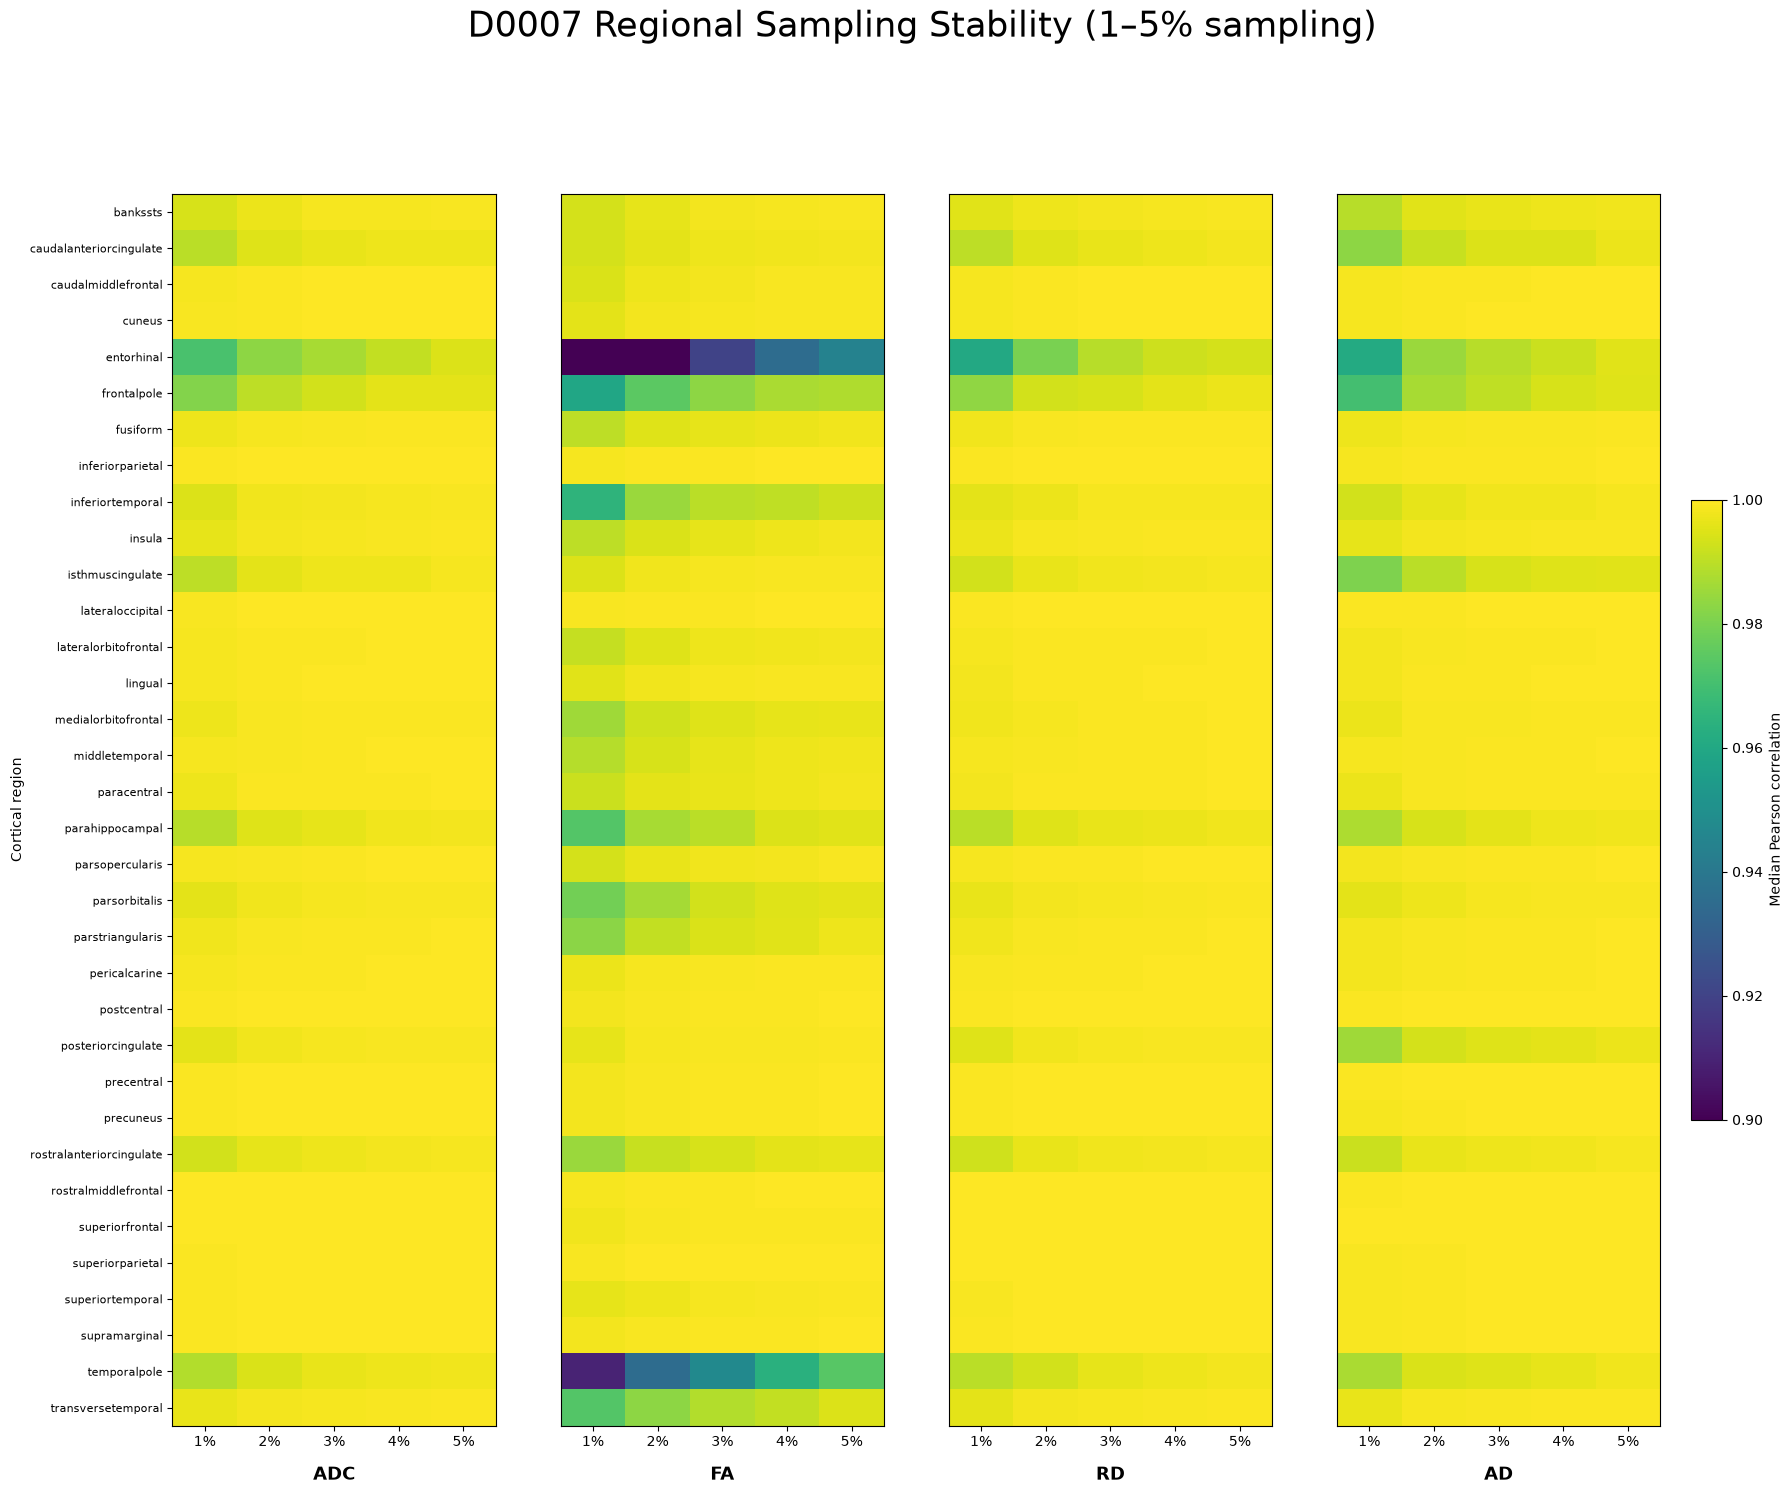

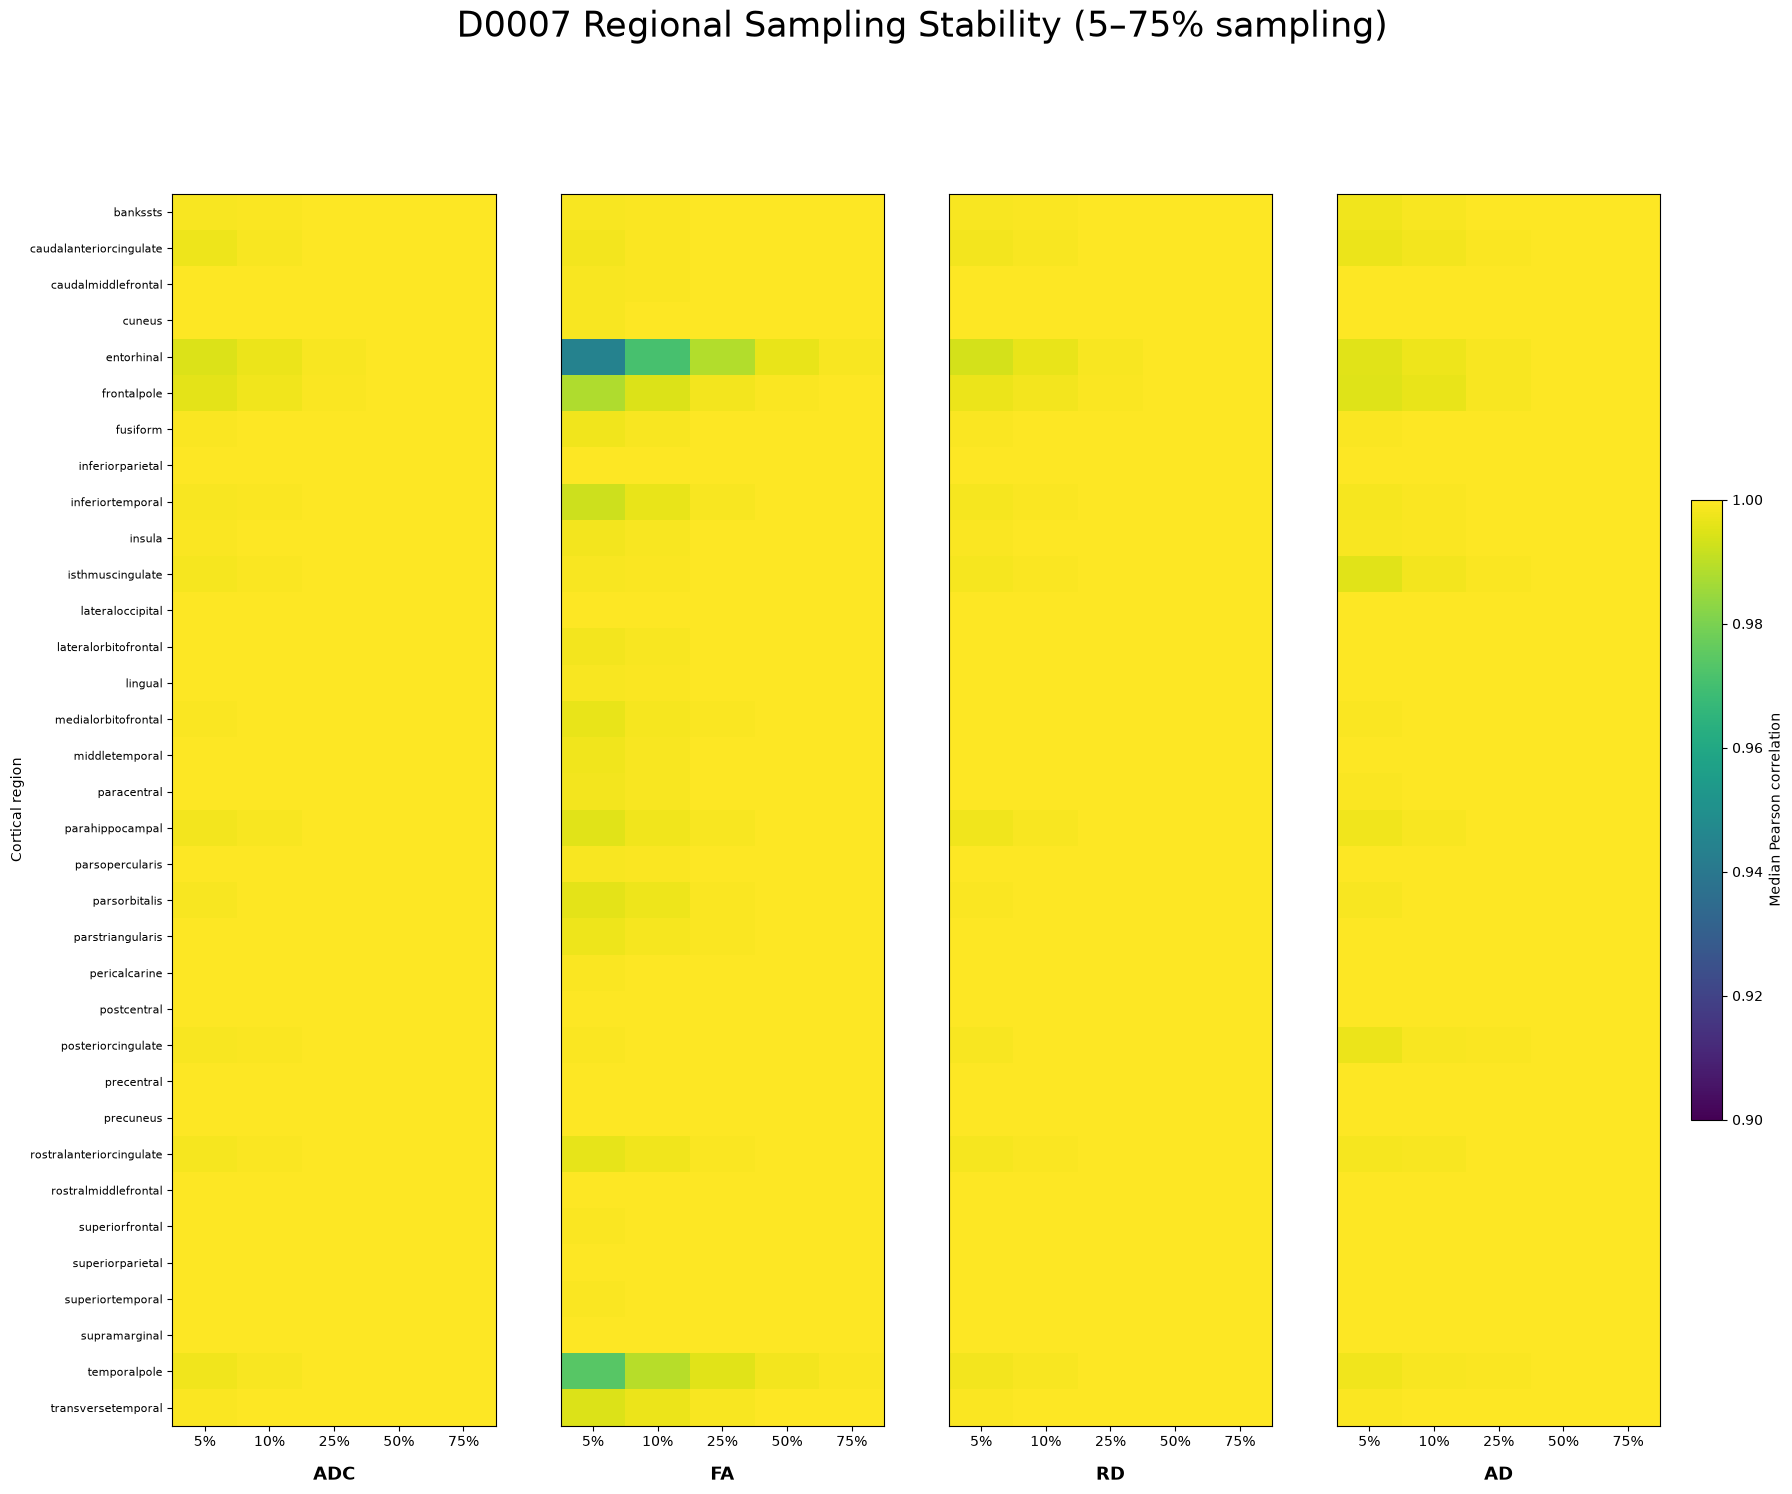

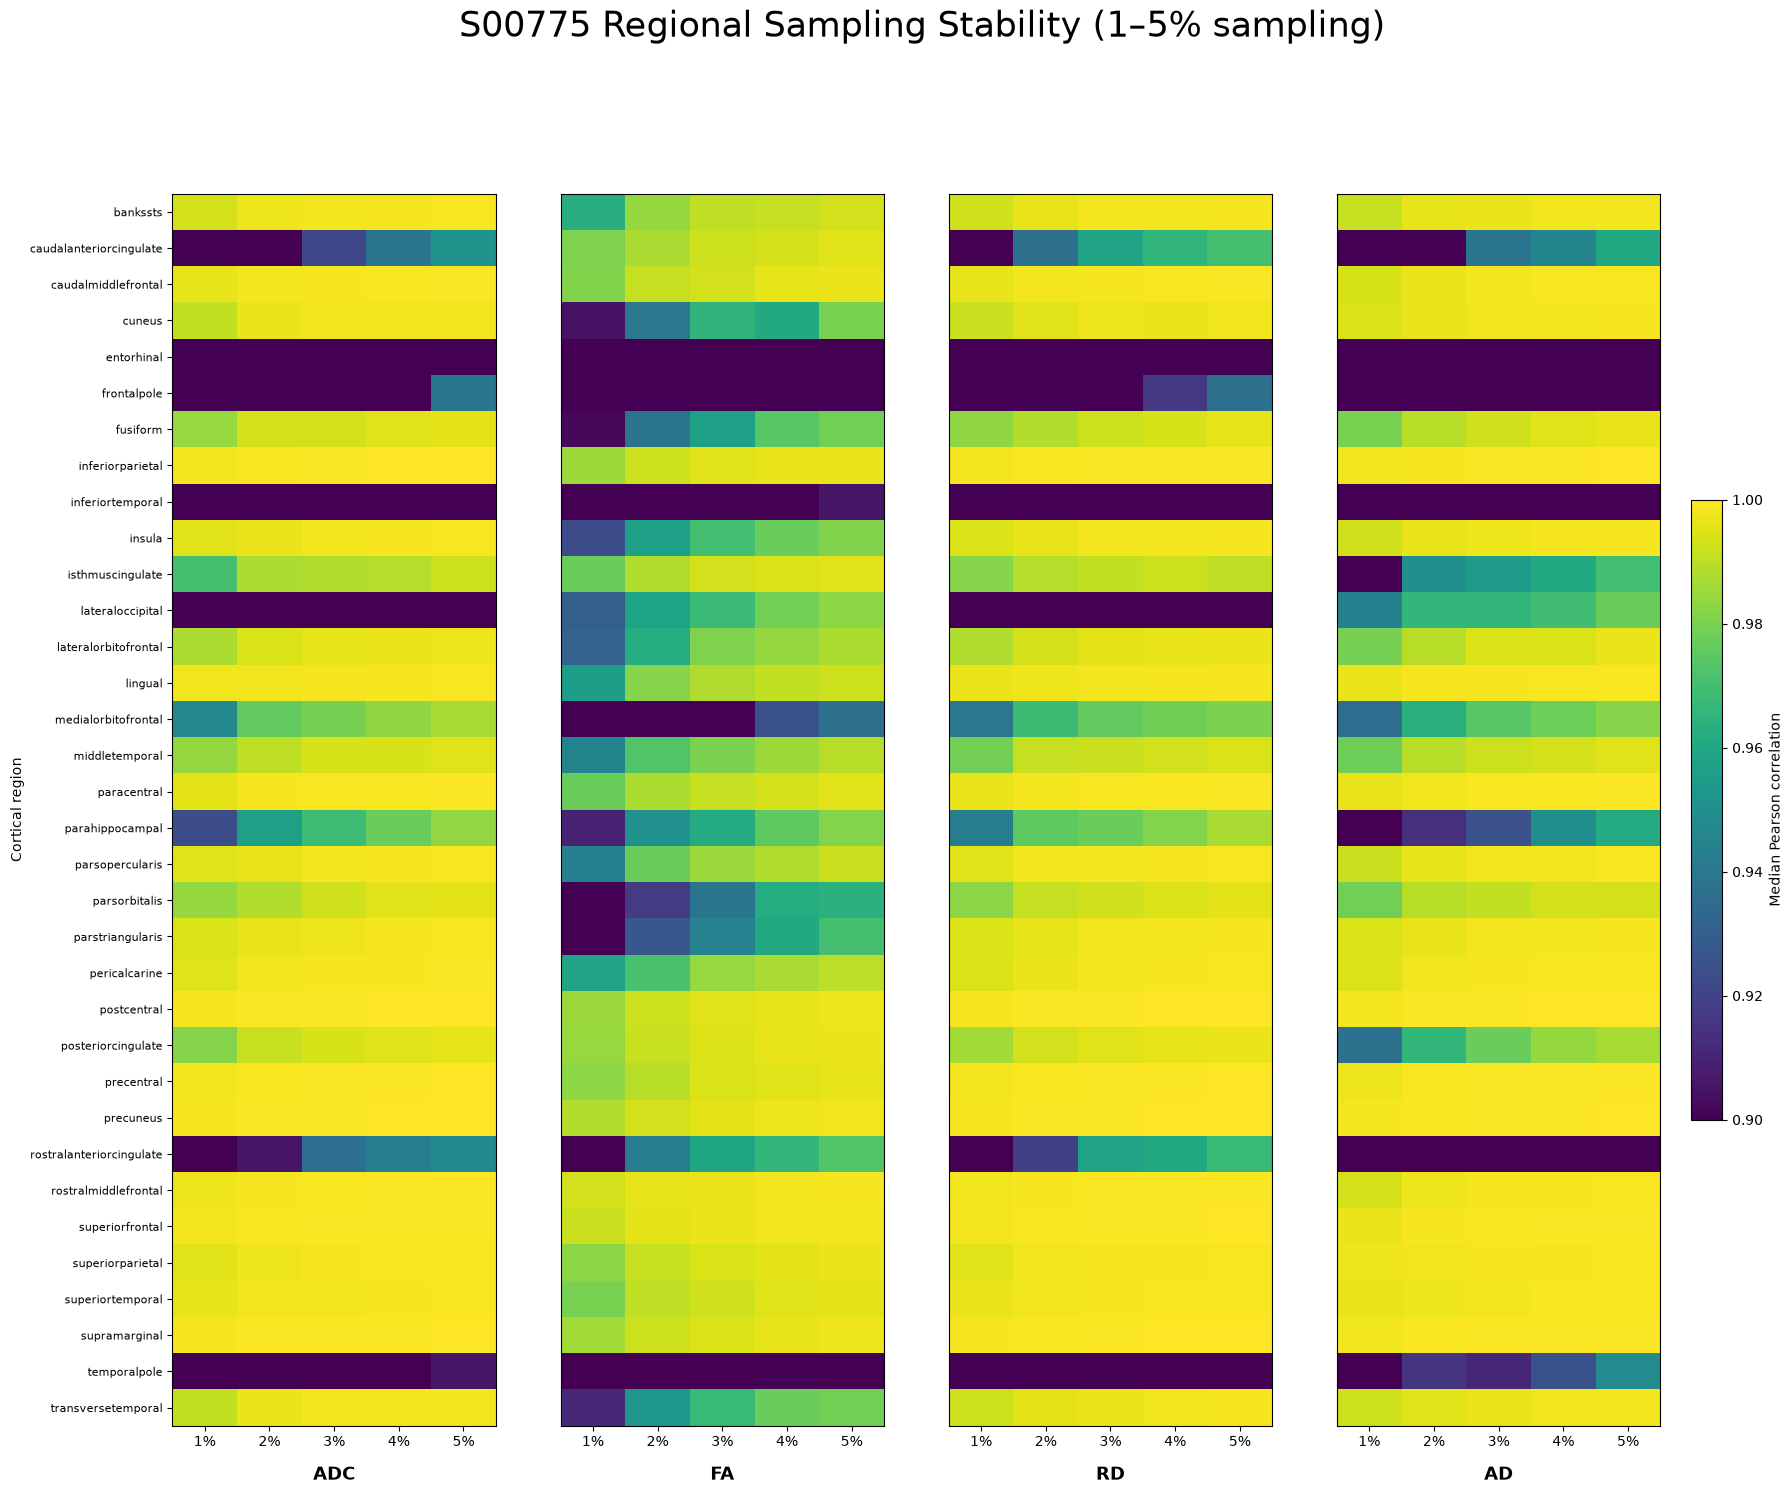

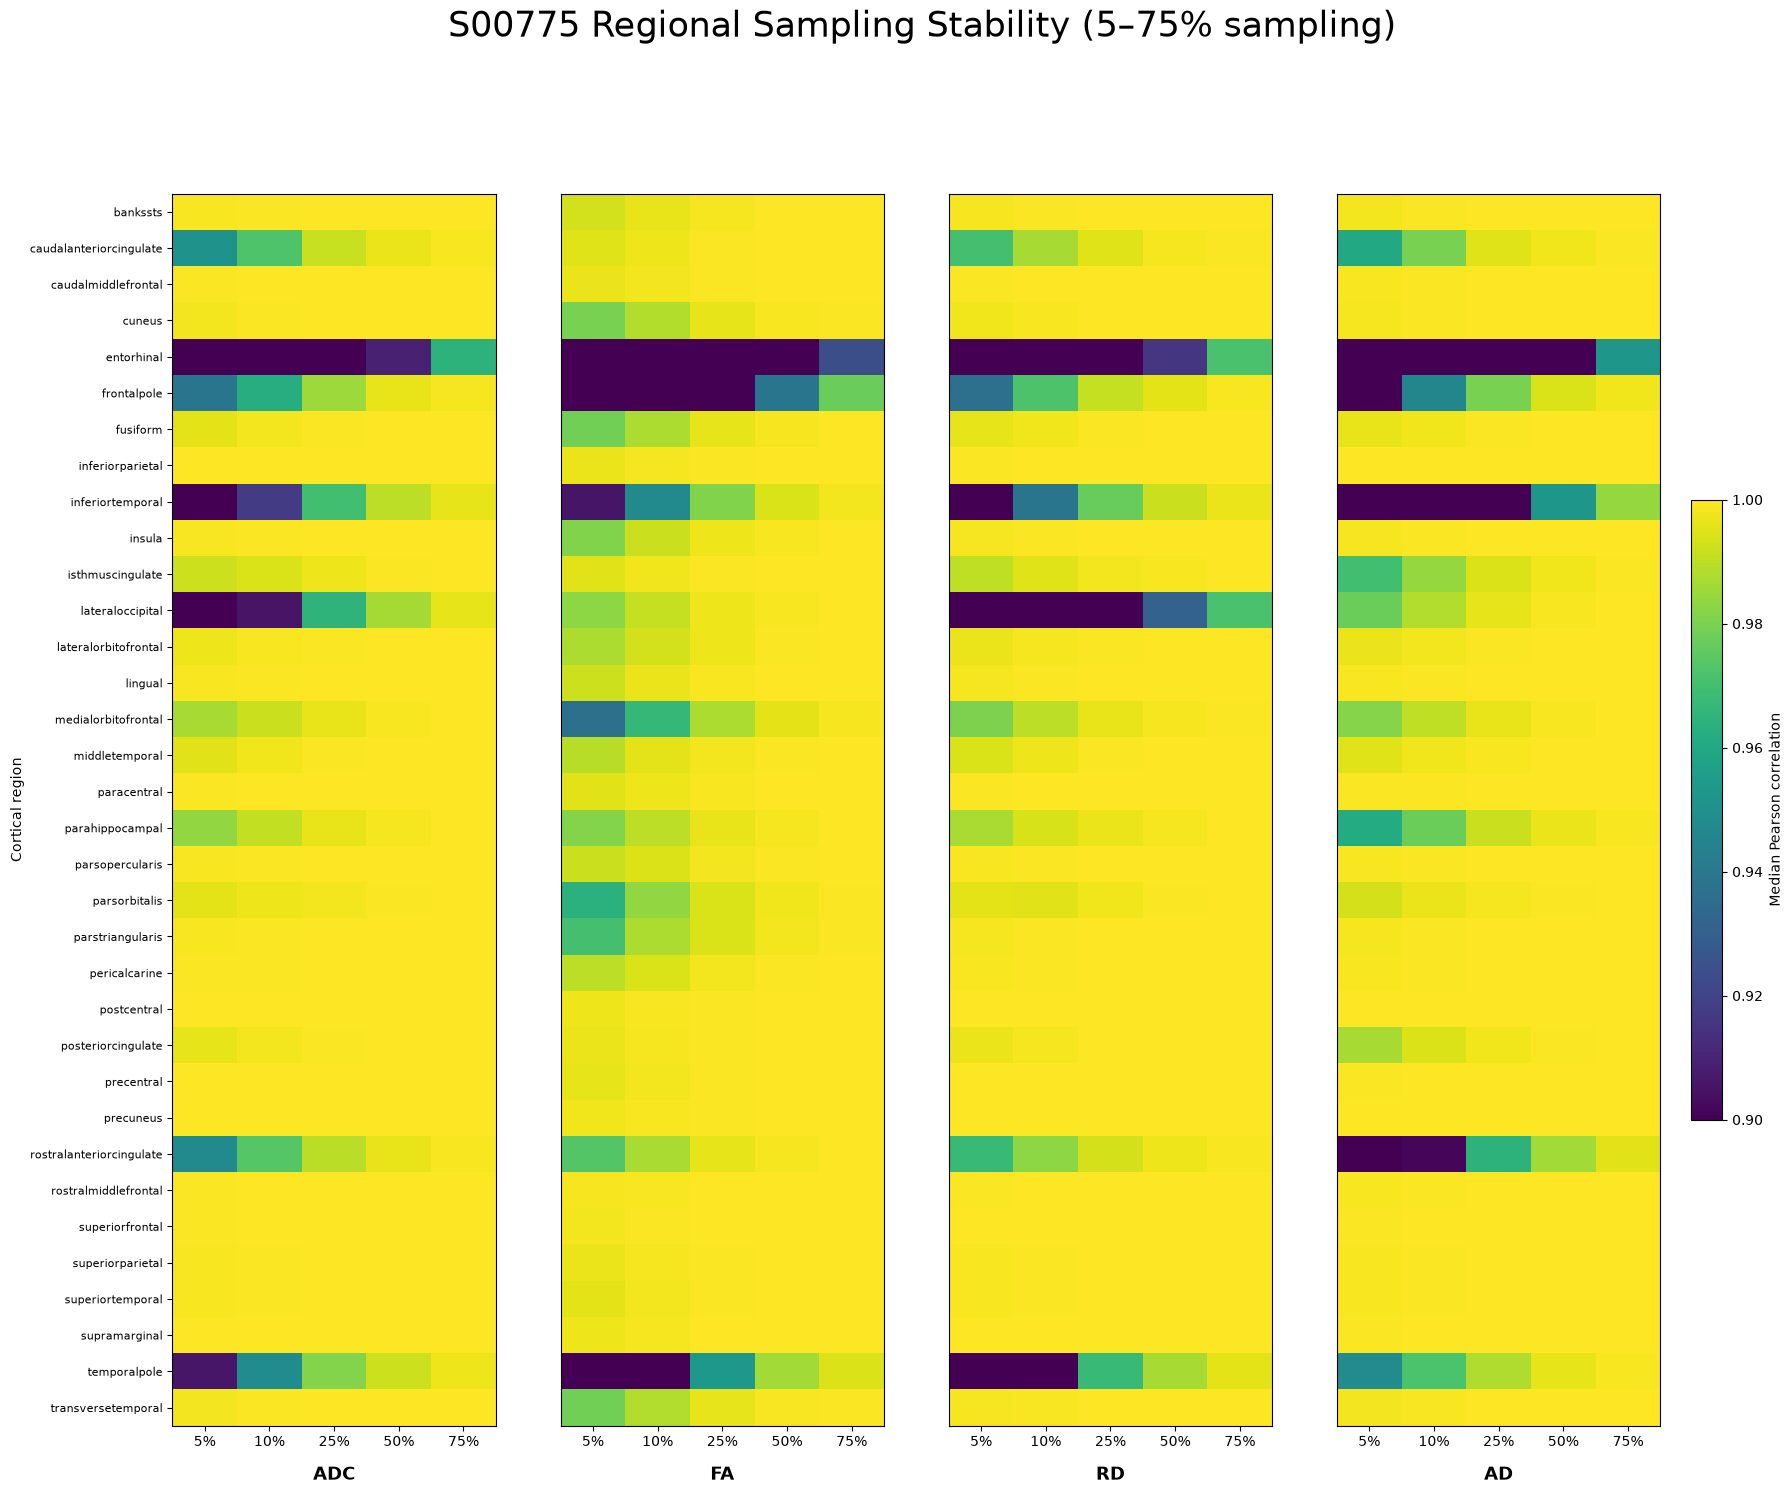

In [246]:
FINE_FRACTIONS = [
    0.01,
    0.02,
    0.03,
    0.04,
    0.05,
]

MAIN_FRACTIONS = [
    0.05,
    0.10,
    0.25,
    0.50,
    0.75,
]
plot_subject_contrast_heatmaps(
    "D0007",
    FINE_FRACTIONS,
    "1–5% sampling",
)

plot_subject_contrast_heatmaps(
    "D0007",
    MAIN_FRACTIONS,
    "5–75% sampling",
)
plot_subject_contrast_heatmaps(
    "S00775",
    FINE_FRACTIONS,
    "1–5% sampling",
)

plot_subject_contrast_heatmaps(
    "S00775",
    MAIN_FRACTIONS,
    "5–75% sampling",
)

In [ ]:
regional_ci_rows = []

for subject, df in qa_data.items():

    temp = df.copy()

    temp["ci_width"] = (
        temp["ci_upper"]
        - temp["ci_lower"]
    )

    region_ci = (
        temp.groupby(
            ["region", "hemi"],
            as_index=False,
        )
        .agg(
            mean_ci_width=(
                "ci_width",
                "mean",
            ),
            mean_adc=(
                "mean",
                "mean",
            ),
        )
    )

    region_ci["subject"] = subject

    regional_ci_rows.append(
        region_ci
    )

regional_ci = pd.concat(
    regional_ci_rows,
    ignore_index=True,
)

In [ ]:
regional_ci_rows = []

for subject, df in qa_data.items():

    temp = df.copy()

    temp["ci_width"] = (
        temp["ci_upper"]
        - temp["ci_lower"]
    )

    region_ci = (
        temp.groupby(
            ["region", "hemi"],
            as_index=False,
        )
        .agg(
            mean_ci_width=(
                "ci_width",
                "mean",
            ),
            mean_adc=(
                "mean",
                "mean",
            ),
        )
    )

    region_ci["subject"] = subject

    regional_ci_rows.append(
        region_ci
    )

regional_ci = pd.concat(
    regional_ci_rows,
    ignore_index=True,
)

In [233]:
def plot_subject_contrast_heatmaps_log10(
    subject,
    fractions,
    scale_label,
):
    contrasts = [
        "adc",
        "fa",
        "rd",
        "ad",
    ]

    subject_df = region_summary_df[
        (
            region_summary_df["subject"]
            == subject
        )
        &
        (
            region_summary_df[
                "sampling_fraction"
            ].isin(fractions)
        )
    ].copy()

    region_order = sorted(
        subject_df["region"].unique()
    )

    fig, axes = plt.subplots(
        1,
        len(contrasts),
        figsize=(20, 16),
        sharey=True,
    )

    image = None

    for ax, contrast in zip(
        axes,
        contrasts,
    ):
        contrast_df = subject_df[
            subject_df["contrast"]
            == contrast
        ].copy()

        heatmap_df = (
            contrast_df
            .pivot_table(
                index="region",
                columns="sampling_fraction",
                values="median_correlation",
                aggfunc="mean",
            )
            .reindex(
                index=region_order,
                columns=fractions,
            )
        )

        # Direct log10 transform of Pearson r
        log_values = np.log10(
            np.clip(
                heatmap_df.values,
                0.1,
                1.0,
            )
        )

        image = ax.imshow(
            log_values,
            aspect="auto",
            vmin=-1,
            vmax=0,
        )

        ax.set_xticks(
            range(len(fractions))
        )

        ax.set_xticklabels(
            [
                f"{int(x * 100)}%"
                for x in fractions
            ],
            fontsize=9,
        )

        ax.set_xlabel(
            contrast.upper(),
            fontsize=13,
            fontweight="bold",
            labelpad=12,
        )

        if ax is axes[0]:

            ax.set_yticks(
                range(len(region_order))
            )

            ax.set_yticklabels(
                region_order,
                fontsize=8,
            )

            ax.set_ylabel(
                "Cortical region"
            )

        else:

            ax.tick_params(
                axis="y",
                left=False,
                labelleft=False,
            )

    fig.suptitle(
        (
            f"{subject} Regional Sampling Stability "
            f"({scale_label})"
        ),
        fontsize=25,
        y=0.995,
    )

    cbar = fig.colorbar(
        image,
        ax=axes,
        fraction=0.02,
        pad=0.02,
    )

    cbar.set_ticks(
        [
            -1.0,
            -0.8,
            -0.6,
            -0.4,
            -0.2,
            0.0,
        ]
    )

    cbar.set_label(
        r"$\log_{10}(\mathrm{Median\ Pearson\ r})$"
    )

    plt.show()

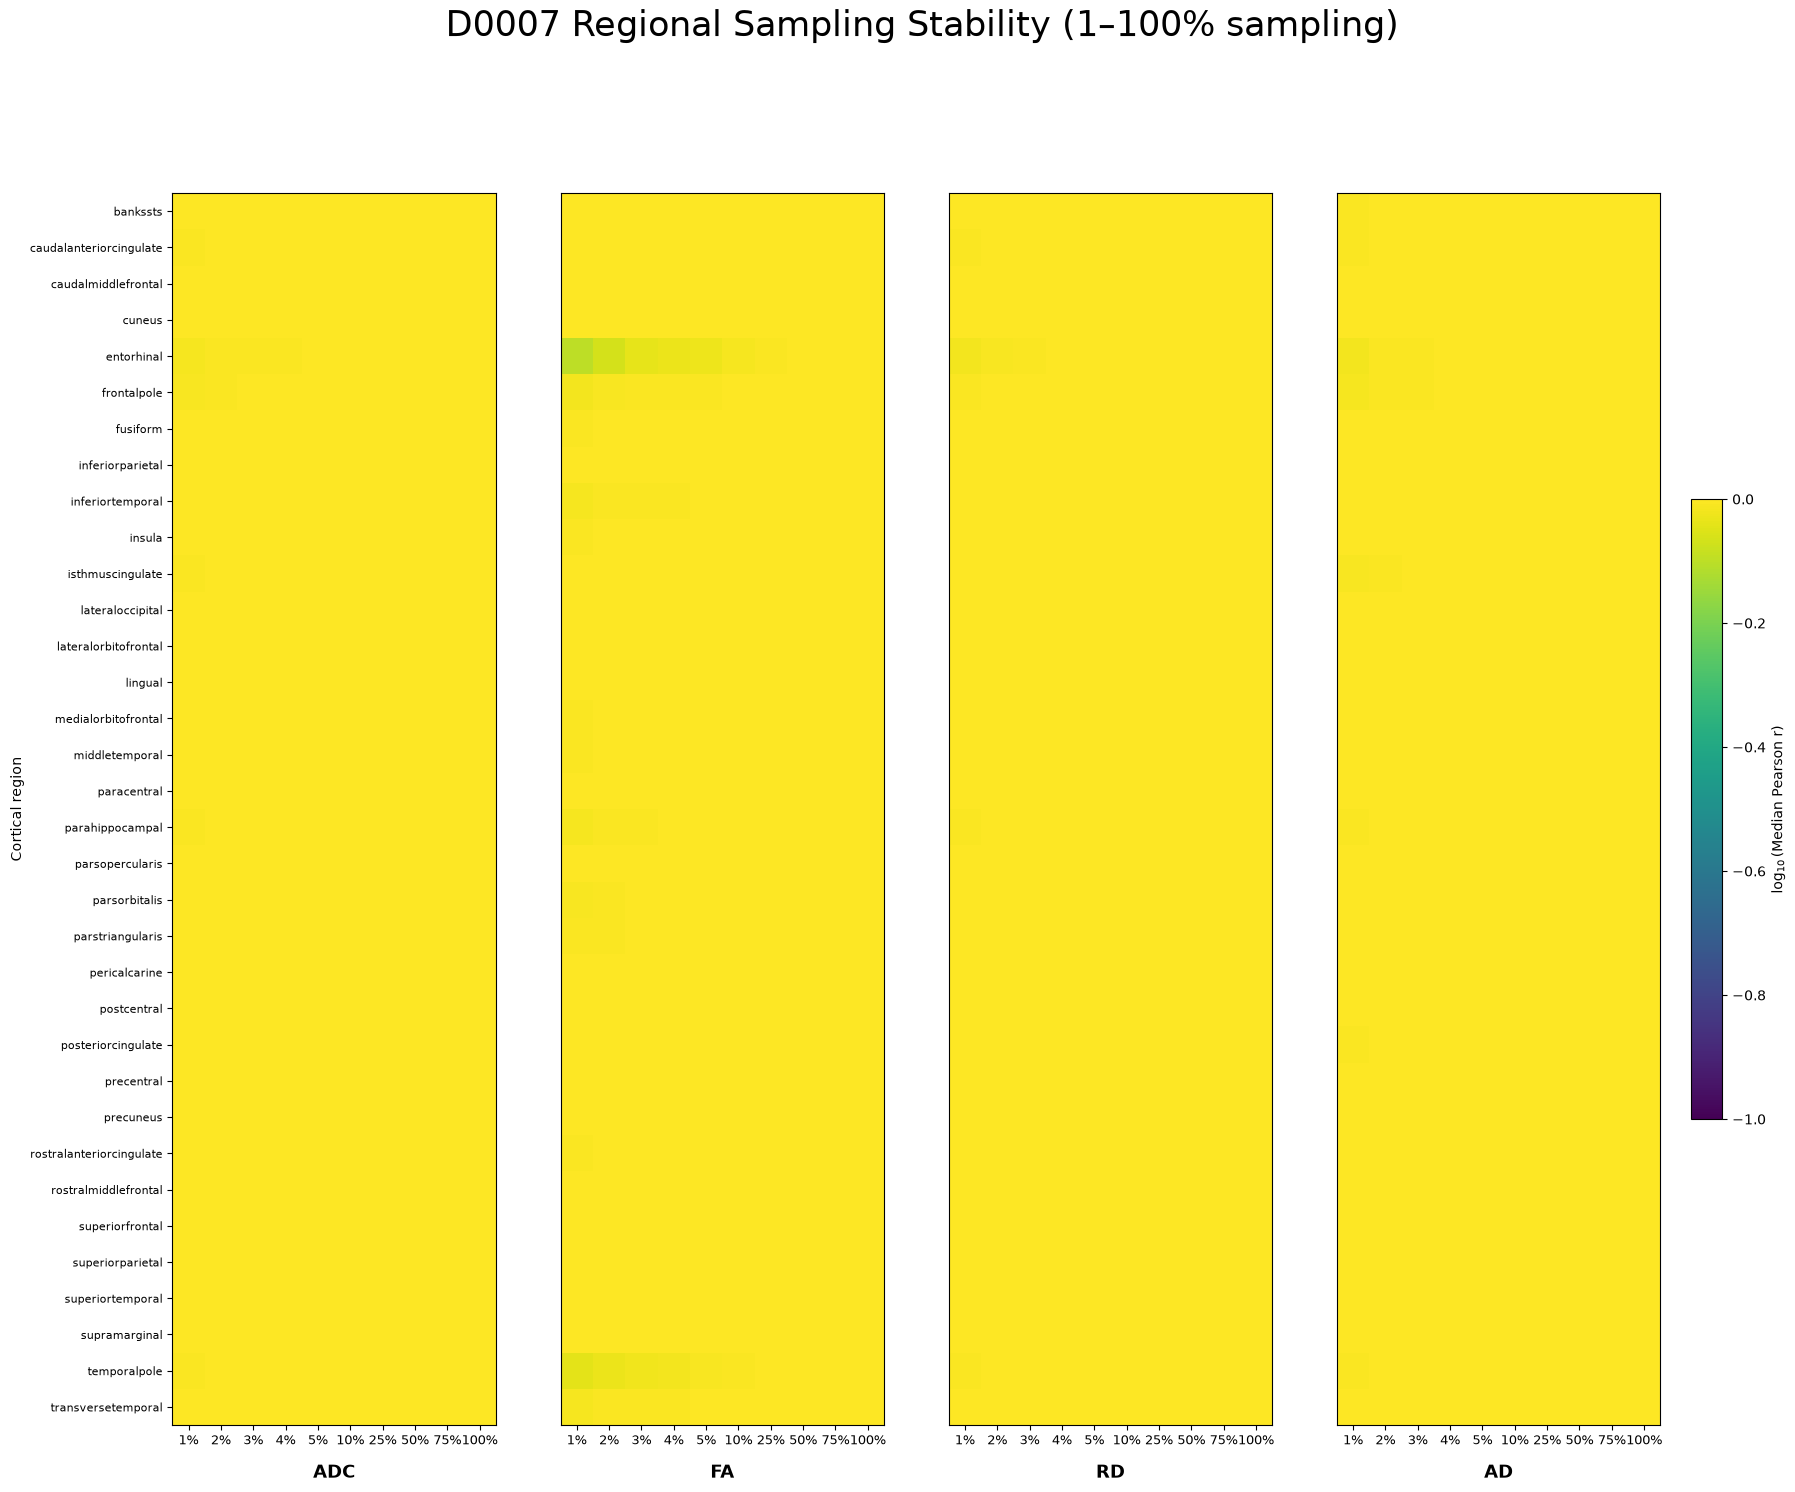

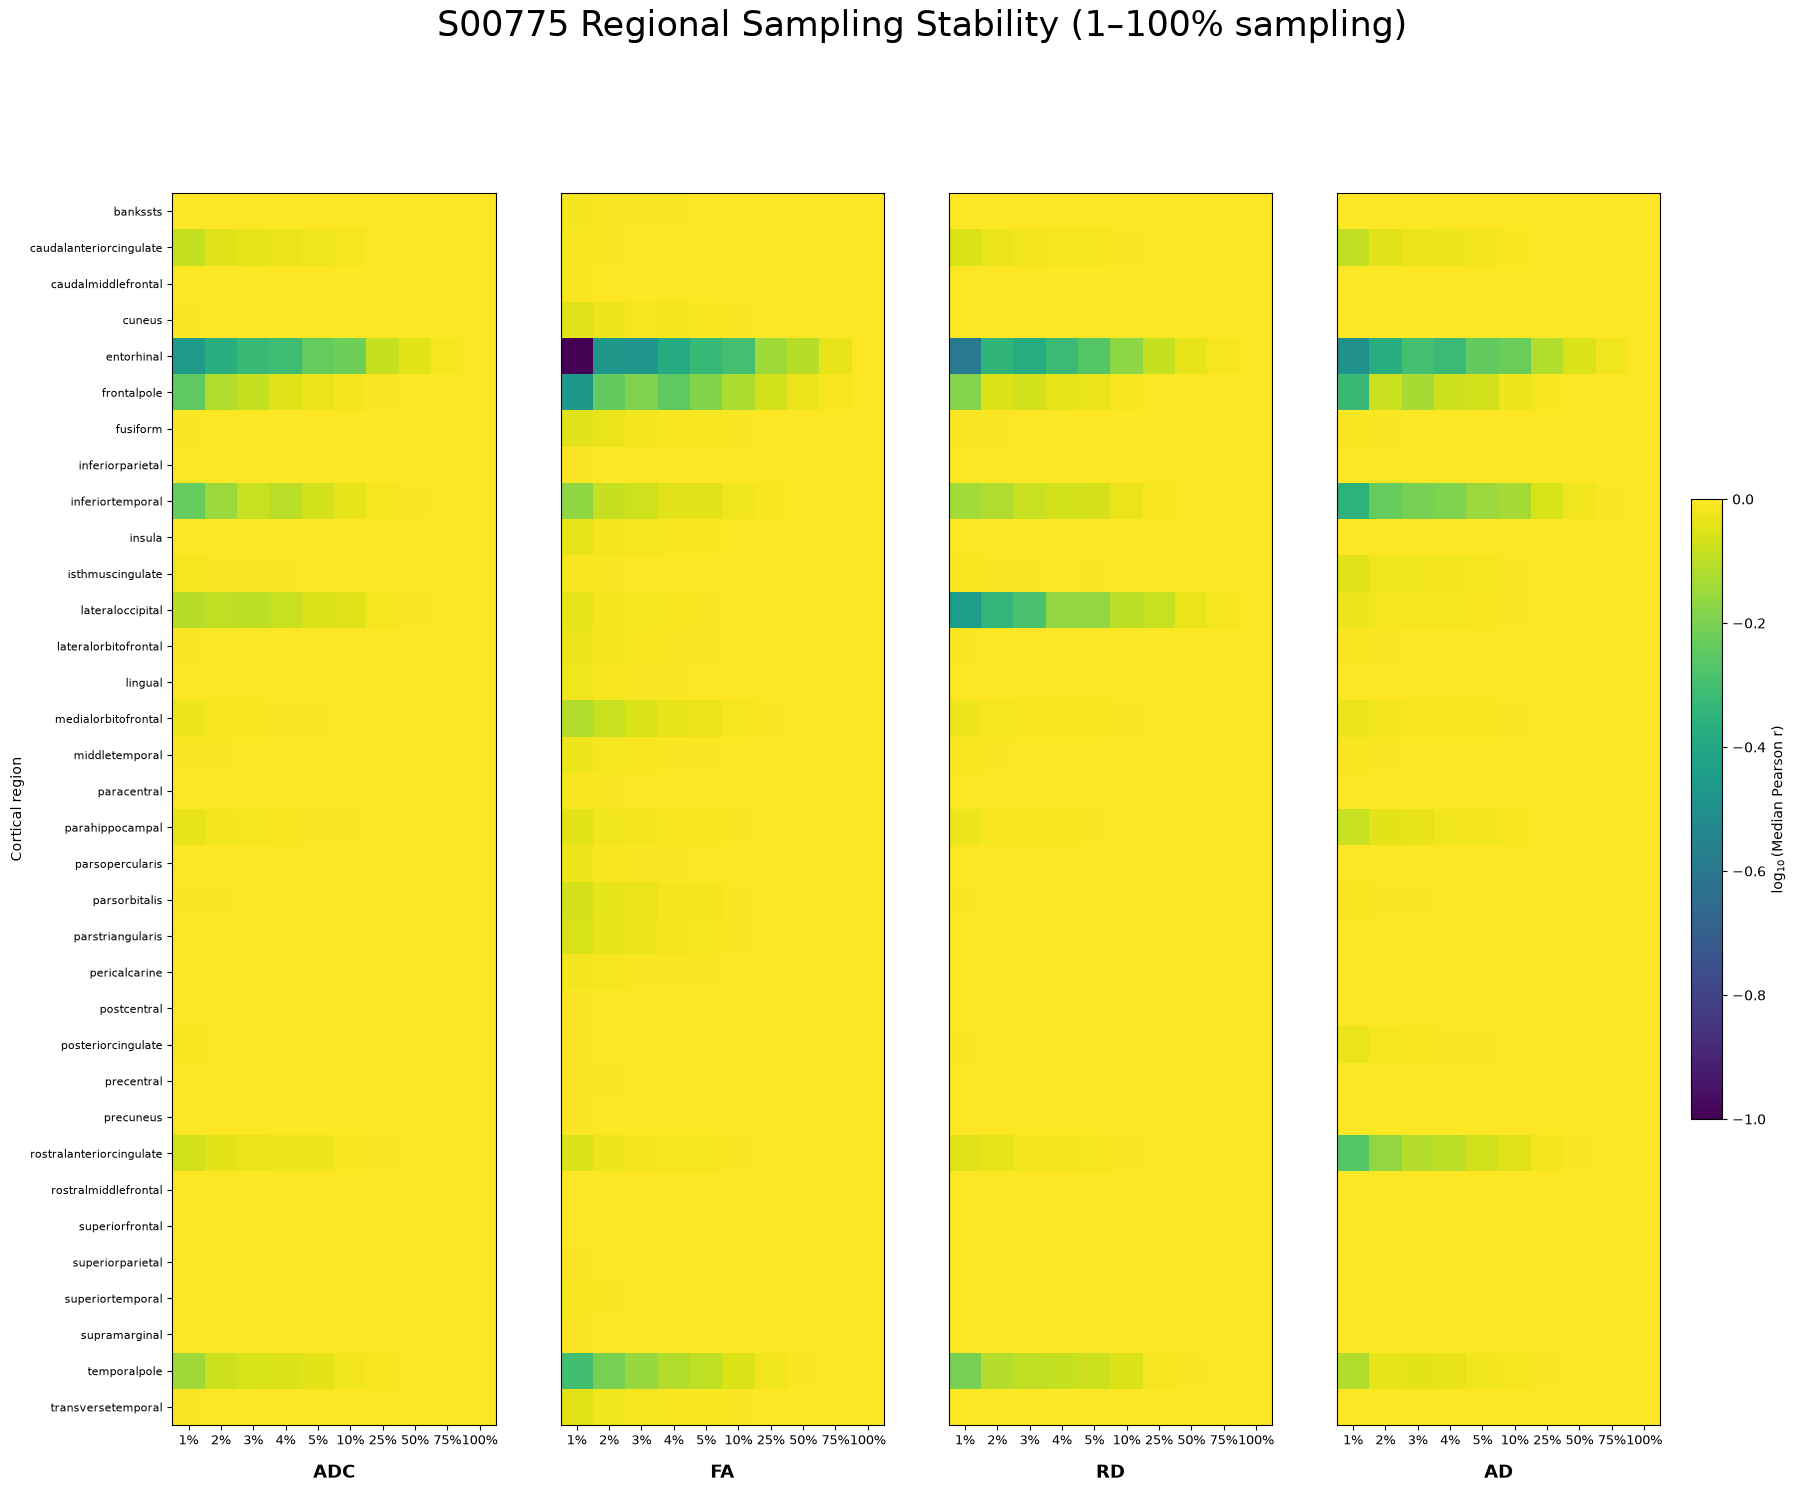

In [ ]:
plot_subject_contrast_heatmaps_log10(
    "D0007",
    SAMPLING_FRACTIONS,
    "1–100% sampling",
)
plot_subject_contrast_heatmaps_log10(
    "S00775",
    SAMPLING_FRACTIONS,
    "1–100% sampling",
)

In [210]:
correlation_range_df = (
    region_summary_df[
        region_summary_df["subject"].isin(
            ["S00775", "D0007"]
        )
    ]
    .groupby(
        [
            "subject",
            "contrast",
        ]
    )["median_correlation"]
    .agg(
        min_r="min",
        p05_r=lambda x: x.quantile(0.05),
        median_r="median",
        max_r="max",
    )
    .reset_index()
)

display(correlation_range_df)

,subject,contrast,min_r,p05_r,median_r,max_r
0,D0007,ad,0.943949,0.992759,0.999771,1.0
1,D0007,adc,0.969905,0.995316,0.999817,1.0
2,D0007,fa,0.748285,0.982515,0.999442,1.0
3,D0007,rd,0.957964,0.995230,0.999831,1.0
4,S00775,ad,0.167444,0.788560,0.998788,1.0
5,S00775,adc,0.182135,0.826346,0.998952,1.0
6,S00775,fa,0.008176,0.777923,0.995392,1.0
7,S00775,rd,0.049652,0.811512,0.998959,1.0


## Regional Sampling Error

Median MAE is shown for each cortical region across sampling fractions.

In [242]:
def plot_subject_relative_mae_heatmaps(
    subject,
    fractions,
    scale_label,
):
    contrasts = [
        "adc",
        "fa",
        "rd",
        "ad",
    ]

    subject_df = region_summary_df[
        (
            region_summary_df["subject"]
            == subject
        )
        &
        (
            region_summary_df[
                "sampling_fraction"
            ].isin(fractions)
        )
    ].copy()

    region_order = sorted(
        subject_df["region"].unique()
    )

    fig, axes = plt.subplots(
        1,
        len(contrasts),
        figsize=(20, 16),
        sharey=True,
    )

    image = None

    # Shared scale across contrasts
    vmax = (
        subject_df[
            "median_relative_mae"
        ]
        .quantile(0.95)
    )

    for ax, contrast in zip(
        axes,
        contrasts,
    ):
        contrast_df = subject_df[
            subject_df["contrast"]
            == contrast
        ].copy()

        heatmap_df = (
            contrast_df
            .pivot_table(
                index="region",
                columns="sampling_fraction",
                values="median_relative_mae",
                aggfunc="mean",
            )
            .reindex(
                index=region_order,
                columns=fractions,
            )
        )

        image = ax.imshow(
            heatmap_df.values,
            aspect="auto",
            vmin=0,
            vmax=vmax,
        )

        ax.set_xticks(
            range(len(fractions))
        )

        ax.set_xticklabels(
            [
                f"{int(x * 100)}%"
                for x in fractions
            ],
            fontsize=9,
        )

        ax.set_xlabel(
            contrast.upper(),
            fontsize=13,
            fontweight="bold",
            labelpad=12,
        )

        if ax is axes[0]:

            ax.set_yticks(
                range(len(region_order))
            )

            ax.set_yticklabels(
                region_order,
                fontsize=8,
            )

            ax.set_ylabel(
                "Cortical region"
            )

        else:

            ax.tick_params(
                axis="y",
                left=False,
                labelleft=False,
            )

    fig.suptitle(
        (
            f"{subject} Regional Sampling Error "
            f"({scale_label})"
        ),
        fontsize=25,
        y=0.995,
    )

    cbar = fig.colorbar(
        image,
        ax=axes,
        fraction=0.02,
        pad=0.02,
    )

    cbar.set_label(
        "Median Relative MAE (%)"
    )

    plt.show()

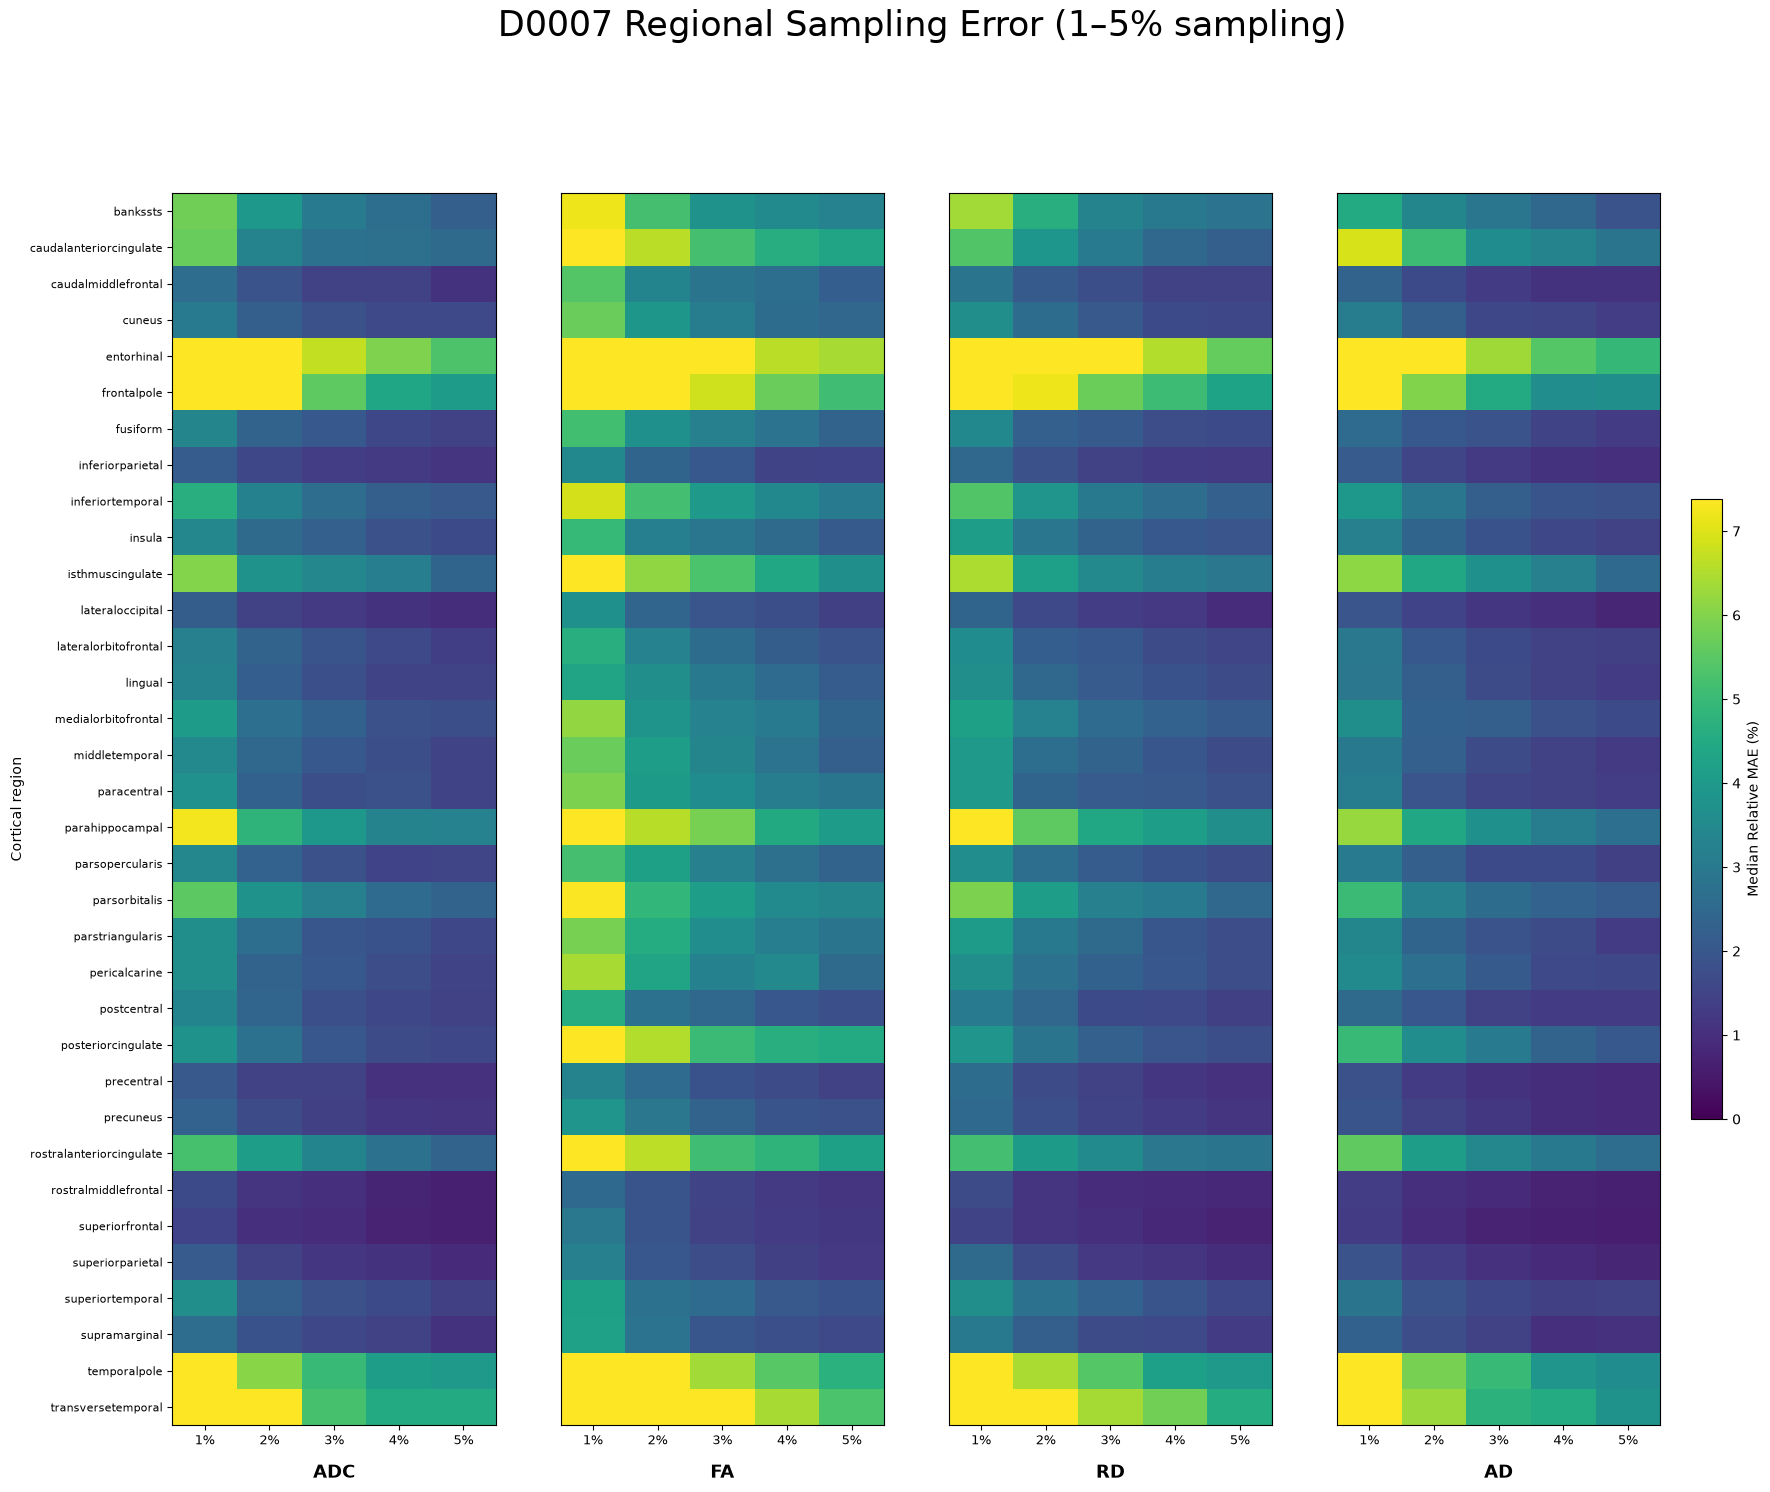

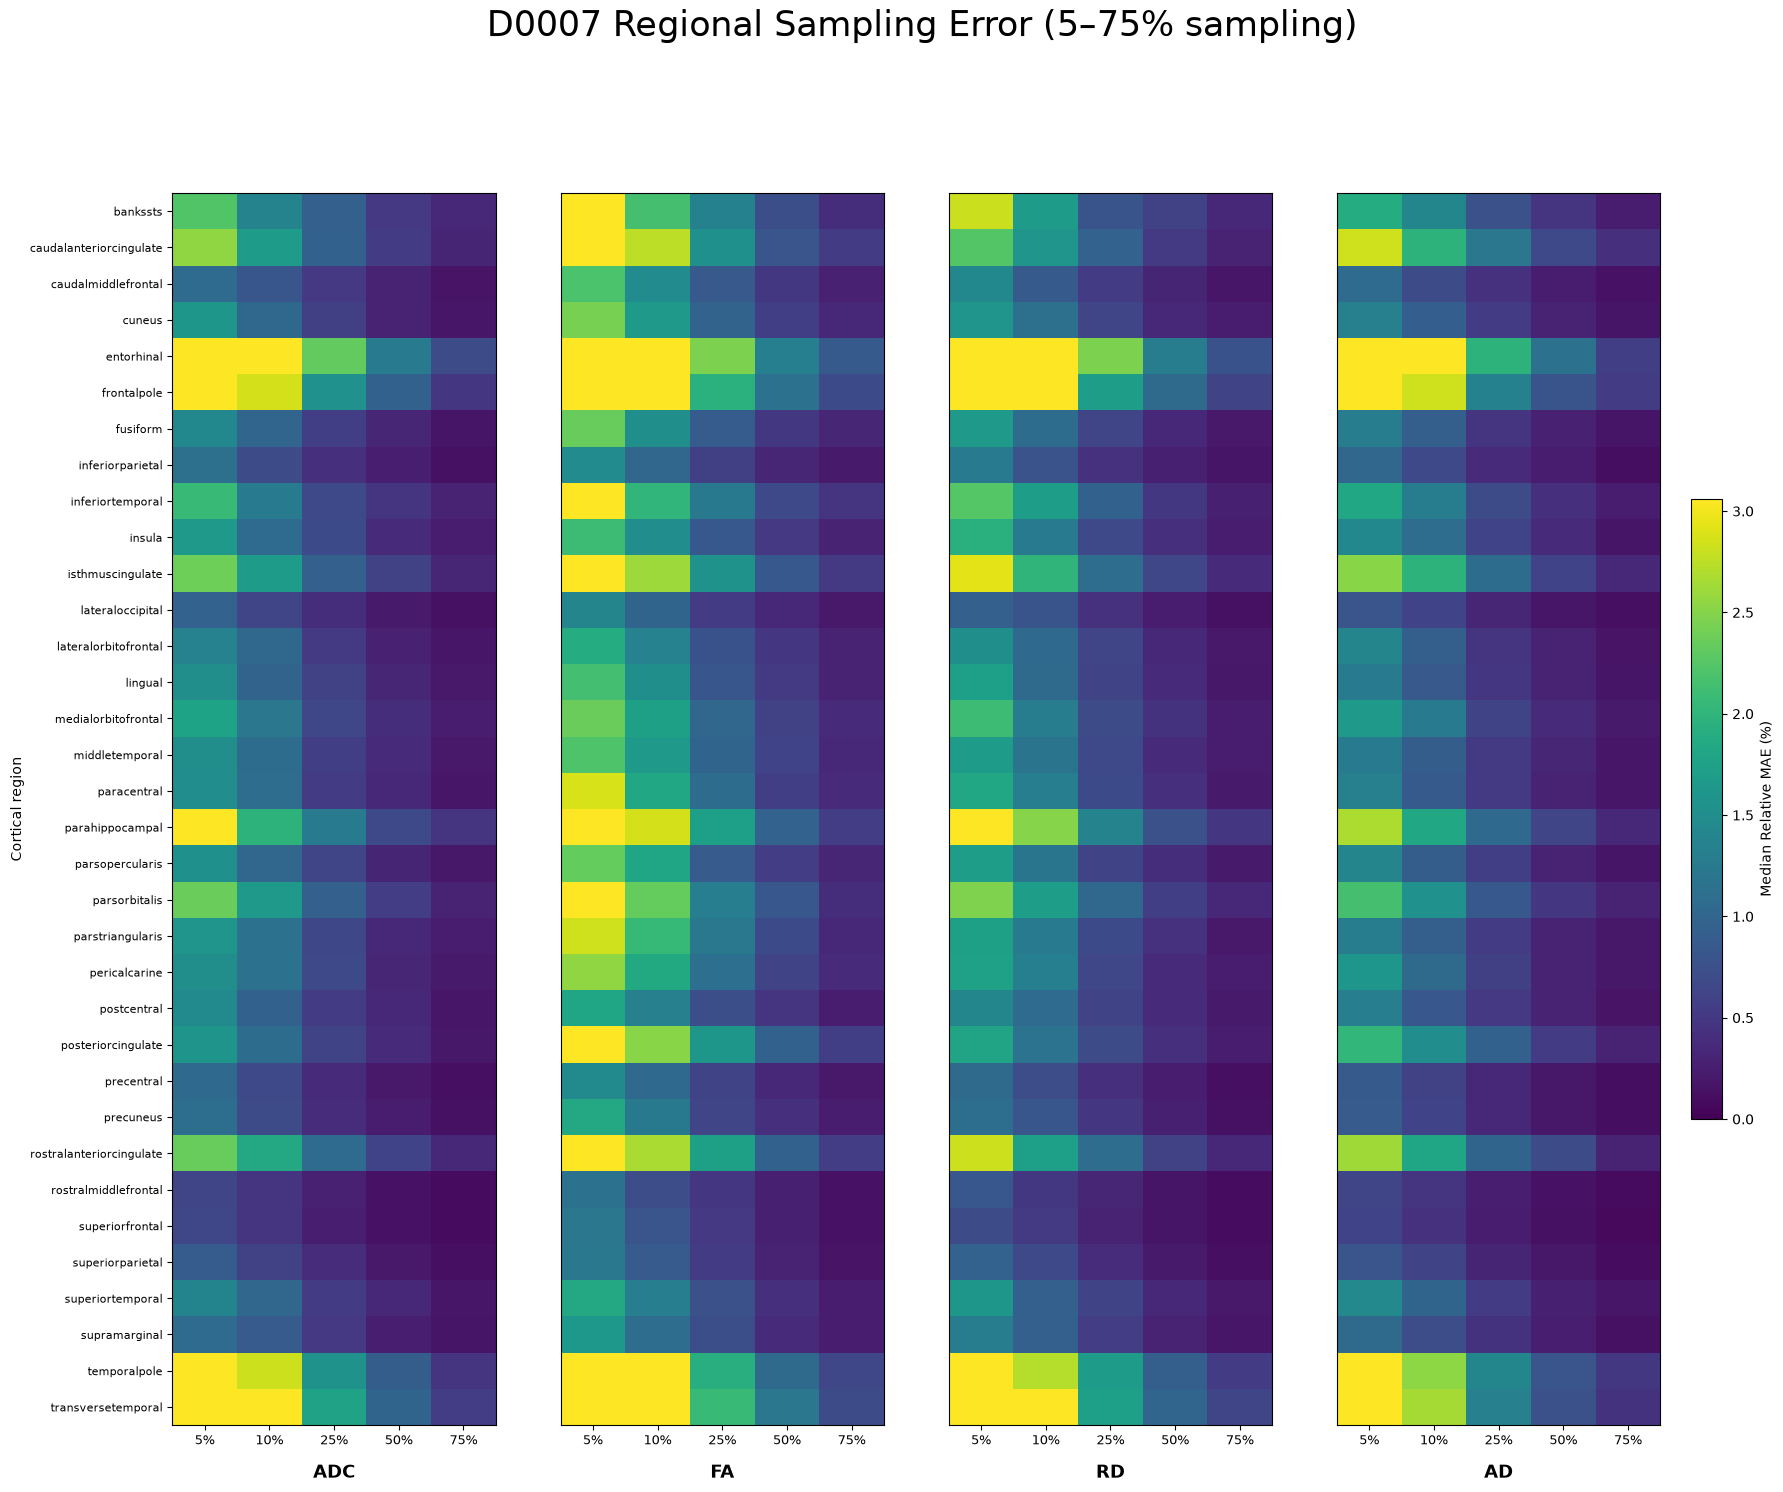

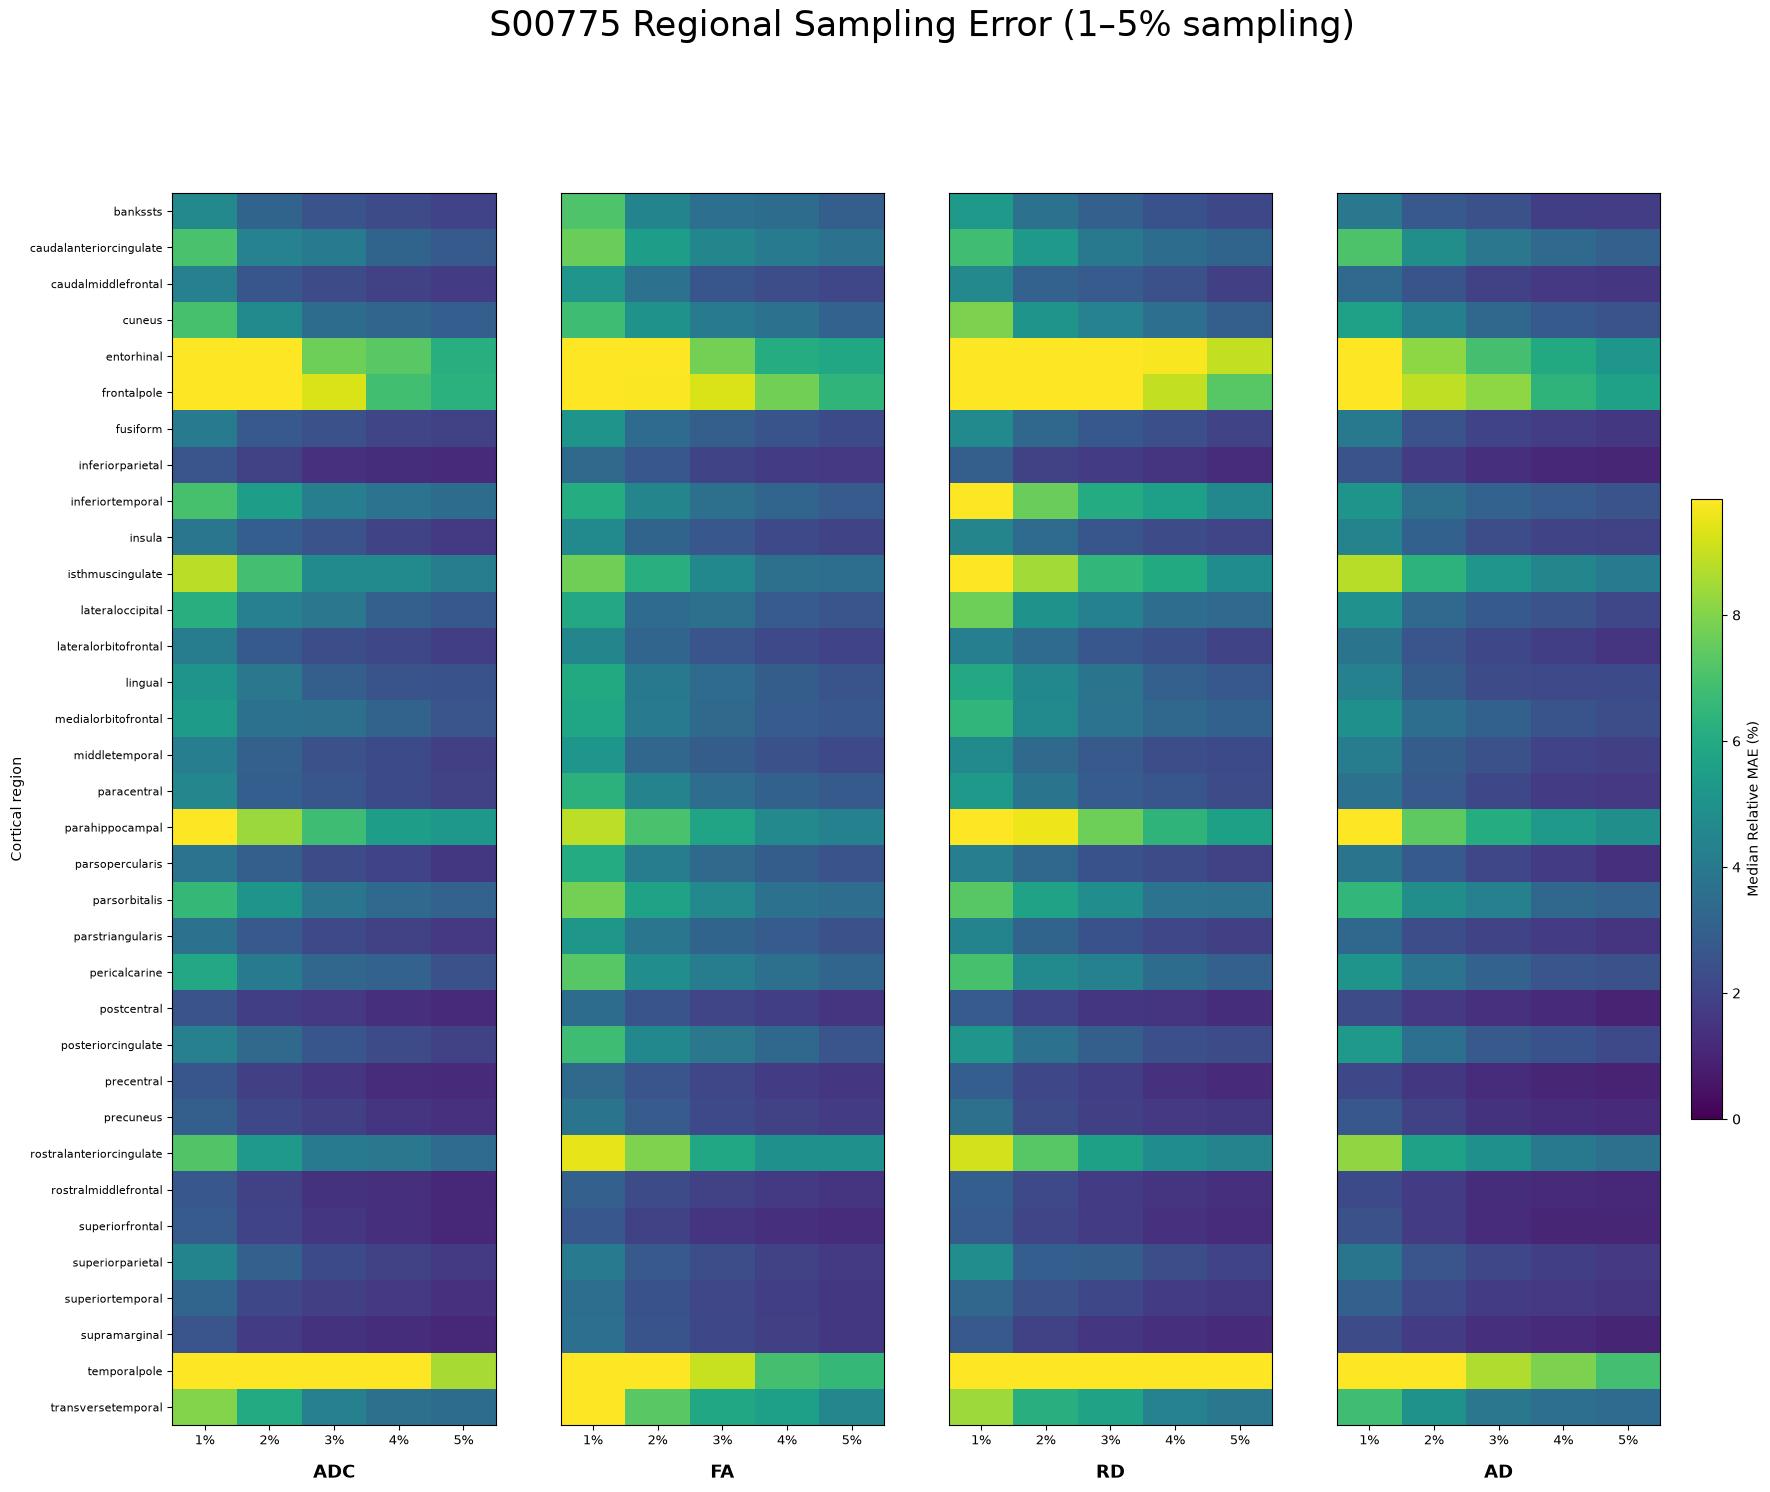

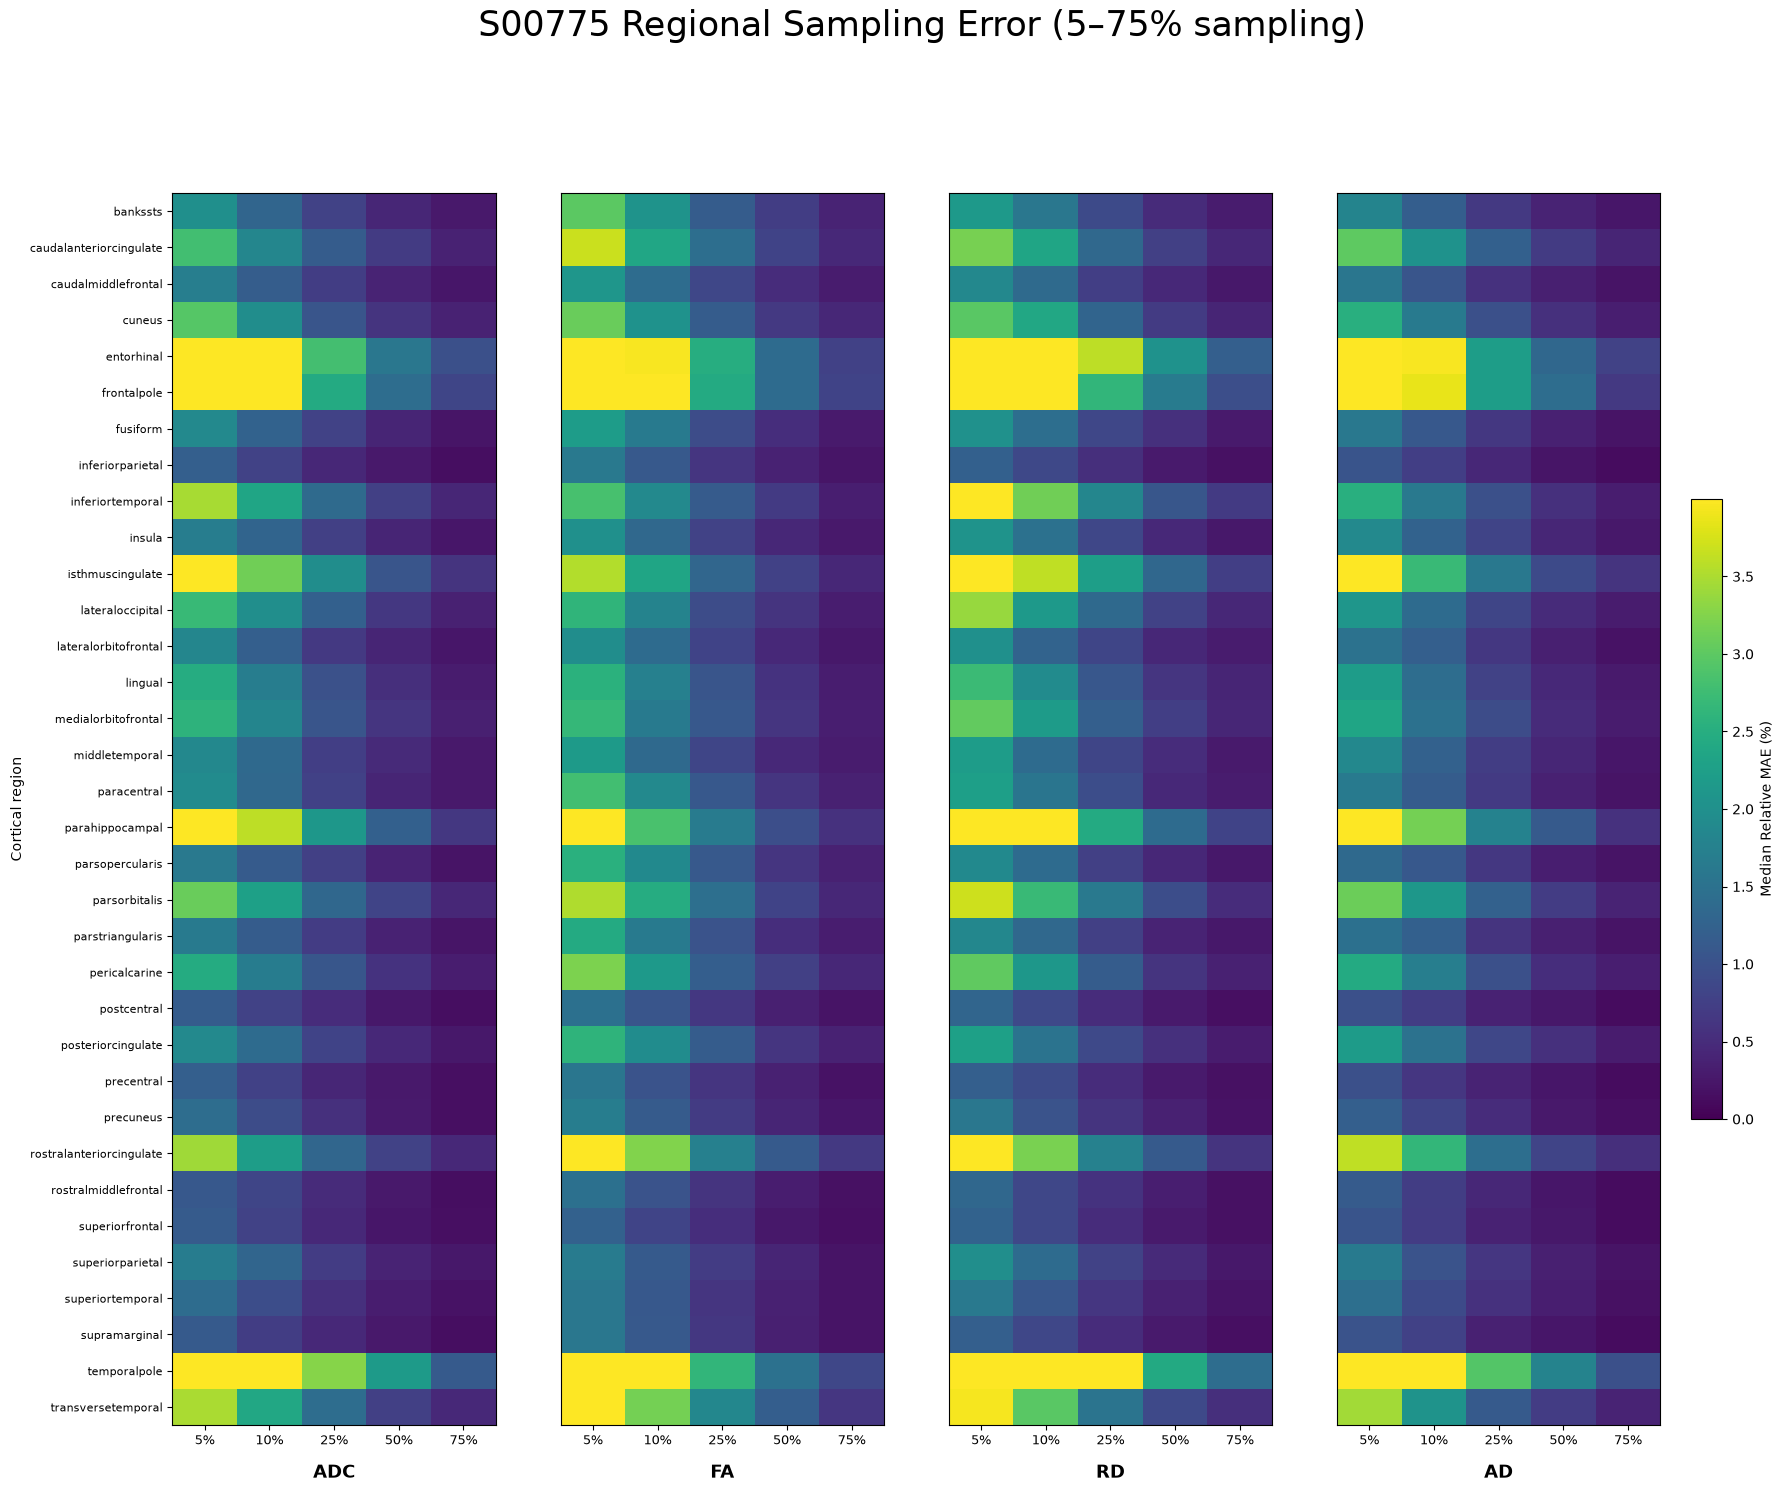

In [248]:
FINE_FRACTIONS = [
    0.01,
    0.02,
    0.03,
    0.04,
    0.05,
]

MAIN_FRACTIONS = [
    0.05,
    0.10,
    0.25,
    0.50,
    0.75,
]
plot_subject_relative_mae_heatmaps(
    "D0007",
    FINE_FRACTIONS,
    "1–5% sampling",
)

plot_subject_relative_mae_heatmaps(
    "D0007",
    MAIN_FRACTIONS,
    "5–75% sampling",
)

plot_subject_relative_mae_heatmaps(
    "S00775",
    FINE_FRACTIONS,
    "1–5% sampling",
)

plot_subject_relative_mae_heatmaps(
    "S00775",
    MAIN_FRACTIONS,
    "5–75% sampling",
)

In [ ]:
regional_ci_rows = []

for subject, df in qa_data.items():

    temp = df.copy()

    temp["ci_width"] = (
        temp["ci_upper"]
        - temp["ci_lower"]
    )

    region_ci = (
        temp.groupby(
            ["region", "hemi"],
            as_index=False,
        )
        .agg(
            mean_ci_width=(
                "ci_width",
                "mean",
            ),
            mean_adc=(
                "mean",
                "mean",
            ),
        )
    )

    region_ci["subject"] = subject

    regional_ci_rows.append(
        region_ci
    )

regional_ci = pd.concat(
    regional_ci_rows,
    ignore_index=True,
)

## Regions with Poor Column Sampling Stability

To identify cortical regions that are consistently difficult to sample, regional sampling performance was evaluated at 5% and 10% sampling fractions.

Two complementary criteria were used:

- **Poor correlation stability:** P10 Pearson correlation < 0.95
- **High relative error:** Relative MAE within the highest 20% of regions for the same subject, contrast, and sampling fraction

A region was considered strongly sampling-sensitive when it showed both poor correlation stability and high relative error.

The analysis also summarizes whether poorly sampled regions are shared across imaging contrasts and across subjects.

In [213]:
POOR_R_THRESHOLD = 0.95
HIGH_ERROR_QUANTILE = 0.80

TARGET_FRACTIONS = [
    0.05,
    0.10,
]

ANALYSIS_SUBJECTS = [
    "S00775",
    "D0007",
]


poor_region_df = (
    region_summary_df[
        (
            region_summary_df[
                "sampling_fraction"
            ].isin(TARGET_FRACTIONS)
        )
        &
        (
            region_summary_df[
                "subject"
            ].isin(ANALYSIS_SUBJECTS)
        )
    ]
    .copy()
)

# Poor correlation stability
poor_region_df[
    "poor_correlation"
] = (
    poor_region_df[
        "p10_correlation"
    ]
    < POOR_R_THRESHOLD
)


# High relative MAE within each
# subject × contrast × sampling fraction
poor_region_df[
    "high_relative_mae"
] = (
    poor_region_df
    .groupby(
        [
            "subject",
            "contrast",
            "sampling_fraction",
        ]
    )[
        "median_relative_mae"
    ]
    .transform(
        lambda x: (
            x
            >= x.quantile(
                HIGH_ERROR_QUANTILE
            )
        )
    )
)


# Strong sampling-sensitive region
poor_region_df[
    "poor_sampling"
] = (
    poor_region_df[
        "poor_correlation"
    ]
    &
    poor_region_df[
        "high_relative_mae"
    ]
)


# Sort for easier inspection
poor_region_table_df = (
    poor_region_df[
        [
            "subject",
            "contrast",
            "sampling_fraction",
            "hemisphere",
            "region",
            "sample_n",
            "median_correlation",
            "p10_correlation",
            "median_relative_mae",
            "poor_correlation",
            "high_relative_mae",
            "poor_sampling",
        ]
    ]
    .sort_values(
        [
            "sampling_fraction",
            "subject",
            "contrast",
            "poor_sampling",
            "p10_correlation",
        ],
        ascending=[
            True,
            True,
            True,
            False,
            True,
        ],
    )
    .reset_index(
        drop=True
    )
)

poor_region_table_df

,subject,contrast,sampling_fraction,hemisphere,region,sample_n,median_correlation,p10_correlation,median_relative_mae,poor_correlation,high_relative_mae,poor_sampling
0,D0007,ad,0.05,lh,frontalpole,16,0.995341,0.961567,4.530660,False,True,False
1,D0007,ad,0.05,rh,entorhinal,33,0.994023,0.970182,5.409341,False,True,False
2,D0007,ad,0.05,lh,isthmuscingulate,65,0.993526,0.972905,2.403584,False,False,False
3,D0007,ad,0.05,lh,caudalanteriorcingulate,41,0.995315,0.976143,2.606482,False,True,False
4,D0007,ad,0.05,rh,frontalpole,19,0.995193,0.977403,2.836536,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
1083,S00775,rd,0.10,rh,postcentral,624,0.999859,0.999519,0.866478,False,False,False
1084,S00775,rd,0.10,lh,supramarginal,532,0.999815,0.999554,0.877063,False,False,False
1085,S00775,rd,0.10,rh,precentral,723,0.999865,0.999559,0.872343,False,False,False
1086,S00775,rd,0.10,lh,postcentral,600,0.999876,0.999561,0.886558,False,False,False


In [214]:
poor_only_df = (
    poor_region_table_df[
        poor_region_table_df[
            "poor_sampling"
        ]
    ]
    .copy()
)

poor_only_df

,subject,contrast,sampling_fraction,hemisphere,region,sample_n,median_correlation,p10_correlation,median_relative_mae,poor_correlation,high_relative_mae,poor_sampling
136,D0007,fa,0.05,lh,entorhinal,33,0.920247,0.410621,6.007937,True,True,True
137,D0007,fa,0.05,lh,temporalpole,31,0.957620,0.743724,4.287319,True,True,True
138,D0007,fa,0.05,rh,entorhinal,33,0.968270,0.872248,6.832382,True,True,True
139,D0007,fa,0.05,lh,frontalpole,16,0.987717,0.930225,5.195048,True,True,True
140,D0007,fa,0.05,rh,frontalpole,19,0.988571,0.949456,5.041954,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...
1023,S00775,rd,0.10,lh,frontalpole,34,0.952820,0.148879,5.092078,True,True,True
1024,S00775,rd,0.10,lh,temporalpole,50,0.923964,0.654776,7.907145,True,True,True
1025,S00775,rd,0.10,rh,inferiortemporal,363,0.931442,0.809956,3.758887,True,True,True
1026,S00775,rd,0.10,rh,rostralanteriorcingulate,83,0.978597,0.905196,3.064260,True,True,True


In [215]:
contrast_overlap_df = (
    poor_only_df
    .groupby(
        [
            "subject",
            "sampling_fraction",
            "hemisphere",
            "region",
        ]
    )
    .agg(
        n_poor_contrasts=(
            "contrast",
            "nunique",
        ),
        poor_contrasts=(
            "contrast",
            lambda x: ", ".join(
                sorted(
                    x.str.upper().unique()
                )
            ),
        ),
        worst_p10_r=(
            "p10_correlation",
            "min",
        ),
        max_relative_mae=(
            "median_relative_mae",
            "max",
        ),
    )
    .reset_index()
    .sort_values(
        [
            "sampling_fraction",
            "subject",
            "n_poor_contrasts",
            "worst_p10_r",
        ],
        ascending=[
            True,
            True,
            False,
            True,
        ],
    )
)

contrast_overlap_df

,subject,sampling_fraction,hemisphere,region,n_poor_contrasts,poor_contrasts,worst_p10_r,max_relative_mae
0,D0007,0.05,lh,entorhinal,1,FA,0.410621,6.007937
2,D0007,0.05,lh,temporalpole,1,FA,0.743724,4.287319
3,D0007,0.05,rh,entorhinal,1,FA,0.872248,6.832382
1,D0007,0.05,lh,frontalpole,1,FA,0.930225,5.195048
4,D0007,0.05,rh,frontalpole,1,FA,0.949456,5.041954
9,S00775,0.05,lh,frontalpole,4,"AD, ADC, FA, RD",-0.758966,7.518910
8,S00775,0.05,lh,entorhinal,4,"AD, ADC, FA, RD",-0.426838,9.291432
15,S00775,0.05,rh,entorhinal,4,"AD, ADC, FA, RD",-0.381059,8.553376
22,S00775,0.05,rh,temporalpole,4,"AD, ADC, FA, RD",-0.168385,10.012590
13,S00775,0.05,lh,temporalpole,4,"AD, ADC, FA, RD",0.084261,10.188747


## Whole-brain Sampling Stability Summary

Repeated sampling results are first summarized within each cortical region using the median across repeated samples.

Regional stability metrics are then summarized across the 68 cortical regions using the median and interquartile range (Q1–Q3), with each cortical region contributing equally.

Whole-brain sampling stability is compared across ADC, FA, RD, and AD.

In [216]:
whole_brain_summary_df = (
    region_summary_df
    .groupby(
        [
            "subject",
            "contrast",
            "sampling_fraction",
        ]
    )
    .agg(
        n_regions=(
            "region",
            "count",
        ),

        median_correlation=(
            "median_correlation",
            "median",
        ),

        q1_correlation=(
            "median_correlation",
            lambda x: x.quantile(0.25),
        ),

        q3_correlation=(
            "median_correlation",
            lambda x: x.quantile(0.75),
        ),

        median_relative_mae=(
            "median_relative_mae",
            "median",
        ),

        q1_relative_mae=(
            "median_relative_mae",
            lambda x: x.quantile(0.25),
        ),

        q3_relative_mae=(
            "median_relative_mae",
            lambda x: x.quantile(0.75),
        ),
    )
    .reset_index()
)


main_summary_df = (
    whole_brain_summary_df[
        whole_brain_summary_df[
            "subject"
        ].isin(MAIN_SUBJECTS)
    ]
    .copy()
)


display(
    main_summary_df
)

,subject,contrast,sampling_fraction,n_regions,median_correlation,q1_correlation,q3_correlation,median_relative_mae,q1_relative_mae,q3_relative_mae
0,D0007,ad,0.01,68,0.998109,0.993408,0.999005,3.123970e+00,2.391201e+00,5.234890e+00
1,D0007,ad,0.02,68,0.999037,0.997161,0.999519,2.264783e+00,1.758699e+00,3.609923e+00
2,D0007,ad,0.03,68,0.999323,0.997709,0.999644,1.821860e+00,1.408457e+00,3.152924e+00
3,D0007,ad,0.04,68,0.999529,0.998395,0.999780,1.557541e+00,1.151381e+00,2.553689e+00
4,D0007,ad,0.05,68,0.999643,0.998865,0.999795,1.433929e+00,1.119369e+00,2.219178e+00
...,...,...,...,...,...,...,...,...,...,...
75,S00775,rd,0.10,68,0.999255,0.992980,0.999651,1.616828e+00,1.178494e+00,2.532381e+00
76,S00775,rd,0.25,68,0.999746,0.997316,0.999897,8.952353e-01,6.505422e-01,1.469368e+00
77,S00775,rd,0.50,68,0.999917,0.999067,0.999967,5.214442e-01,3.957811e-01,8.519036e-01
78,S00775,rd,0.75,68,0.999972,0.999664,0.999988,3.105228e-01,2.292402e-01,5.184097e-01


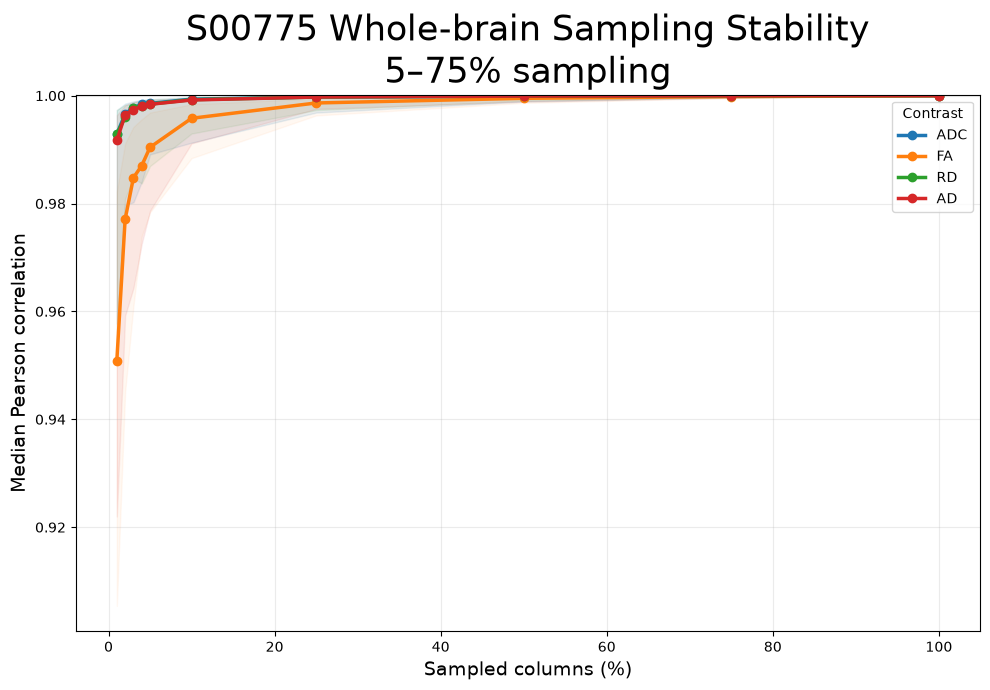

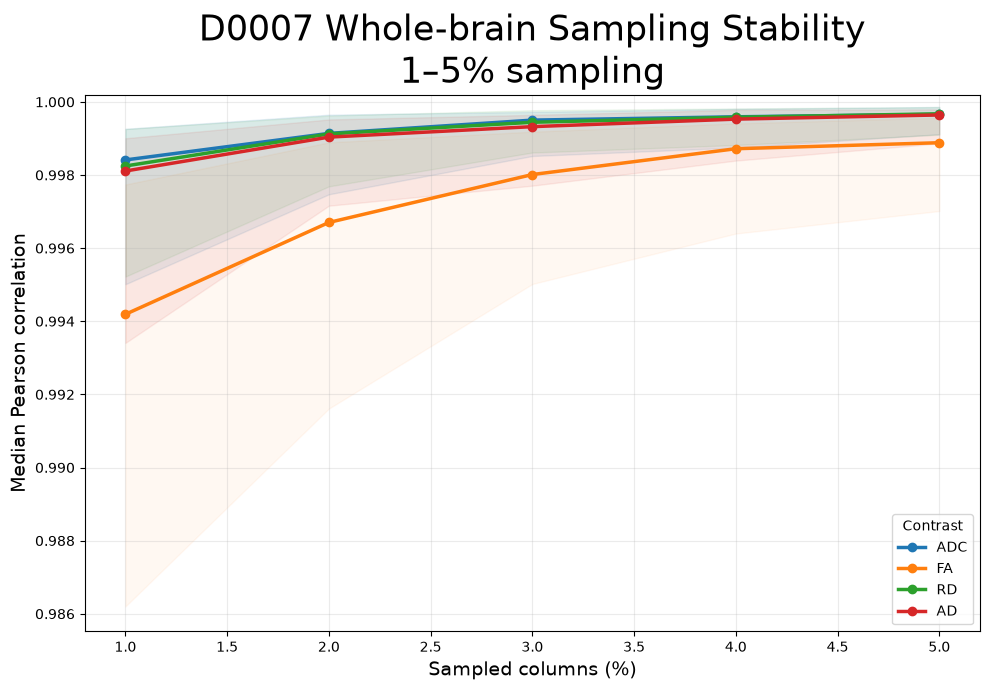

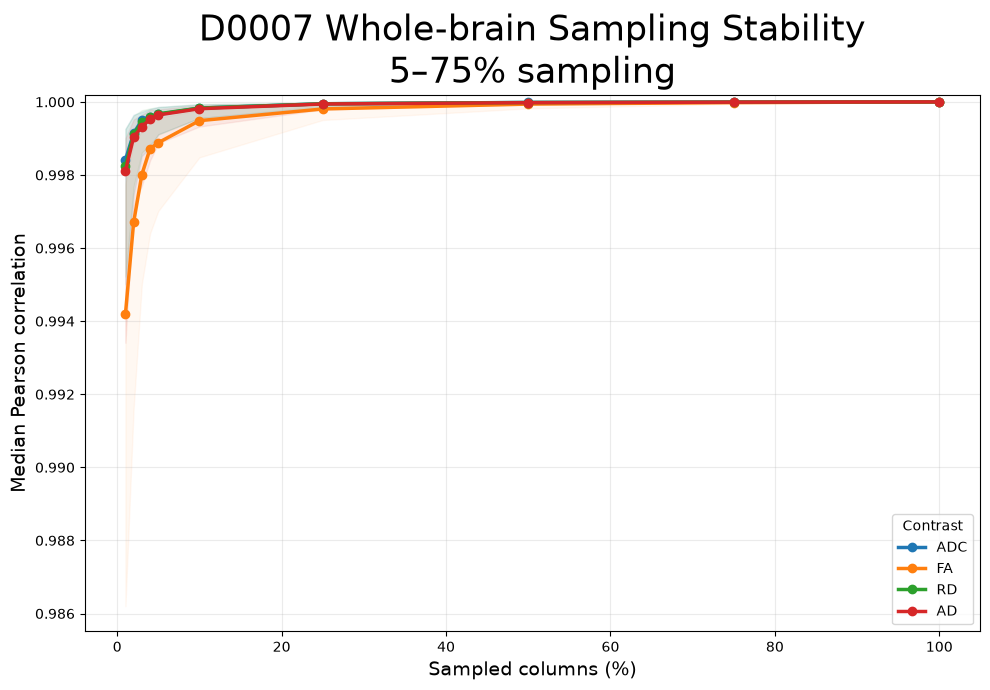

In [217]:
def plot_whole_brain_correlation(
    subject,
    fractions,
    scale_label,
):
    fig, ax = plt.subplots(
        figsize=(10, 7)
    )

    subject_df = (
        whole_brain_summary_df[
            (
                whole_brain_summary_df[
                    "subject"
                ]
                == subject
            )
            &
            (
                whole_brain_summary_df[
                    "sampling_fraction"
                ].isin(fractions)
            )
        ]
        .copy()
    )

    shade_alpha = {
        "adc": 0.10,
        "fa": 0.05,
        "rd": 0.08,
        "ad": 0.08,
    }

    for contrast in CONTRASTS:

        contrast_df = (
            subject_df[
                subject_df[
                    "contrast"
                ]
                == contrast
            ]
            .sort_values(
                "sampling_fraction"
            )
        )

        x = (
            contrast_df[
                "sampling_fraction"
            ].values
            * 100
        )

        median_r = (
            contrast_df[
                "median_correlation"
            ].values
        )

        q1 = (
            contrast_df[
                "q1_correlation"
            ].values
        )

        q3 = (
            contrast_df[
                "q3_correlation"
            ].values
        )

        line, = ax.plot(
            x,
            median_r,
            marker="o",
            linewidth=2.5,
            label=contrast.upper(),
        )

        ax.fill_between(
            x,
            q1,
            q3,
            color=line.get_color(),
            alpha=shade_alpha[contrast],
        )

    ax.set_title(
        (
            f"{subject} Whole-brain Sampling Stability\n"
            f"{scale_label}"
        ),
        fontsize=25,
    )

    ax.set_xlabel(
        "Sampled columns (%)",
        fontsize=14,
    )

    ax.set_ylabel(
        "Median Pearson correlation",
        fontsize=14,
    )

    # Let the lower bound adapt automatically
    ax.set_ylim(
        top=1.0002
    )

    ax.legend(
        title="Contrast",
        frameon=True,
        facecolor="white",
        edgecolor="#D0D0D0",
        framealpha=.90,
        fancybox=False,
        fontsize=7.5,
        borderpad=.35,
        labelspacing=.35,
        handlelength=1.8,
        handletextpad=.5,
    )

    ax.grid(
        alpha=0.25
    )

    plt.tight_layout()
    plt.show()


# S00775
plot_whole_brain_correlation(
    "S00775",
    SAMPLING_FRACTIONS,
    "5–75% sampling",
)


# D0007: fine scale
plot_whole_brain_correlation(
    "D0007",
    D0007_FINE_FRACTIONS,
    "1–5% sampling",
)


# D0007: current scale
plot_whole_brain_correlation(
    "D0007",
    SAMPLING_FRACTIONS,
    "5–75% sampling",
)

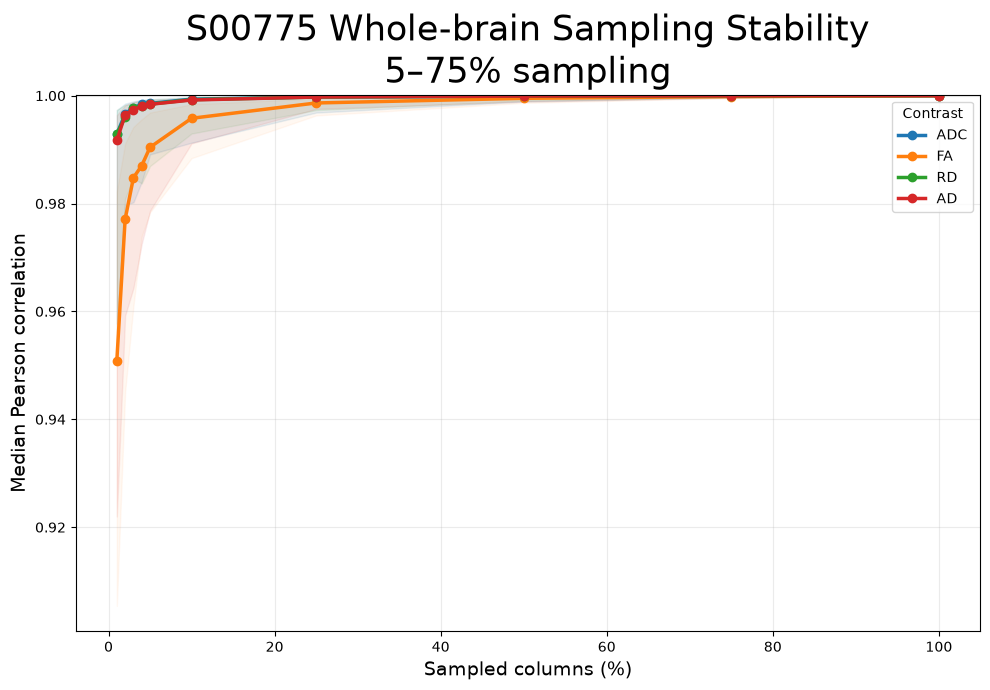

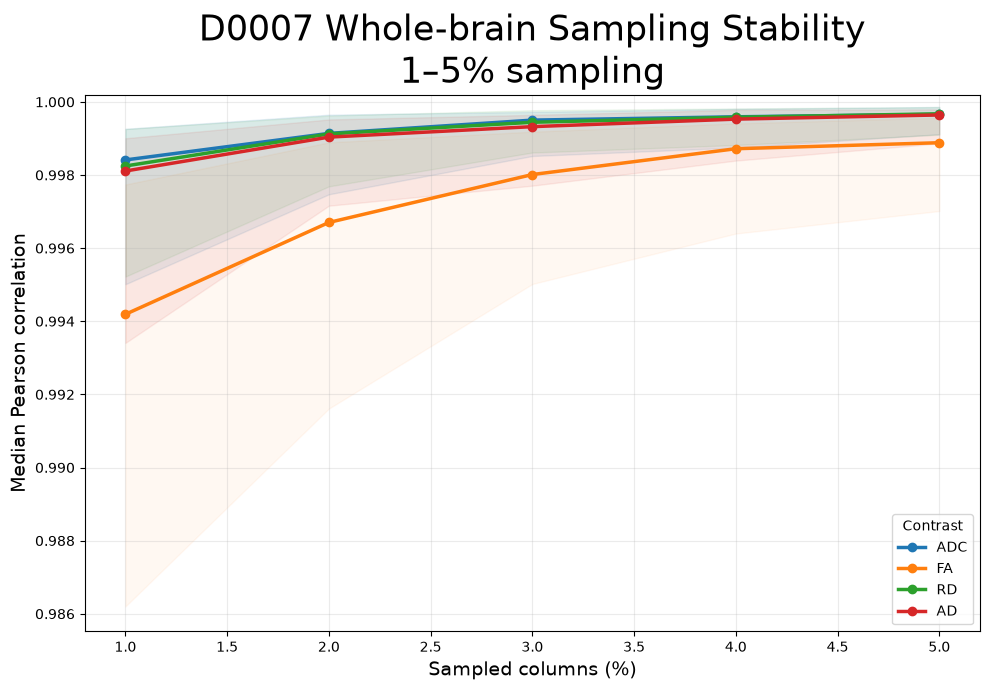

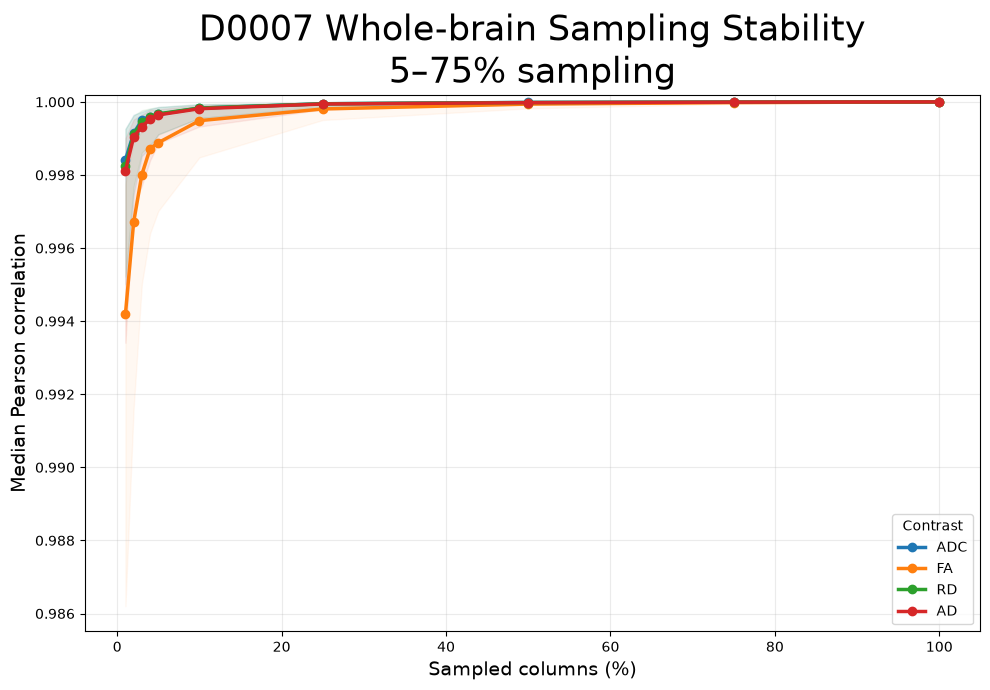

In [218]:
def plot_whole_brain_correlation(
    subject,
    fractions,
    scale_label,
):
    fig, ax = plt.subplots(
        figsize=(10, 7)
    )

    subject_df = (
        whole_brain_summary_df[
            (
                whole_brain_summary_df[
                    "subject"
                ]
                == subject
            )
            &
            (
                whole_brain_summary_df[
                    "sampling_fraction"
                ].isin(fractions)
            )
        ]
        .copy()
    )

    shade_alpha = {
        "adc": 0.10,
        "fa": 0.05,
        "rd": 0.08,
        "ad": 0.08,
    }

    for contrast in CONTRASTS:

        contrast_df = (
            subject_df[
                subject_df[
                    "contrast"
                ]
                == contrast
            ]
            .sort_values(
                "sampling_fraction"
            )
        )

        x = (
            contrast_df[
                "sampling_fraction"
            ].values
            * 100
        )

        median_r = (
            contrast_df[
                "median_correlation"
            ].values
        )

        q1 = (
            contrast_df[
                "q1_correlation"
            ].values
        )

        q3 = (
            contrast_df[
                "q3_correlation"
            ].values
        )

        line, = ax.plot(
            x,
            median_r,
            marker="o",
            linewidth=2.5,
            label=contrast.upper(),
        )

        ax.fill_between(
            x,
            q1,
            q3,
            color=line.get_color(),
            alpha=shade_alpha[contrast],
        )

    ax.set_title(
        (
            f"{subject} Whole-brain Sampling Stability\n"
            f"{scale_label}"
        ),
        fontsize=25,
    )

    ax.set_xlabel(
        "Sampled columns (%)",
        fontsize=14,
    )

    ax.set_ylabel(
        "Median Pearson correlation",
        fontsize=14,
    )

    # Let the lower bound adapt automatically
    ax.set_ylim(
        top=1.0002
    )

    ax.legend(
        title="Contrast",
        frameon=True,
        facecolor="white",
        edgecolor="#D0D0D0",
        framealpha=.90,
        fancybox=False,
        fontsize=7.5,
        borderpad=.35,
        labelspacing=.35,
        handlelength=1.8,
        handletextpad=.5,
    )

    ax.grid(
        alpha=0.25
    )

    plt.tight_layout()
    plt.show()


# S00775
plot_whole_brain_correlation(
    "S00775",
    SAMPLING_FRACTIONS,
    "5–75% sampling",
)


# D0007: fine scale
plot_whole_brain_correlation(
    "D0007",
    D0007_FINE_FRACTIONS,
    "1–5% sampling",
)


# D0007: current scale
plot_whole_brain_correlation(
    "D0007",
    SAMPLING_FRACTIONS,
    "5–75% sampling",
)

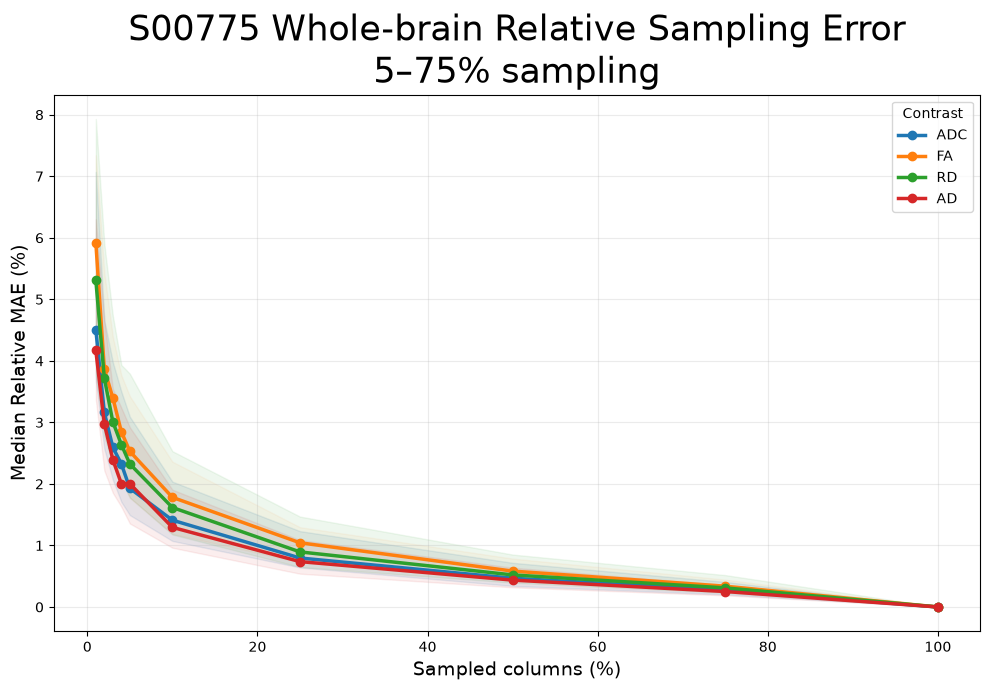

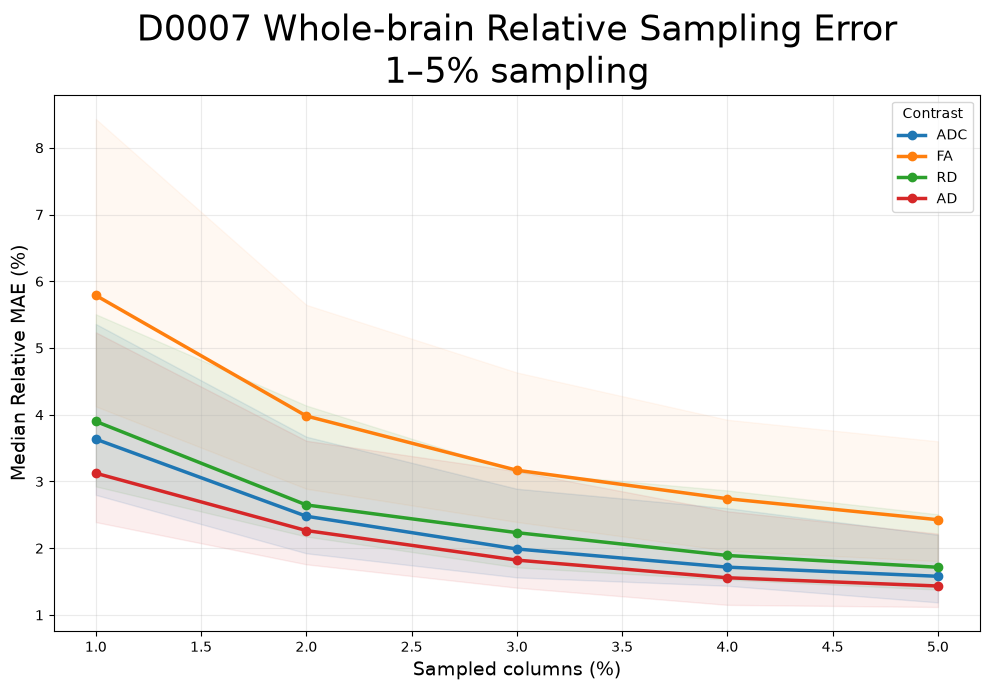

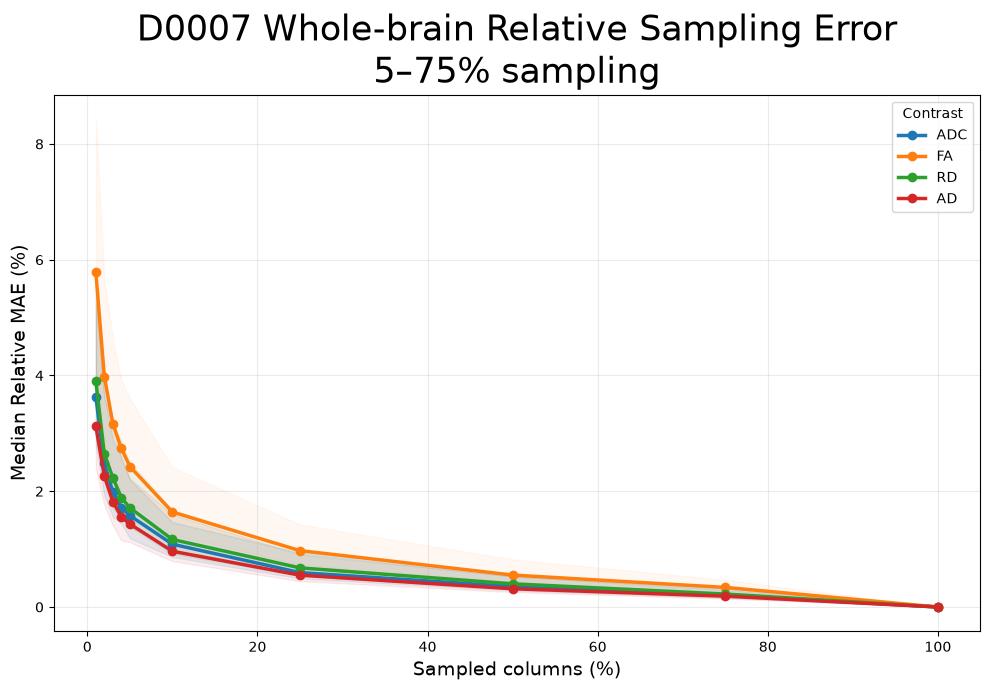

In [219]:
def plot_whole_brain_relative_mae(
    subject,
    fractions,
    scale_label,
):
    fig, ax = plt.subplots(
        figsize=(10, 7)
    )

    subject_df = (
        whole_brain_summary_df[
            (
                whole_brain_summary_df[
                    "subject"
                ]
                == subject
            )
            &
            (
                whole_brain_summary_df[
                    "sampling_fraction"
                ].isin(fractions)
            )
        ]
        .copy()
    )

    shade_alpha = {
        "adc": 0.10,
        "fa": 0.05,
        "rd": 0.08,
        "ad": 0.08,
    }

    for contrast in CONTRASTS:

        contrast_df = (
            subject_df[
                subject_df[
                    "contrast"
                ]
                == contrast
            ]
            .sort_values(
                "sampling_fraction"
            )
        )

        x = (
            contrast_df[
                "sampling_fraction"
            ].values
            * 100
        )

        median_mae = (
            contrast_df[
                "median_relative_mae"
            ].values
        )

        q1 = (
            contrast_df[
                "q1_relative_mae"
            ].values
        )

        q3 = (
            contrast_df[
                "q3_relative_mae"
            ].values
        )

        line, = ax.plot(
            x,
            median_mae,
            marker="o",
            linewidth=2.5,
            label=contrast.upper(),
        )

        ax.fill_between(
            x,
            q1,
            q3,
            color=line.get_color(),
            alpha=shade_alpha[contrast],
        )

    ax.set_title(
        (
            f"{subject} Whole-brain Relative Sampling Error\n"
            f"{scale_label}"
        ),
        fontsize=25,
    )

    ax.set_xlabel(
        "Sampled columns (%)",
        fontsize=14,
    )

    ax.set_ylabel(
        "Median Relative MAE (%)",
        fontsize=14,
    )

    ax.legend(
        title="Contrast",
        frameon=True,
        facecolor="white",
        edgecolor="#D0D0D0",
        framealpha=.90,
        fancybox=False,
        fontsize=7.5,
        borderpad=.35,
        labelspacing=.35,
        handlelength=1.8,
        handletextpad=.5,
    )

    ax.grid(
        alpha=0.25
    )

    plt.tight_layout()
    plt.show()


# S00775
plot_whole_brain_relative_mae(
    "S00775",
    SAMPLING_FRACTIONS,
    "5–75% sampling",
)


# D0007: fine scale
plot_whole_brain_relative_mae(
    "D0007",
    D0007_FINE_FRACTIONS,
    "1–5% sampling",
)


# D0007: current scale
plot_whole_brain_relative_mae(
    "D0007",
    SAMPLING_FRACTIONS,
    "5–75% sampling",
)

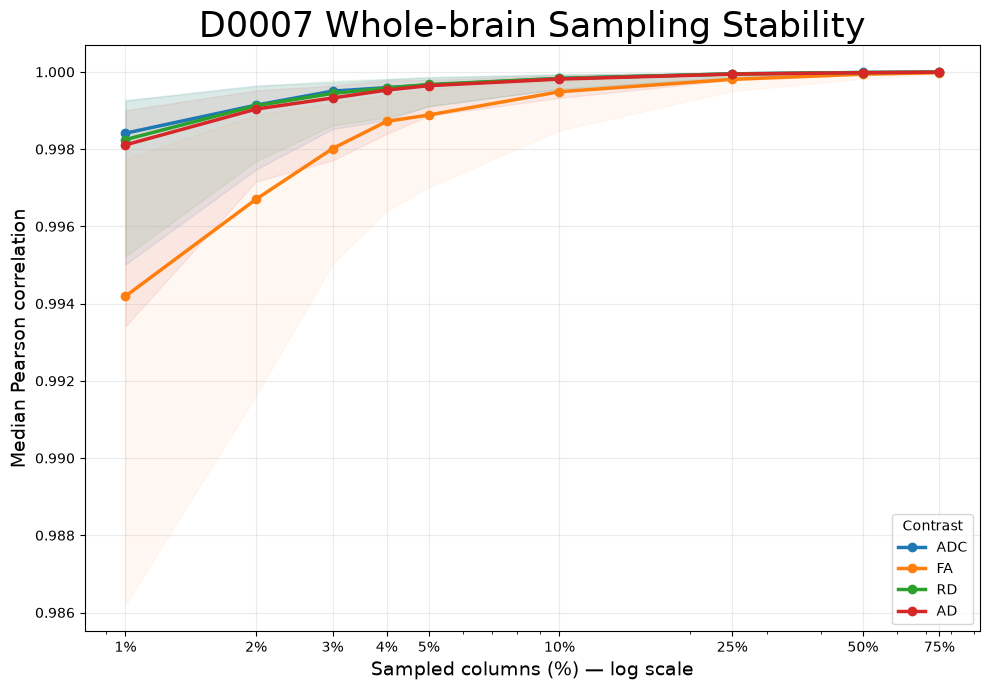

In [220]:
D0007_LOG_FRACTIONS = [
    0.01,
    0.02,
    0.03,
    0.04,
    0.05,
    0.10,
    0.25,
    0.50,
    0.75,
]


def plot_whole_brain_correlation_log(
    subject,
    fractions,
):
    fig, ax = plt.subplots(
        figsize=(10, 7)
    )

    subject_df = (
        whole_brain_summary_df[
            (
                whole_brain_summary_df["subject"]
                == subject
            )
            &
            (
                whole_brain_summary_df[
                    "sampling_fraction"
                ].isin(fractions)
            )
        ]
        .copy()
    )

    shade_alpha = {
        "adc": 0.10,
        "fa": 0.05,
        "rd": 0.08,
        "ad": 0.08,
    }

    for contrast in CONTRASTS:

        contrast_df = (
            subject_df[
                subject_df["contrast"]
                == contrast
            ]
            .sort_values(
                "sampling_fraction"
            )
        )

        x = (
            contrast_df[
                "sampling_fraction"
            ].values
            * 100
        )

        median_r = (
            contrast_df[
                "median_correlation"
            ].values
        )

        q1 = (
            contrast_df[
                "q1_correlation"
            ].values
        )

        q3 = (
            contrast_df[
                "q3_correlation"
            ].values
        )

        line, = ax.plot(
            x,
            median_r,
            marker="o",
            linewidth=2.5,
            label=contrast.upper(),
        )

        ax.fill_between(
            x,
            q1,
            q3,
            color=line.get_color(),
            alpha=shade_alpha[contrast],
        )

    ax.set_xscale("log")

    ax.set_xticks(
        [1, 2, 3, 4, 5, 10, 25, 50, 75]
    )

    ax.set_xticklabels(
        [
            "1%",
            "2%",
            "3%",
            "4%",
            "5%",
            "10%",
            "25%",
            "50%",
            "75%",
        ]
    )

    ax.set_title(
        "D0007 Whole-brain Sampling Stability",
        fontsize=25,
    )

    ax.set_xlabel(
        "Sampled columns (%) — log scale",
        fontsize=14,
    )

    ax.set_ylabel(
        "Median Pearson correlation",
        fontsize=14,
    )

    ax.legend(
        title="Contrast",
        frameon=True,
        facecolor="white",
        edgecolor="#D0D0D0",
        framealpha=.90,
        fancybox=False,
        fontsize=7.5,
        borderpad=.35,
        labelspacing=.35,
        handlelength=1.8,
        handletextpad=.5,
    )

    ax.grid(
        alpha=0.25
    )

    plt.tight_layout()
    plt.show()


plot_whole_brain_correlation_log(
    "D0007",
    D0007_LOG_FRACTIONS,
)

## D0007 Low-Sampling Boundary

Additional low sampling levels are tested for D0007 because regional profiles remain highly stable at 5% sampling.

In [221]:
LOW_SAMPLING_FRACTIONS = [
    0.01,
    0.02,
    0.03,
    0.05,
]

d0007_low_sampling_results = []

subject = "D0007"

file_subject = get_file_subject(subject)
suffix = PATHS[subject]["file_suffix"]

for file_path in get_profile_files(subject):

    region_label = file_path.name[
        len(file_subject) + 1:
        -len(suffix)
    ]

    hemisphere, region = region_label.split(
        "_",
        1,
    )

    values = load_profile(file_path)

    total_trajectories = values.shape[0]

    full_profile = values.mean(
        axis=0
    )

    for fraction in LOW_SAMPLING_FRACTIONS:

        sample_n = max(
            1,
            round(total_trajectories * fraction),
        )

        for repeat in range(N_REPEATS):

            indices = rng.choice(
                total_trajectories,
                size=sample_n,
                replace=False,
            )

            sample_profile = values[
                indices
            ].mean(
                axis=0
            )

            mae, rmse, correlation = compare_profiles(
                sample_profile,
                full_profile,
            )

            d0007_low_sampling_results.append(
                {
                    "subject": subject,
                    "hemisphere": hemisphere,
                    "region": region,
                    "total_trajectories": total_trajectories,
                    "sampling_fraction": fraction,
                    "sample_n": sample_n,
                    "repeat": repeat + 1,
                    "mae": mae,
                    "rmse": rmse,
                    "correlation": correlation,
                }
            )


d0007_low_sampling_df = pd.DataFrame(
    d0007_low_sampling_results
)

d0007_low_sampling_df

KeyError: 'file_suffix'

In [ ]:
d0007_low_region_summary_df = (
    d0007_low_sampling_df
    .groupby(
        [
            "subject",
            "hemisphere",
            "region",
            "sampling_fraction",
        ]
    )
    .agg(
        sample_n=("sample_n", "first"),
        median_mae=("mae", "median"),
        median_rmse=("rmse", "median"),
        median_correlation=("correlation", "median"),
    )
    .reset_index()
)

d0007_low_region_summary_df

,subject,hemisphere,region,sampling_fraction,sample_n,median_mae,median_rmse,median_correlation
0,D0007,lh,bankssts,0.01,12,0.000041,0.000051,0.994005
1,D0007,lh,bankssts,0.02,24,0.000026,0.000033,0.997287
2,D0007,lh,bankssts,0.03,36,0.000022,0.000027,0.998415
3,D0007,lh,bankssts,0.05,60,0.000017,0.000022,0.998940
4,D0007,lh,caudalanteriorcingulate,0.01,8,0.000057,0.000066,0.986020
...,...,...,...,...,...,...,...,...
267,D0007,rh,temporalpole,0.05,31,0.000038,0.000045,0.998880
268,D0007,rh,transversetemporal,0.01,5,0.000085,0.000098,0.997299
269,D0007,rh,transversetemporal,0.02,10,0.000063,0.000079,0.998794
270,D0007,rh,transversetemporal,0.03,15,0.000060,0.000070,0.999117


In [ ]:
# D0007 main region-level summary
d0007_main_region_df = region_summary_df[
    region_summary_df["subject"] == "D0007"
].copy()

# D0007 low-sampling region-level summary
d0007_low_region_df = d0007_low_region_summary_df.copy()

# Merge low and main summaries
d0007_combined_region_df = pd.concat(
    [
        d0007_low_region_df,
        d0007_main_region_df,
    ],
    ignore_index=True,
)

# Remove duplicate 5% rows from the low-sampling table
d0007_combined_region_df = (
    d0007_combined_region_df
    .sort_values(["sampling_fraction"])
    .drop_duplicates(
        subset=["hemisphere", "region", "sampling_fraction"],
        keep="last",
    )
)

# Summarize across regions
d0007_boundary_summary_df = (
    d0007_combined_region_df
    .groupby("sampling_fraction")
    .agg(
        median_correlation=("median_correlation", "median"),
        q1_correlation=("median_correlation", lambda x: x.quantile(0.25)),
        q3_correlation=("median_correlation", lambda x: x.quantile(0.75)),
        p10_correlation=("median_correlation", lambda x: x.quantile(0.10)),
    )
    .reset_index()
)

d0007_boundary_summary_df["sampling_percent"] = (
    d0007_boundary_summary_df["sampling_fraction"] * 100
)

d0007_boundary_summary_df

,sampling_fraction,median_correlation,q1_correlation,q3_correlation,p10_correlation,sampling_percent
0,0.01,0.998226,0.994708,0.999175,0.988460,1.0
1,0.02,0.999114,0.997570,0.999624,0.993745,2.0
2,0.03,0.999451,0.998520,0.999755,0.995783,3.0
3,0.05,0.999643,0.998945,0.999869,0.997710,5.0
4,0.10,0.999851,0.999558,0.999924,0.999032,10.0
5,0.25,0.999951,0.999866,0.999977,0.999668,25.0
6,0.50,0.999983,0.999949,0.999993,0.999886,50.0
7,0.75,0.999993,0.999985,0.999997,0.999964,75.0
8,1.00,1.000000,1.000000,1.000000,1.000000,100.0


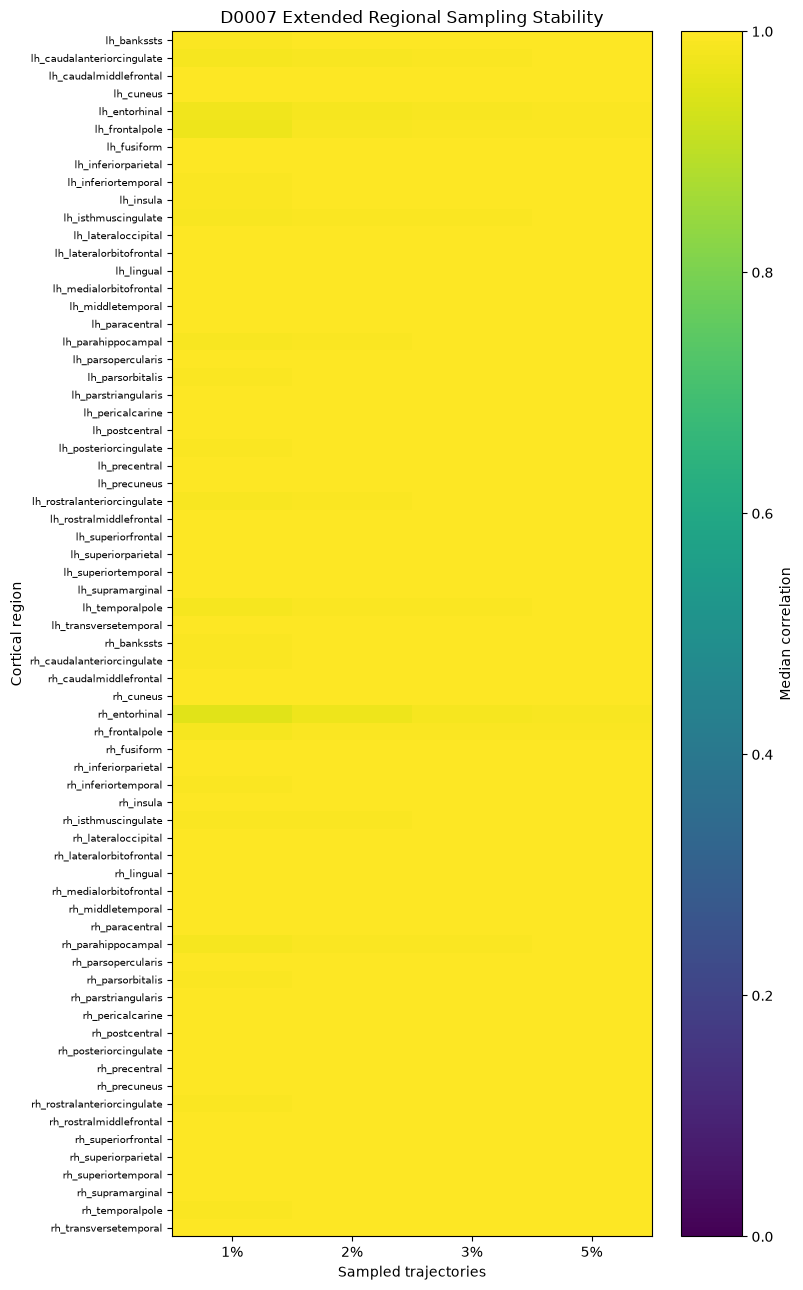

In [ ]:
# Combine D0007 low-sampling and main regional summaries
d0007_extended_df = pd.concat(
    [
        d0007_low_region_summary_df,
        region_summary_df[
            region_summary_df["subject"] == "D0007"
        ],
    ],
    ignore_index=True,
)

# Keep only one 5% result
d0007_extended_df = (
    d0007_extended_df
    .drop_duplicates(
        subset=[
            "hemisphere",
            "region",
            "sampling_fraction",
        ],
        keep="last",
    )
)

# Create region label
d0007_extended_df["region_label"] = (
    d0007_extended_df["hemisphere"]
    + "_"
    + d0007_extended_df["region"]
)

# Pivot for heatmap
heatmap_df = (
    d0007_extended_df
    .pivot(
        index="region_label",
        columns="sampling_fraction",
        values="median_correlation",
    )
)

sampling_order = [
    0.01,
    0.02,
    0.03,
    0.05,
]

heatmap_df = heatmap_df[
    sampling_order
]

# Plot
fig, ax = plt.subplots(
    figsize=(8, 13)
)

image = ax.imshow(
    heatmap_df.values,
    aspect="auto",
    vmin=0,
    vmax=1,
)

ax.set_yticks(
    range(len(heatmap_df.index))
)

ax.set_yticklabels(
    heatmap_df.index,
    fontsize=7,
)

ax.set_xticks(
    range(len(sampling_order))
)

ax.set_xticklabels(
    [
        "1%",
        "2%",
        "3%",
        "5%",
    ]
)

ax.set_xlabel(
    "Sampled trajectories"
)

ax.set_ylabel(
    "Cortical region"
)

ax.set_title(
    "D0007 Extended Regional Sampling Stability"
)

colorbar = plt.colorbar(
    image,
    ax=ax,
)

colorbar.set_label(
    "Median correlation"
)

plt.tight_layout()
plt.show()

## Minimum Stable Sampling

Regional sampling stability is defined using the correlation between the sampled and full 21-point ADC profiles.

A region is considered stable when the median correlation across repeated random samples reaches at least 0.95. The minimum tested sampling fraction meeting this criterion is identified for each cortical region.

In [ ]:
STABILITY_THRESHOLD = 0.95

# S00775: use the main sampling experiment
s00775_stability_df = (
    region_summary_df[
        region_summary_df["subject"] == "S00775"
    ]
    .copy()
)

# D0007: add 1%, 2%, and 3% to the main sampling experiment
# Keep the 5% result from the main experiment to avoid duplication
d0007_stability_df = pd.concat(
    [
        d0007_low_region_summary_df[
            d0007_low_region_summary_df["sampling_fraction"] < 0.05
        ],
        region_summary_df[
            region_summary_df["subject"] == "D0007"
        ],
    ],
    ignore_index=True,
)

# Combine the two main subjects
stability_df = pd.concat(
    [
        s00775_stability_df,
        d0007_stability_df,
    ],
    ignore_index=True,
)

# Define stable regional profiles
stability_df["stable"] = (
    stability_df["median_correlation"]
    >= STABILITY_THRESHOLD
)


# 1. Stable regions at each sampling fraction
stable_fraction_summary_df = (
    stability_df
    .groupby(
        [
            "subject",
            "sampling_fraction",
        ]
    )
    .agg(
        n_regions=("region", "count"),
        n_stable=("stable", "sum"),
        median_correlation=("median_correlation", "median"),
    )
    .reset_index()
)

stable_fraction_summary_df["stable_proportion"] = (
    stable_fraction_summary_df["n_stable"]
    / stable_fraction_summary_df["n_regions"]
)

stable_fraction_summary_df["stable_percent"] = (
    stable_fraction_summary_df["stable_proportion"]
    * 100
)


# 2. Minimum stable sampling fraction for each region
minimum_stable_sampling_df = (
    stability_df[
        stability_df["stable"]
    ]
    .sort_values(
        [
            "subject",
            "hemisphere",
            "region",
            "sampling_fraction",
        ]
    )
    .groupby(
        [
            "subject",
            "hemisphere",
            "region",
        ],
        as_index=False,
    )
    .first()
)

minimum_stable_sampling_df = (
    minimum_stable_sampling_df[
        [
            "subject",
            "hemisphere",
            "region",
            "sampling_fraction",
            "sample_n",
            "median_correlation",
        ]
    ]
    .rename(
        columns={
            "sampling_fraction": "minimum_stable_fraction",
            "sample_n": "minimum_sample_n",
        }
    )
)


print("Stable regions by sampling fraction")
display(
    stable_fraction_summary_df[
        [
            "subject",
            "sampling_fraction",
            "n_stable",
            "n_regions",
            "stable_percent",
            "median_correlation",
        ]
    ]
)

print("\nMinimum stable sampling by region")
display(minimum_stable_sampling_df)

Stable regions by sampling fraction


,subject,sampling_fraction,n_stable,n_regions,stable_percent,median_correlation
0,D0007,0.01,68,68,100.000000,0.998226
1,D0007,0.02,68,68,100.000000,0.999114
2,D0007,0.03,68,68,100.000000,0.999451
3,D0007,0.05,68,68,100.000000,0.999639
4,D0007,0.10,68,68,100.000000,0.999851
5,D0007,0.25,68,68,100.000000,0.999951
6,D0007,0.50,68,68,100.000000,0.999983
7,D0007,0.75,68,68,100.000000,0.999993
8,D0007,1.00,68,68,100.000000,1.000000
9,S00775,0.05,57,68,83.823529,0.998540



Minimum stable sampling by region


,subject,hemisphere,region,minimum_stable_fraction,minimum_sample_n,median_correlation
0,D0007,lh,bankssts,0.01,12,0.994005
1,D0007,lh,caudalanteriorcingulate,0.01,8,0.986020
2,D0007,lh,caudalmiddlefrontal,0.01,31,0.998748
3,D0007,lh,cuneus,0.01,23,0.998797
4,D0007,lh,entorhinal,0.01,7,0.980325
...,...,...,...,...,...,...
131,S00775,rh,superiorparietal,0.05,351,0.998823
132,S00775,rh,superiortemporal,0.05,287,0.998566
133,S00775,rh,supramarginal,0.05,269,0.999701
134,S00775,rh,temporalpole,0.25,132,0.977717


## Reliable Sampling Stability

A cortical region is considered reliably stable when the 10th percentile of correlation across repeated random samples reaches at least 0.95.

This criterion requires the sampled profile to remain highly correlated with the full profile in approximately 90% of repeated samplings.

In [ ]:
RELIABILITY_THRESHOLD = 0.95

# S00775: main sampling results
s00775_repeat_df = sampling_results_df[
    sampling_results_df["subject"] == "S00775"
].copy()

# D0007: combine low sampling with main sampling
# Use low-sampling results for 1%, 2%, 3%
# Use main results from 5% upward
d0007_repeat_df = pd.concat(
    [
        d0007_low_sampling_df[
            d0007_low_sampling_df["sampling_fraction"] < 0.05
        ],
        sampling_results_df[
            (sampling_results_df["subject"] == "D0007")
            & (sampling_results_df["sampling_fraction"] >= 0.05)
        ],
    ],
    ignore_index=True,
)

# Combine subjects
reliable_sampling_df = pd.concat(
    [
        d0007_repeat_df,
        s00775_repeat_df,
    ],
    ignore_index=True,
)

# P10 correlation for each region and sampling fraction
region_reliability_df = (
    reliable_sampling_df
    .groupby(
        [
            "subject",
            "hemisphere",
            "region",
            "sampling_fraction",
        ]
    )
    .agg(
        sample_n=("sample_n", "first"),
        median_correlation=("correlation", "median"),
        p10_correlation=("correlation", lambda x: x.quantile(0.10)),
    )
    .reset_index()
)

region_reliability_df["reliably_stable"] = (
    region_reliability_df["p10_correlation"]
    >= RELIABILITY_THRESHOLD
)

# Summary across 68 regions
reliable_fraction_summary_df = (
    region_reliability_df
    .groupby(
        [
            "subject",
            "sampling_fraction",
        ]
    )
    .agg(
        n_regions=("region", "count"),
        n_reliably_stable=("reliably_stable", "sum"),
        median_p10_correlation=("p10_correlation", "median"),
    )
    .reset_index()
)

reliable_fraction_summary_df["reliable_percent"] = (
    reliable_fraction_summary_df["n_reliably_stable"]
    / reliable_fraction_summary_df["n_regions"]
    * 100
)

print("Reliably stable regions by sampling fraction")
display(reliable_fraction_summary_df)

Reliably stable regions by sampling fraction


,subject,sampling_fraction,n_regions,n_reliably_stable,median_p10_correlation,reliable_percent
0,D0007,0.01,68,62,0.992683,91.176471
1,D0007,0.02,68,66,0.996442,97.058824
2,D0007,0.03,68,67,0.997721,98.529412
3,D0007,0.05,68,68,0.998753,100.000000
4,D0007,0.10,68,68,0.999349,100.000000
5,D0007,0.25,68,68,0.999824,100.000000
6,D0007,0.50,68,68,0.999935,100.000000
7,D0007,0.75,68,68,0.999977,100.000000
8,D0007,1.00,68,68,1.000000,100.000000
9,S00775,0.05,68,50,0.994738,73.529412


## Reliable Regional Stability Across Sampling Levels

The proportion of cortical regions meeting the reliable stability criterion is summarized across trajectory sampling levels.

Reliable stability is defined as a 10th-percentile correlation of at least 0.95 across repeated random samplings.

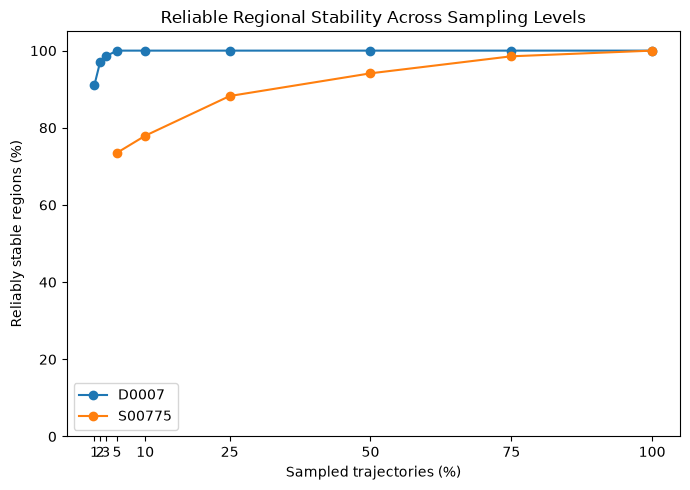

In [ ]:
plot_df = reliable_fraction_summary_df.copy()

plot_df["sampling_percent"] = (
    plot_df["sampling_fraction"] * 100
)

plt.figure(figsize=(7, 5))

for subject in ["D0007", "S00775"]:

    subject_df = (
        plot_df[
            plot_df["subject"] == subject
        ]
        .sort_values("sampling_percent")
    )

    plt.plot(
        subject_df["sampling_percent"],
        subject_df["reliable_percent"],
        marker="o",
        label=subject,
    )

plt.xlabel("Sampled trajectories (%)")
plt.ylabel("Reliably stable regions (%)")
plt.title(
    "Reliable Regional Stability Across Sampling Levels"
)

plt.xticks(
    [1, 2, 3, 5, 10, 25, 50, 75, 100]
)

plt.ylim(0, 105)
plt.legend(frameon=True, facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)

plt.tight_layout()
plt.show()

## Sampling Convergence Analysis

Sampling convergence is evaluated by examining how closely the sampled regional ADC profiles approach the full-sampling reference as trajectory sampling increases.

Median correlation and its lower-tail stability are summarized across cortical regions.

In [ ]:
# Build convergence summary

# D0007: use low sampling for 1%, 2%, 3% and main sampling from 5% upward
d0007_convergence_df = pd.concat(
    [
        d0007_low_region_summary_df[
            d0007_low_region_summary_df["sampling_fraction"] < 0.05
        ],
        region_summary_df[
            region_summary_df["subject"] == "D0007"
        ],
    ],
    ignore_index=True,
)

# S00775: use main sampling results
s00775_convergence_df = (
    region_summary_df[
        region_summary_df["subject"] == "S00775"
    ]
    .copy()
)

# Combine
convergence_region_df = pd.concat(
    [
        d0007_convergence_df,
        s00775_convergence_df,
    ],
    ignore_index=True,
)

# Summarize across 68 regions
convergence_summary_df = (
    convergence_region_df
    .groupby(
        [
            "subject",
            "sampling_fraction",
        ]
    )
    .agg(
        median_correlation=("median_correlation", "median"),
        q1_correlation=("median_correlation", lambda x: x.quantile(0.25)),
        p10_correlation=("median_correlation", lambda x: x.quantile(0.10)),
        median_mae=("median_mae", "median"),
    )
    .reset_index()
)

convergence_summary_df["sampling_percent"] = (
    convergence_summary_df["sampling_fraction"] * 100
)

display(convergence_summary_df)

,subject,sampling_fraction,median_correlation,q1_correlation,p10_correlation,median_mae,sampling_percent
0,D0007,0.01,0.998226,0.994708,0.988460,0.000032,1.0
1,D0007,0.02,0.999114,0.997570,0.993745,0.000022,2.0
2,D0007,0.03,0.999451,0.998520,0.995783,0.000018,3.0
3,D0007,0.05,0.999639,0.999100,0.997710,0.000014,5.0
4,D0007,0.10,0.999851,0.999558,0.999032,0.000009,10.0
5,D0007,0.25,0.999951,0.999866,0.999668,0.000005,25.0
6,D0007,0.50,0.999983,0.999949,0.999886,0.000003,50.0
7,D0007,0.75,0.999993,0.999985,0.999964,0.000002,75.0
8,D0007,1.00,1.000000,1.000000,1.000000,0.000000,100.0
9,S00775,0.05,0.998540,0.986993,0.916917,0.000017,5.0


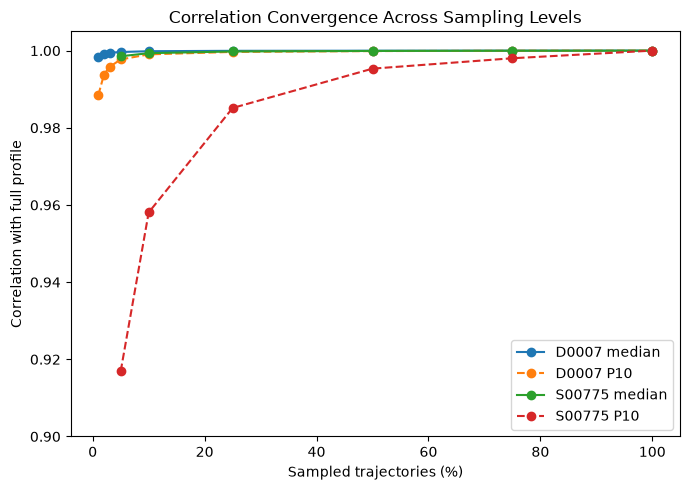

In [ ]:
plt.figure(figsize=(7, 5))

for subject in ["D0007", "S00775"]:
    subject_df = (
        convergence_summary_df[
            convergence_summary_df["subject"] == subject
        ]
        .sort_values("sampling_percent")
    )

    plt.plot(
        subject_df["sampling_percent"],
        subject_df["median_correlation"],
        marker="o",
        label=f"{subject} median",
    )

    plt.plot(
        subject_df["sampling_percent"],
        subject_df["p10_correlation"],
        marker="o",
        linestyle="--",
        label=f"{subject} P10",
    )

plt.xlabel("Sampled trajectories (%)")
plt.ylabel("Correlation with full profile")
plt.title("Correlation Convergence Across Sampling Levels")

plt.ylim(0.9, 1.005)

plt.legend(frameon=True, facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)
plt.tight_layout()
plt.show()

## Incremental Convergence

The improvement in lower-tail correlation stability is evaluated between consecutive sampling levels.

Smaller gains at higher sampling fractions indicate that the regional profiles are approaching a convergence plateau.

In [ ]:
incremental_convergence_df = (
    convergence_summary_df[
        [
            "subject",
            "sampling_fraction",
            "sampling_percent",
            "p10_correlation",
        ]
    ]
    .sort_values(
        [
            "subject",
            "sampling_fraction",
        ]
    )
    .copy()
)

incremental_convergence_df["previous_p10"] = (
    incremental_convergence_df
    .groupby("subject")["p10_correlation"]
    .shift(1)
)

incremental_convergence_df["p10_improvement"] = (
    incremental_convergence_df["p10_correlation"]
    - incremental_convergence_df["previous_p10"]
)

incremental_convergence_df["previous_sampling_percent"] = (
    incremental_convergence_df
    .groupby("subject")["sampling_percent"]
    .shift(1)
)

incremental_convergence_df["sampling_step"] = (
    incremental_convergence_df[
        "previous_sampling_percent"
    ].astype("Int64").astype(str)
    + "% → "
    + incremental_convergence_df[
        "sampling_percent"
    ].astype(int).astype(str)
    + "%"
)

display(
    incremental_convergence_df[
        [
            "subject",
            "sampling_step",
            "p10_correlation",
            "p10_improvement",
        ]
    ].dropna()
)

,subject,sampling_step,p10_correlation,p10_improvement
1,D0007,1% → 2%,0.993745,0.005286
2,D0007,2% → 3%,0.995783,0.002037
3,D0007,3% → 5%,0.997710,0.001928
4,D0007,5% → 10%,0.999032,0.001322
5,D0007,10% → 25%,0.999668,0.000636
6,D0007,25% → 50%,0.999886,0.000218
7,D0007,50% → 75%,0.999964,0.000079
8,D0007,75% → 100%,1.000000,0.000036
10,S00775,5% → 10%,0.958055,0.041137
11,S00775,10% → 25%,0.985133,0.027079


In [ ]:
incremental_convergence_df["sampling_increment"] = (
    incremental_convergence_df["sampling_percent"]
    - incremental_convergence_df["previous_sampling_percent"]
)

incremental_convergence_df["p10_improvement_per_percent"] = (
    incremental_convergence_df["p10_improvement"]
    / incremental_convergence_df["sampling_increment"]
)

display(
    incremental_convergence_df[
        [
            "subject",
            "sampling_step",
            "p10_improvement",
            "p10_improvement_per_percent",
        ]
    ].dropna()
)

,subject,sampling_step,p10_improvement,p10_improvement_per_percent
1,D0007,1% → 2%,0.005286,0.005286
2,D0007,2% → 3%,0.002037,0.002037
3,D0007,3% → 5%,0.001928,0.000964
4,D0007,5% → 10%,0.001322,0.000264
5,D0007,10% → 25%,0.000636,0.000042
6,D0007,25% → 50%,0.000218,0.000009
7,D0007,50% → 75%,0.000079,0.000003
8,D0007,75% → 100%,0.000036,0.000001
10,S00775,5% → 10%,0.041137,0.008227
11,S00775,10% → 25%,0.027079,0.001805


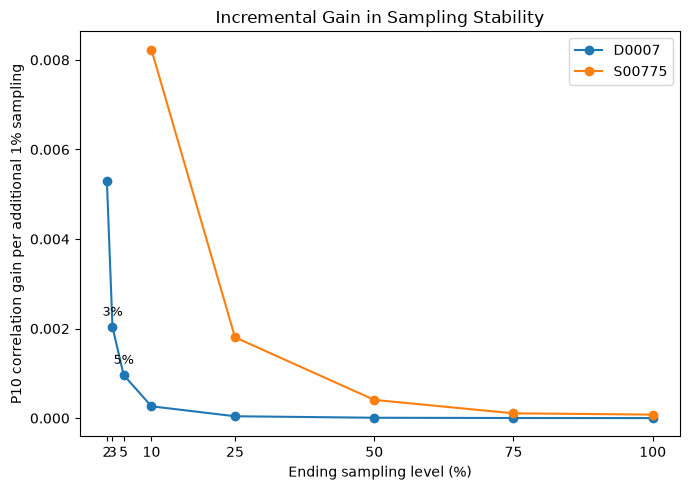

In [ ]:
plot_df = incremental_convergence_df.dropna(
    subset=["p10_improvement_per_percent"]
).copy()

plt.figure(figsize=(7, 5))

for subject in ["D0007", "S00775"]:

    subject_df = (
        plot_df[
            plot_df["subject"] == subject
        ]
        .sort_values("sampling_percent")
    )

    plt.plot(
        subject_df["sampling_percent"],
        subject_df["p10_improvement_per_percent"],
        marker="o",
        label=subject,
    )

    # Only label 3% and 5% for D0007
    if subject == "D0007":

        for _, row in subject_df.iterrows():

            if row["sampling_percent"] in [3, 5]:

                plt.annotate(
                    f"{int(row['sampling_percent'])}%",
                    (
                        row["sampling_percent"],
                        row["p10_improvement_per_percent"],
                    ),
                    xytext=(0, 8),
                    textcoords="offset points",
                    ha="center",
                    fontsize=9,
                )

plt.xlabel("Ending sampling level (%)")

plt.ylabel(
    "P10 correlation gain per additional 1% sampling"
)

plt.title(
    "Incremental Gain in Sampling Stability"
)

plt.xticks(
    [2, 3, 5, 10, 25, 50, 75, 100]
)

plt.legend(frameon=True, facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)

plt.tight_layout()
plt.show()

## Regions Most Sensitive to Trajectory Sampling

Cortical regions are ranked by the minimum sampling fraction required to achieve reliable stability. Regions requiring a larger sampling fraction are considered more sampling-sensitive.

When regions require the same minimum sampling fraction, the 10th-percentile correlation at 5% sampling is used to further rank their stability.

In [ ]:
# Build minimum reliable sampling table directly
minimum_reliable_sampling_df = (
    region_reliability_df[
        region_reliability_df["reliably_stable"]
    ]
    .sort_values(
        [
            "subject",
            "hemisphere",
            "region",
            "sampling_fraction",
        ]
    )
    .groupby(
        [
            "subject",
            "hemisphere",
            "region",
        ],
        as_index=False,
    )
    .first()
)

minimum_reliable_sampling_df = (
    minimum_reliable_sampling_df[
        [
            "subject",
            "hemisphere",
            "region",
            "sampling_fraction",
            "sample_n",
            "p10_correlation",
        ]
    ]
    .rename(
        columns={
            "sampling_fraction": "minimum_reliable_fraction",
            "sample_n": "minimum_sample_n",
        }
    )
)

# Get 5% P10 results for ranking
p10_at_5pct_df = (
    region_reliability_df[
        region_reliability_df["sampling_fraction"] == 0.05
    ][
        [
            "subject",
            "hemisphere",
            "region",
            "p10_correlation",
        ]
    ]
    .rename(
        columns={
            "p10_correlation": "p10_correlation_5pct"
        }
    )
)

# Combine minimum reliable sampling with 5% performance
sampling_sensitivity_df = (
    minimum_reliable_sampling_df
    .merge(
        p10_at_5pct_df,
        on=[
            "subject",
            "hemisphere",
            "region",
        ],
        how="left",
    )
)

# Rank difficult regions
sampling_sensitivity_df = (
    sampling_sensitivity_df
    .sort_values(
        [
            "subject",
            "minimum_reliable_fraction",
            "p10_correlation_5pct",
        ],
        ascending=[
            True,
            False,
            True,
        ],
    )
)

sampling_sensitivity_df["rank"] = (
    sampling_sensitivity_df
    .groupby("subject")
    .cumcount()
    + 1
)

top10_regions_df = (
    sampling_sensitivity_df[
        sampling_sensitivity_df["rank"] <= 10
    ]
    .copy()
)

top5_regions_df = (
    sampling_sensitivity_df[
        sampling_sensitivity_df["rank"] <= 5
    ]
    .copy()
)

print("Top 5 sampling-sensitive regions")
display(
    top5_regions_df[
        [
            "subject",
            "rank",
            "hemisphere",
            "region",
            "minimum_reliable_fraction",
            "minimum_sample_n",
            "p10_correlation_5pct",
        ]
    ]
)

print("\nTop 10 sampling-sensitive regions")
display(
    top10_regions_df[
        [
            "subject",
            "rank",
            "hemisphere",
            "region",
            "minimum_reliable_fraction",
            "minimum_sample_n",
            "p10_correlation_5pct",
        ]
    ]
)

Top 5 sampling-sensitive regions


,subject,rank,hemisphere,region,minimum_reliable_fraction,minimum_sample_n,p10_correlation_5pct
38,D0007,1,rh,entorhinal,0.05,33,0.965777
4,D0007,2,lh,entorhinal,0.03,20,0.981708
39,D0007,3,rh,frontalpole,0.02,8,0.982779
5,D0007,4,lh,frontalpole,0.02,6,0.984182
1,D0007,5,lh,caudalanteriorcingulate,0.02,16,0.987136
106,S00775,1,rh,entorhinal,1.00,491,-0.209962
79,S00775,2,lh,lateraloccipital,0.75,5000,-0.708357
72,S00775,3,lh,entorhinal,0.75,439,-0.101921
110,S00775,4,rh,inferiortemporal,0.75,2722,0.389895
73,S00775,5,lh,frontalpole,0.50,169,-0.816647



Top 10 sampling-sensitive regions


,subject,rank,hemisphere,region,minimum_reliable_fraction,minimum_sample_n,p10_correlation_5pct
38,D0007,1,rh,entorhinal,0.05,33,0.965777
4,D0007,2,lh,entorhinal,0.03,20,0.981708
39,D0007,3,rh,frontalpole,0.02,8,0.982779
5,D0007,4,lh,frontalpole,0.02,6,0.984182
1,D0007,5,lh,caudalanteriorcingulate,0.02,16,0.987136
32,D0007,6,lh,temporalpole,0.02,12,0.988574
10,D0007,7,lh,isthmuscingulate,0.01,13,0.989936
51,D0007,8,rh,parahippocampal,0.01,9,0.990772
17,D0007,9,lh,parahippocampal,0.01,10,0.992732
26,D0007,10,lh,rostralanteriorcingulate,0.01,11,0.994203


In [ ]:
def make_sampling_table(df, subject, top_n=10):
    out = (
        df[df["subject"] == subject]
        .head(top_n)
        .copy()
    )

    out["Region"] = (
        out["hemisphere"]
        + "_"
        + out["region"]
    )

    out["Minimum Reliable Sampling"] = (
        out["minimum_reliable_fraction"] * 100
    ).astype(int).astype(str) + "%"

    return out[
        [
            "rank",
            "Region",
            "Minimum Reliable Sampling",
        ]
    ].rename(
        columns={
            "rank": "Rank",
        }
    ).reset_index(drop=True)


d0007_table = make_sampling_table(
    top10_regions_df,
    "D0007",
    10,
)

s00775_table = make_sampling_table(
    top10_regions_df,
    "S00775",
    10,
)


print("D0007")
display(d0007_table)

print("S00775")
display(s00775_table)

D0007


,Rank,Region,Minimum Reliable Sampling
0,1,rh_entorhinal,5%
1,2,lh_entorhinal,3%
2,3,rh_frontalpole,2%
3,4,lh_frontalpole,2%
4,5,lh_caudalanteriorcingulate,2%
5,6,lh_temporalpole,2%
6,7,lh_isthmuscingulate,1%
7,8,rh_parahippocampal,1%
8,9,lh_parahippocampal,1%
9,10,lh_rostralanteriorcingulate,1%


S00775


,Rank,Region,Minimum Reliable Sampling
0,1,rh_entorhinal,100%
1,2,lh_lateraloccipital,75%
2,3,lh_entorhinal,75%
3,4,rh_inferiortemporal,75%
4,5,lh_frontalpole,50%
5,6,rh_temporalpole,50%
6,7,rh_rostralanteriorcingulate,50%
7,8,lh_inferiortemporal,50%
8,9,lh_temporalpole,25%
9,10,rh_parahippocampal,25%


## Different sampling strategy

### Whole-Brain Summary of Regional Sampling Stability

For each cortical region, trajectory subsampling was repeated 100 times at each sampling fraction. In each repeat, the sampled 21-point ADC profile was compared with the corresponding full-sampling regional profile.

For each region, the median correlation and median MAE across the repeated subsampling runs were first calculated. These region-level stability measures were then summarized across all 68 cortical regions using the median.

Therefore, the whole-brain summary does not combine all ADC values from the 68 regions into a single feature vector. Instead, it represents the typical regional sampling stability across the whole cortex.

Median profile correlation reflects the typical similarity between sampled and full regional depth profiles across the 68 cortical regions.
Median MAE reflects the typical absolute ADC error across the 68 cortical regions.

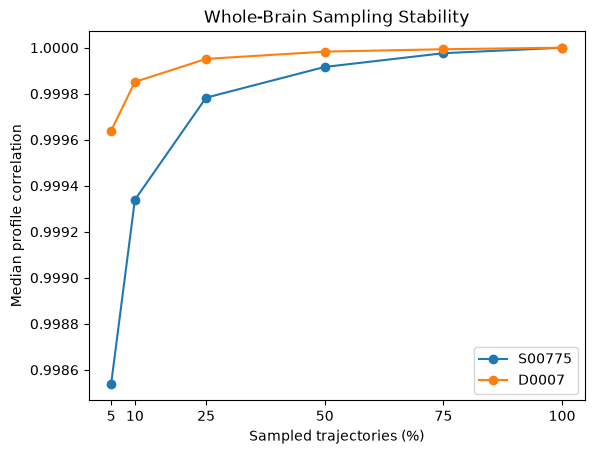

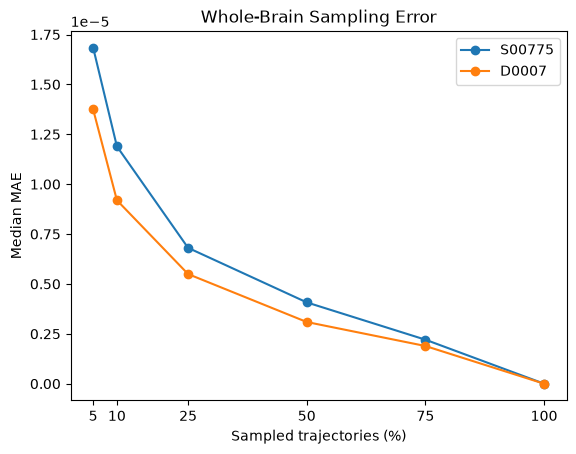

In [ ]:
plot_df = main_summary_df.copy()

plot_df["sampling_percent"] = (
    plot_df["sampling_fraction"] * 100
)


# Correlation

for subject in MAIN_SUBJECTS:

    subject_df = plot_df[
        plot_df["subject"] == subject
    ].sort_values(
        "sampling_fraction"
    )

    plt.plot(
        subject_df["sampling_percent"],
        subject_df["median_correlation"],
        marker="o",
        label=subject,
    )

plt.xlabel("Sampled trajectories (%)")
plt.ylabel("Median profile correlation")
plt.title("Whole-Brain Sampling Stability")
plt.xticks([5, 10, 25, 50, 75, 100])
plt.legend(frameon=True, facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)
plt.show()


# MAE

for subject in MAIN_SUBJECTS:

    subject_df = plot_df[
        plot_df["subject"] == subject
    ].sort_values(
        "sampling_fraction"
    )

    plt.plot(
        subject_df["sampling_percent"],
        subject_df["median_mae"],
        marker="o",
        label=subject,
    )

plt.xlabel("Sampled trajectories (%)")
plt.ylabel("Median MAE")
plt.title("Whole-Brain Sampling Error")
plt.xticks([5, 10, 25, 50, 75, 100])
plt.legend(frameon=True, facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)
plt.show()


## Trajectory–Profile Index Consistency Check

Before testing spatial sampling strategies, verify that the number and ordering of trajectories are consistent with the rows in the regional ADC profile files.

In [ ]:
from scipy.io import loadmat

subject = "D0007"
hemisphere = "lh"
region = "bankssts"

profile_file = (
    PATHS[subject]["profile_dir"]
    / f"{subject}_{hemisphere}_{region}_adc.csv"
)

trajectory_file = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/"
    "new_pipeline/D0007/analysis/trajectories/"
    "D0007_trajectory_lh.mat"
)

profile = load_profile(profile_file)
trajectory_data = loadmat(trajectory_file)

print("Profile shape:")
print(profile.shape)

print("\nTrajectory MAT variables:")
for key, value in trajectory_data.items():
    if not key.startswith("__"):
        print(key, value.shape)

Profile shape:
(1201, 21)

Trajectory MAT variables:
lh_trajectory_points (2525271, 3)


In [ ]:
regions_dir = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/"
    "new_pipeline/D0007/analysis/regions"
)

for file_path in sorted(regions_dir.glob("*"))[:30]:
    print(file_path.name)

lh_bankssts.csv
lh_bankssts.mat
lh_caudalanteriorcingulate.csv
lh_caudalanteriorcingulate.mat
lh_caudalmiddlefrontal.csv
lh_caudalmiddlefrontal.mat
lh_cuneus.csv
lh_cuneus.mat
lh_entorhinal.csv
lh_entorhinal.mat
lh_frontalpole.csv
lh_frontalpole.mat
lh_fusiform.csv
lh_fusiform.mat
lh_inferiorparietal.csv
lh_inferiorparietal.mat
lh_inferiortemporal.csv
lh_inferiortemporal.mat
lh_insula.csv
lh_insula.mat
lh_isthmuscingulate.csv
lh_isthmuscingulate.mat
lh_lateraloccipital.csv
lh_lateraloccipital.mat
lh_lateralorbitofrontal.csv
lh_lateralorbitofrontal.mat
lh_lingual.csv
lh_lingual.mat
lh_medialorbitofrontal.csv
lh_medialorbitofrontal.mat


In [ ]:
region_mat = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/"
    "new_pipeline/D0007/analysis/regions/"
    "lh_bankssts.mat"
)

region_csv = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/"
    "new_pipeline/D0007/analysis/regions/"
    "lh_bankssts.csv"
)

region_data = loadmat(region_mat)

print("Region MAT variables:")
for key, value in region_data.items():
    if not key.startswith("__"):
        print(key, value.shape)

print("\nRegion CSV shape:")
region_coordinates = np.loadtxt(
    region_csv,
    delimiter=","
)
print(region_coordinates.shape)

print("\nADC profile shape:")
print(profile.shape)

Region MAT variables:
lh_trajectory_dwi (4, 25221)

Region CSV shape:
(4, 25221)

ADC profile shape:
(1201, 21)


In [ ]:
trajectory_dwi = region_data["lh_trajectory_dwi"]

# Check homogeneous-coordinate row
print(
    "Fourth-row unique values:",
    np.unique(trajectory_dwi[3])
)

# Keep XYZ coordinates
trajectory_xyz = trajectory_dwi[:3, :].T

# Reshape:
# trajectory × depth × xyz
trajectory_xyz = trajectory_xyz.reshape(
    profile.shape[0],
    profile.shape[1],
    3,
)

print("Trajectory coordinates:")
print(trajectory_xyz.shape)

print("\nADC profiles:")
print(profile.shape)

Fourth-row unique values: [1.]
Trajectory coordinates:
(1201, 21, 3)

ADC profiles:
(1201, 21)


In [ ]:
# Use the middle depth point as the spatial location of each trajectory
trajectory_centers = trajectory_xyz[:, 10, :]

SPATIAL_TEST_FRACTIONS = [
    0.05,
    0.10,
    0.25,
]

N_SPATIAL_REPEATS = 100

full_profile = profile.mean(axis=0)


def farthest_point_sampling(points, sample_n, rng):
    n_points = len(points)

    first = rng.integers(n_points)

    selected = [first]

    min_distances = np.linalg.norm(
        points - points[first],
        axis=1,
    )

    for _ in range(1, sample_n):

        next_index = np.argmax(min_distances)

        selected.append(next_index)

        new_distances = np.linalg.norm(
            points - points[next_index],
            axis=1,
        )

        min_distances = np.minimum(
            min_distances,
            new_distances,
        )

    return np.array(selected)


strategy_results = []

rng_strategy = np.random.default_rng(
    RANDOM_SEED
)

for fraction in SPATIAL_TEST_FRACTIONS:

    sample_n = max(
        1,
        round(len(profile) * fraction),
    )

    for repeat in range(N_SPATIAL_REPEATS):

        # Random sampling
        random_indices = rng_strategy.choice(
            len(profile),
            size=sample_n,
            replace=False,
        )

        random_profile = profile[
            random_indices
        ].mean(axis=0)

        mae, rmse, correlation = compare_profiles(
            random_profile,
            full_profile,
        )

        strategy_results.append(
            {
                "strategy": "Random",
                "sampling_fraction": fraction,
                "sample_n": sample_n,
                "repeat": repeat + 1,
                "mae": mae,
                "rmse": rmse,
                "correlation": correlation,
            }
        )

        # Spatially distributed sampling
        spatial_indices = farthest_point_sampling(
            trajectory_centers,
            sample_n,
            rng_strategy,
        )

        spatial_profile = profile[
            spatial_indices
        ].mean(axis=0)

        mae, rmse, correlation = compare_profiles(
            spatial_profile,
            full_profile,
        )

        strategy_results.append(
            {
                "strategy": "Spatial",
                "sampling_fraction": fraction,
                "sample_n": sample_n,
                "repeat": repeat + 1,
                "mae": mae,
                "rmse": rmse,
                "correlation": correlation,
            }
        )


strategy_results_df = pd.DataFrame(
    strategy_results
)


strategy_summary_df = (
    strategy_results_df
    .groupby(
        [
            "strategy",
            "sampling_fraction",
        ]
    )
    .agg(
        sample_n=("sample_n", "first"),
        median_correlation=("correlation", "median"),
        p10_correlation=("correlation", lambda x: x.quantile(0.10)),
        median_mae=("mae", "median"),
        median_rmse=("rmse", "median"),
    )
    .reset_index()
)

strategy_summary_df

,strategy,sampling_fraction,sample_n,median_correlation,p10_correlation,median_mae,median_rmse
0,Random,0.05,60,0.999140,0.995535,0.000018,0.000023
1,Random,0.10,120,0.999558,0.998118,0.000014,0.000017
2,Random,0.25,300,0.999862,0.999496,0.000006,0.000008
3,Spatial,0.05,60,0.999528,0.998035,0.000014,0.000018
4,Spatial,0.10,120,0.999825,0.999413,0.000012,0.000015
5,Spatial,0.25,300,0.999933,0.999822,0.000009,0.000011


In [ ]:
TEST_REGIONS = [
    "entorhinal",
    "frontalpole",
    "temporalpole",
    "bankssts",
    "inferiorparietal",
]

TEST_HEMISPHERE = "lh"

SPATIAL_TEST_FRACTIONS = [
    0.05,
    0.10,
    0.25,
]

N_SPATIAL_REPEATS = 100

strategy_region_results = []

regions_dir = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/"
    "new_pipeline/D0007/analysis/regions"
)

profiles_dir = PATHS["D0007"]["profile_dir"]

rng_strategy = np.random.default_rng(
    RANDOM_SEED
)


for region in TEST_REGIONS:

    region_mat = (
        regions_dir
        / f"{TEST_HEMISPHERE}_{region}.mat"
    )

    profile_file = (
        profiles_dir
        / f"D0007_{TEST_HEMISPHERE}_{region}_adc.csv"
    )

    region_data = loadmat(region_mat)

    trajectory_dwi = region_data[
        f"{TEST_HEMISPHERE}_trajectory_dwi"
    ]

    profile = load_profile(profile_file)

    # XYZ coordinates
    trajectory_xyz = (
        trajectory_dwi[:3, :]
        .T
        .reshape(
            profile.shape[0],
            profile.shape[1],
            3,
        )
    )

    # Middle-depth coordinate represents each trajectory
    trajectory_centers = trajectory_xyz[:, 10, :]

    full_profile = profile.mean(axis=0)

    for fraction in SPATIAL_TEST_FRACTIONS:

        sample_n = max(
            1,
            round(len(profile) * fraction),
        )

        for repeat in range(N_SPATIAL_REPEATS):

            # Random
            random_indices = rng_strategy.choice(
                len(profile),
                size=sample_n,
                replace=False,
            )

            random_profile = profile[
                random_indices
            ].mean(axis=0)

            mae, rmse, correlation = compare_profiles(
                random_profile,
                full_profile,
            )

            strategy_region_results.append(
                {
                    "region": region,
                    "strategy": "Random",
                    "sampling_fraction": fraction,
                    "sample_n": sample_n,
                    "repeat": repeat + 1,
                    "mae": mae,
                    "rmse": rmse,
                    "correlation": correlation,
                }
            )

            # Spatial
            spatial_indices = farthest_point_sampling(
                trajectory_centers,
                sample_n,
                rng_strategy,
            )

            spatial_profile = profile[
                spatial_indices
            ].mean(axis=0)

            mae, rmse, correlation = compare_profiles(
                spatial_profile,
                full_profile,
            )

            strategy_region_results.append(
                {
                    "region": region,
                    "strategy": "Spatial",
                    "sampling_fraction": fraction,
                    "sample_n": sample_n,
                    "repeat": repeat + 1,
                    "mae": mae,
                    "rmse": rmse,
                    "correlation": correlation,
                }
            )


strategy_region_results_df = pd.DataFrame(
    strategy_region_results
)


strategy_region_summary_df = (
    strategy_region_results_df
    .groupby(
        [
            "region",
            "strategy",
            "sampling_fraction",
        ]
    )
    .agg(
        sample_n=("sample_n", "first"),
        median_correlation=("correlation", "median"),
        p10_correlation=("correlation", lambda x: x.quantile(0.10)),
        median_mae=("mae", "median"),
    )
    .reset_index()
)

strategy_region_summary_df

,region,strategy,sampling_fraction,sample_n,median_correlation,p10_correlation,median_mae
0,bankssts,Random,0.05,60,0.998778,0.996175,0.000017
1,bankssts,Random,0.10,120,0.999511,0.998020,0.000012
2,bankssts,Random,0.25,300,0.999855,0.999443,0.000007
3,bankssts,Spatial,0.05,60,0.999584,0.998492,0.000013
4,bankssts,Spatial,0.10,120,0.999821,0.999434,0.000010
5,bankssts,Spatial,0.25,300,0.999945,0.999821,0.000009
6,entorhinal,Random,0.05,33,0.994729,0.981224,0.000045
7,entorhinal,Random,0.10,66,0.997905,0.990126,0.000030
8,entorhinal,Random,0.25,166,0.999342,0.997496,0.000017
9,entorhinal,Spatial,0.05,33,0.996624,0.988461,0.000032


In [ ]:
strategy_comparison_df = (
    strategy_region_summary_df
    .pivot(
        index=["region", "sampling_fraction", "sample_n"],
        columns="strategy",
        values=[
            "median_correlation",
            "p10_correlation",
            "median_mae",
        ],
    )
)

strategy_comparison_df.columns = [
    f"{metric}_{strategy.lower()}"
    for metric, strategy in strategy_comparison_df.columns
]

strategy_comparison_df = (
    strategy_comparison_df
    .reset_index()
    .sort_values(
        ["region", "sampling_fraction"]
    )
)

strategy_comparison_df["sampling_percent"] = (
    strategy_comparison_df["sampling_fraction"] * 100
)

strategy_comparison_df

,region,sampling_fraction,sample_n,median_correlation_random,median_correlation_spatial,p10_correlation_random,p10_correlation_spatial,median_mae_random,median_mae_spatial,sampling_percent
0,bankssts,0.05,60,0.998778,0.999584,0.996175,0.998492,0.000017,0.000013,5.0
1,bankssts,0.10,120,0.999511,0.999821,0.998020,0.999434,0.000012,0.000010,10.0
2,bankssts,0.25,300,0.999855,0.999945,0.999443,0.999821,0.000007,0.000009,25.0
3,entorhinal,0.05,33,0.994729,0.996624,0.981224,0.988461,0.000045,0.000032,5.0
4,entorhinal,0.10,66,0.997905,0.999131,0.990126,0.998024,0.000030,0.000019,10.0
5,entorhinal,0.25,166,0.999342,0.999814,0.997496,0.999405,0.000017,0.000009,25.0
6,frontalpole,0.05,16,0.996730,0.997411,0.982915,0.992132,0.000036,0.000018,5.0
7,frontalpole,0.10,32,0.998071,0.998326,0.990868,0.996155,0.000026,0.000018,10.0
8,frontalpole,0.25,80,0.999397,0.998914,0.997319,0.997960,0.000015,0.000018,25.0
9,inferiorparietal,0.05,276,0.999817,0.999928,0.999221,0.999648,0.000011,0.000012,5.0


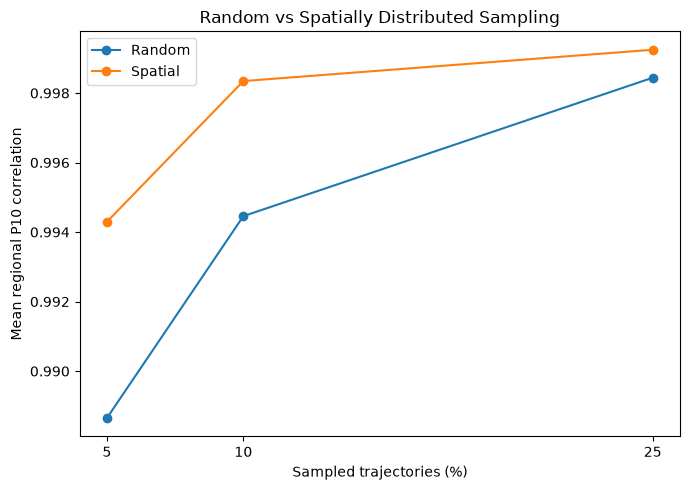

In [ ]:
strategy_overall_df = (
    strategy_comparison_df
    .groupby("sampling_percent")
    .agg(
        random_p10=("p10_correlation_random", "mean"),
        spatial_p10=("p10_correlation_spatial", "mean"),
    )
    .reset_index()
)

plt.figure(figsize=(7, 5))

plt.plot(
    strategy_overall_df["sampling_percent"],
    strategy_overall_df["random_p10"],
    marker="o",
    label="Random",
)

plt.plot(
    strategy_overall_df["sampling_percent"],
    strategy_overall_df["spatial_p10"],
    marker="o",
    label="Spatial",
)

plt.xticks([5, 10, 25])

plt.xlabel("Sampled trajectories (%)")
plt.ylabel("Mean regional P10 correlation")
plt.title("Random vs Spatially Distributed Sampling")

plt.legend(frameon=True, facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)
plt.tight_layout()
plt.show()

In [ ]:
strategy_overall_df = (
    strategy_region_results_df
    .groupby(
        [
            "strategy",
            "sampling_fraction",
        ]
    )
    .agg(
        median_correlation=(
            "correlation",
            "median",
        ),
        p10_correlation=(
            "correlation",
            lambda x: x.quantile(0.10),
        ),
        median_mae=(
            "mae",
            "median",
        ),
    )
    .reset_index()
)

strategy_overall_df["sampling_percent"] = (
    strategy_overall_df["sampling_fraction"] * 100
)

strategy_overall_df

,strategy,sampling_fraction,median_correlation,p10_correlation,median_mae,sampling_percent
0,Random,0.05,0.998265,0.987659,0.000029,5.0
1,Random,0.10,0.999067,0.993679,0.000019,10.0
2,Random,0.25,0.999737,0.998293,0.000011,25.0
3,Spatial,0.05,0.998734,0.993252,0.000020,5.0
4,Spatial,0.10,0.999512,0.997853,0.000016,10.0
5,Spatial,0.25,0.999815,0.998897,0.000012,25.0


## Whole-Brain Random vs Spatial Sampling

Random trajectory sampling is compared with spatially distributed sampling across all 68 cortical regions in D0007.

Each trajectory is represented by its middle-depth coordinate. Spatially distributed trajectories are selected using farthest-point sampling.

Both strategies use the same number of trajectories at each sampling fraction and are compared with the full 21-point regional ADC profile.

In [ ]:
from pathlib import Path
from scipy.io import loadmat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


SUBJECT = "D0007"

REGIONS_DIR = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/"
    "new_pipeline/D0007/analysis/regions"
)

PROFILE_DIR = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/"
    "new_pipeline/D0007/analysis/profiles"
)

SPATIAL_TEST_FRACTIONS = [
    0.05,
    0.10,
    0.25,
    0.50,
    0.75,
]

N_SPATIAL_REPEATS = 100
RANDOM_SEED = 42


def load_profile(file_path):
    values = np.loadtxt(
        file_path,
        delimiter=",",
    )

    if values.ndim == 1:
        values = values.reshape(1, -1)

    return values


def compare_profiles(sample_profile, full_profile):
    mae = np.mean(
        np.abs(sample_profile - full_profile)
    )

    rmse = np.sqrt(
        np.mean(
            (sample_profile - full_profile) ** 2
        )
    )

    if (
        np.std(sample_profile) == 0
        or np.std(full_profile) == 0
    ):
        correlation = np.nan
    else:
        correlation = np.corrcoef(
            sample_profile,
            full_profile,
        )[0, 1]

    return mae, rmse, correlation


def farthest_point_sampling(
    points,
    sample_n,
    rng,
):
    n_points = len(points)

    if sample_n >= n_points:
        return np.arange(n_points)

    first_index = rng.integers(
        0,
        n_points,
    )

    selected = [first_index]

    min_distances = np.linalg.norm(
        points - points[first_index],
        axis=1,
    )

    min_distances[first_index] = -np.inf

    for _ in range(1, sample_n):

        next_index = np.argmax(
            min_distances
        )

        selected.append(next_index)

        new_distances = np.linalg.norm(
            points - points[next_index],
            axis=1,
        )

        min_distances = np.minimum(
            min_distances,
            new_distances,
        )

        min_distances[selected] = -np.inf

    return np.array(
        selected,
        dtype=int,
    )


# Check region files
region_files = []

for hemisphere in ["lh", "rh"]:

    hemisphere_files = sorted(
        REGIONS_DIR.glob(
            f"{hemisphere}_*.mat"
        )
    )

    region_files.extend(
        hemisphere_files
    )

print(
    "Number of region files:",
    len(region_files),
)

print(
    "Expected:",
    68,
)


# Run whole-brain sampling comparison
strategy_all_results = []

rng = np.random.default_rng(
    RANDOM_SEED
)


for hemisphere in ["lh", "rh"]:

    hemisphere_region_files = sorted(
        REGIONS_DIR.glob(
            f"{hemisphere}_*.mat"
        )
    )

    for region_mat in hemisphere_region_files:

        region = region_mat.stem.replace(
            f"{hemisphere}_",
            "",
        )

        profile_file = (
            PROFILE_DIR
            / f"{SUBJECT}_{hemisphere}_{region}_adc.csv"
        )

        if not profile_file.exists():

            print(
                "Missing profile:",
                profile_file.name,
            )

            continue


        profile = load_profile(
            profile_file
        )


        region_data = loadmat(
            region_mat
        )

        trajectory_key = (
            f"{hemisphere}_trajectory_dwi"
        )

        if trajectory_key not in region_data:

            print(
                "Missing trajectory variable:",
                region_mat.name,
            )

            continue


        trajectory_dwi = region_data[
            trajectory_key
        ]


        expected_points = (
            profile.shape[0]
            * profile.shape[1]
        )

        if (
            trajectory_dwi.shape[1]
            != expected_points
        ):

            print(
                "Shape mismatch:",
                hemisphere,
                region,
                trajectory_dwi.shape,
                profile.shape,
            )

            continue


        # trajectory × depth × xyz
        trajectory_xyz = (
            trajectory_dwi[:3, :]
            .T
            .reshape(
                profile.shape[0],
                profile.shape[1],
                3,
            )
        )


        # Middle-depth location
        trajectory_centers = (
            trajectory_xyz[:, 10, :]
        )


        # Full regional ADC profile
        full_profile = profile.mean(
            axis=0
        )


        total_trajectories = len(
            profile
        )


        for fraction in SPATIAL_TEST_FRACTIONS:

            sample_n = max(
                1,
                round(
                    total_trajectories
                    * fraction
                ),
            )


            for repeat in range(
                N_SPATIAL_REPEATS
            ):


                # Random sampling
                random_indices = rng.choice(
                    total_trajectories,
                    size=sample_n,
                    replace=False,
                )

                random_profile = (
                    profile[
                        random_indices
                    ]
                    .mean(axis=0)
                )

                (
                    random_mae,
                    random_rmse,
                    random_correlation,
                ) = compare_profiles(
                    random_profile,
                    full_profile,
                )

                strategy_all_results.append(
                    {
                        "subject": SUBJECT,
                        "hemisphere": hemisphere,
                        "region": region,
                        "strategy": "Random",
                        "sampling_fraction": fraction,
                        "sampling_percent": fraction * 100,
                        "total_trajectories": total_trajectories,
                        "sample_n": sample_n,
                        "repeat": repeat + 1,
                        "mae": random_mae,
                        "rmse": random_rmse,
                        "correlation": random_correlation,
                    }
                )


                # Spatial sampling
                spatial_indices = (
                    farthest_point_sampling(
                        trajectory_centers,
                        sample_n,
                        rng,
                    )
                )

                spatial_profile = (
                    profile[
                        spatial_indices
                    ]
                    .mean(axis=0)
                )

                (
                    spatial_mae,
                    spatial_rmse,
                    spatial_correlation,
                ) = compare_profiles(
                    spatial_profile,
                    full_profile,
                )

                strategy_all_results.append(
                    {
                        "subject": SUBJECT,
                        "hemisphere": hemisphere,
                        "region": region,
                        "strategy": "Spatial",
                        "sampling_fraction": fraction,
                        "sampling_percent": fraction * 100,
                        "total_trajectories": total_trajectories,
                        "sample_n": sample_n,
                        "repeat": repeat + 1,
                        "mae": spatial_mae,
                        "rmse": spatial_rmse,
                        "correlation": spatial_correlation,
                    }
                )


strategy_all_results_df = pd.DataFrame(
    strategy_all_results
)


print(
    "\nRepeat-level results:"
)

print(
    strategy_all_results_df.shape
)

strategy_all_results_df.head()

Number of region files: 68
Expected: 68

Repeat-level results:
(68000, 12)


,subject,hemisphere,region,strategy,sampling_fraction,sampling_percent,total_trajectories,sample_n,repeat,mae,rmse,correlation
0,D0007,lh,bankssts,Random,0.05,5.0,1201,60,1,0.000008,0.000010,0.999428
1,D0007,lh,bankssts,Spatial,0.05,5.0,1201,60,1,0.000015,0.000016,0.999511
2,D0007,lh,bankssts,Random,0.05,5.0,1201,60,2,0.000019,0.000023,0.999459
3,D0007,lh,bankssts,Spatial,0.05,5.0,1201,60,2,0.000005,0.000006,0.999814
4,D0007,lh,bankssts,Random,0.05,5.0,1201,60,3,0.000017,0.000021,0.997207


In [ ]:
strategy_region_summary_df = (
    strategy_all_results_df
    .groupby(
        [
            "hemisphere",
            "region",
            "strategy",
            "sampling_fraction",
            "sampling_percent",
        ]
    )
    .agg(
        sample_n=(
            "sample_n",
            "first",
        ),
        median_correlation=(
            "correlation",
            "median",
        ),
        p10_correlation=(
            "correlation",
            lambda x: x.quantile(0.10),
        ),
        median_mae=(
            "mae",
            "median",
        ),
        median_rmse=(
            "rmse",
            "median",
        ),
    )
    .reset_index()
)


print(
    "Region-level summary:"
)

print(
    strategy_region_summary_df.shape
)

strategy_region_summary_df.head()

Region-level summary:
(680, 10)


,hemisphere,region,strategy,sampling_fraction,sampling_percent,sample_n,median_correlation,p10_correlation,median_mae,median_rmse
0,lh,bankssts,Random,0.05,5.0,60,0.999140,0.995535,0.000018,0.000023
1,lh,bankssts,Random,0.10,10.0,120,0.999558,0.998118,0.000014,0.000017
2,lh,bankssts,Random,0.25,25.0,300,0.999862,0.999496,0.000006,0.000008
3,lh,bankssts,Random,0.50,50.0,600,0.999951,0.999788,0.000004,0.000005
4,lh,bankssts,Random,0.75,75.0,901,0.999986,0.999951,0.000002,0.000002


In [ ]:
strategy_whole_brain_df = (
    strategy_region_summary_df
    .groupby(
        [
            "strategy",
            "sampling_fraction",
            "sampling_percent",
        ]
    )
    .agg(
        n_regions=(
            "region",
            "count",
        ),

        median_region_correlation=(
            "median_correlation",
            "median",
        ),

        median_region_p10=(
            "p10_correlation",
            "median",
        ),

        p10_region_p10=(
            "p10_correlation",
            lambda x: x.quantile(0.10),
        ),

        median_region_mae=(
            "median_mae",
            "median",
        ),

        median_region_rmse=(
            "median_rmse",
            "median",
        ),
    )
    .reset_index()
)

strategy_whole_brain_df

,strategy,sampling_fraction,sampling_percent,n_regions,median_region_correlation,median_region_p10,p10_region_p10,median_region_mae,median_region_rmse
0,Random,0.05,5.0,68,0.999667,0.998700,0.992481,0.000014,0.000016
1,Random,0.10,10.0,68,0.999841,0.999356,0.996594,0.000010,0.000011
2,Random,0.25,25.0,68,0.999948,0.999800,0.998774,0.000006,0.000006
3,Random,0.50,50.0,68,0.999985,0.999936,0.999595,0.000003,0.000004
4,Random,0.75,75.0,68,0.999994,0.999976,0.999850,0.000002,0.000002
5,Spatial,0.05,5.0,68,0.999725,0.999167,0.994056,0.000013,0.000015
6,Spatial,0.10,10.0,68,0.999888,0.999684,0.997672,0.000011,0.000013
7,Spatial,0.25,25.0,68,0.999923,0.999832,0.998551,0.000008,0.000010
8,Spatial,0.50,50.0,68,0.999873,0.999827,0.998641,0.000011,0.000013
9,Spatial,0.75,75.0,68,0.999956,0.999940,0.999161,0.000007,0.000009


In [ ]:
strategy_whole_brain_comparison_df = (
    strategy_whole_brain_df
    .pivot(
        index=[
            "sampling_fraction",
            "sampling_percent",
        ],
        columns="strategy",
        values=[
            "median_region_p10",
            "median_region_mae",
        ],
    )
)


strategy_whole_brain_comparison_df.columns = [
    f"{metric}_{strategy.lower()}"
    for metric, strategy
    in strategy_whole_brain_comparison_df.columns
]


strategy_whole_brain_comparison_df = (
    strategy_whole_brain_comparison_df
    .reset_index()
)


strategy_whole_brain_comparison_df[
    "p10_gain_spatial"
] = (
    strategy_whole_brain_comparison_df[
        "median_region_p10_spatial"
    ]
    -
    strategy_whole_brain_comparison_df[
        "median_region_p10_random"
    ]
)


strategy_whole_brain_comparison_df[
    "mae_change_spatial"
] = (
    strategy_whole_brain_comparison_df[
        "median_region_mae_spatial"
    ]
    -
    strategy_whole_brain_comparison_df[
        "median_region_mae_random"
    ]
)


strategy_whole_brain_comparison_df

,sampling_fraction,sampling_percent,median_region_p10_random,median_region_p10_spatial,median_region_mae_random,median_region_mae_spatial,p10_gain_spatial,mae_change_spatial
0,0.05,5.0,0.998700,0.999167,0.000014,0.000013,0.000467,-9.060379e-07
1,0.10,10.0,0.999356,0.999684,0.000010,0.000011,0.000328,1.264932e-06
2,0.25,25.0,0.999800,0.999832,0.000006,0.000008,0.000032,2.790431e-06
3,0.50,50.0,0.999936,0.999827,0.000003,0.000011,-0.000109,7.591824e-06
4,0.75,75.0,0.999976,0.999940,0.000002,0.000007,-0.000036,5.145157e-06


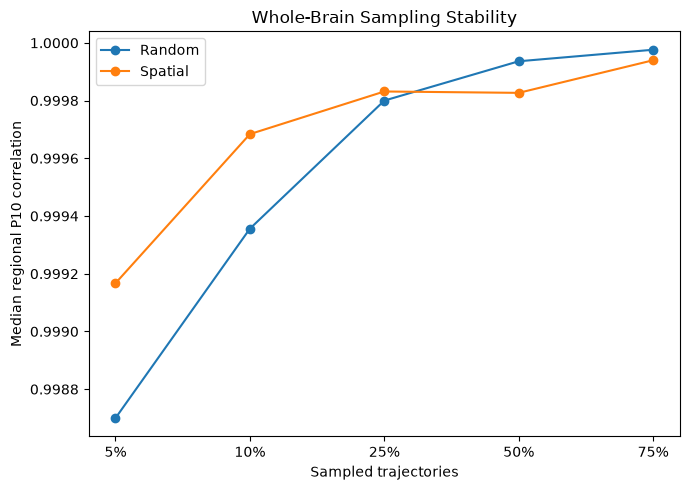

In [ ]:
sampling_levels = [
    5,
    10,
    25,
    50,
    75,
]

x = np.arange(
    len(sampling_levels)
)


plt.figure(
    figsize=(7, 5)
)


for strategy in [
    "Random",
    "Spatial",
]:

    plot_df = (
        strategy_whole_brain_df[
            strategy_whole_brain_df[
                "strategy"
            ] == strategy
        ]
        .sort_values(
            "sampling_percent"
        )
    )

    plt.plot(
        x,
        plot_df[
            "median_region_p10"
        ],
        marker="o",
        label=strategy,
    )


plt.xticks(
    x,
    [
        f"{level}%"
        for level in sampling_levels
    ],
)

plt.xlabel(
    "Sampled trajectories"
)

plt.ylabel(
    "Median regional P10 correlation"
)

plt.title(
    "Whole-Brain Sampling Stability"
)

plt.legend(frameon=True, facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)

plt.tight_layout()

plt.show()

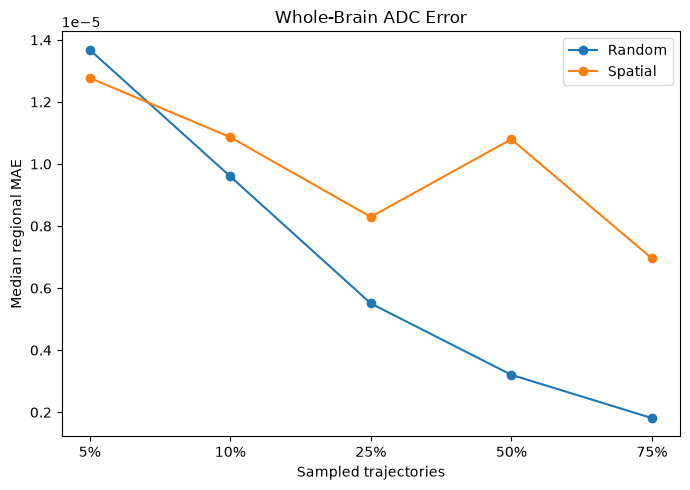

In [ ]:
plt.figure(
    figsize=(7, 5)
)


for strategy in [
    "Random",
    "Spatial",
]:

    plot_df = (
        strategy_whole_brain_df[
            strategy_whole_brain_df[
                "strategy"
            ] == strategy
        ]
        .sort_values(
            "sampling_percent"
        )
    )

    plt.plot(
        x,
        plot_df[
            "median_region_mae"
        ],
        marker="o",
        label=strategy,
    )


plt.xticks(
    x,
    [
        f"{level}%"
        for level in sampling_levels
    ],
)

plt.xlabel(
    "Sampled trajectories"
)

plt.ylabel(
    "Median regional MAE"
)

plt.title(
    "Whole-Brain ADC Error"
)

plt.legend(frameon=True, facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)

plt.tight_layout()

plt.show()